# Clasificación de Channel Spacing Haciendo Nested Cross-Validation 5×5 + predicciones outer-fold (OOF) + SHAP + tiempo de inferencia (IQ Hist)
## Primero para monitoreo asistido

## RDF 16GBd para clasificar SEPARACIÓN ESPECTRAL CON OSNR

CLASIFICACIÓN DE SEPARACIÓN ESPECTRAL - 16 GBd
RANDOM FOREST - MONITOREO ASISTIDO

Dataset: matriz16GBd_clas.csv
Forma matriz original: (243, 32)
Forma X: (243, 31)
Cantidad de muestras: 243

NORMAL (> 17.6 GHz): 63
ALARMA (<= 17.6 GHz): 180

Características utilizadas:
 1. I_peak1_x
 2. I_peak2_x
 3. I_peak3_x
 4. I_peak4_x
 5. I_peak1_y
 6. I_peak2_y
 7. I_peak3_y
 8. I_peak4_y
 9. Q_peak1_x
10. Q_peak2_x
11. Q_peak3_x
12. Q_peak4_x
13. Q_peak1_y
14. Q_peak2_y
15. Q_peak3_y
16. Q_peak4_y
17. I_valley1_x
18. I_valley2_x
19. I_valley3_x
20. I_valley1_y
21. I_valley2_y
22. I_valley3_y
23. Q_valley1_x
24. Q_valley2_x
25. Q_valley3_x
26. Q_valley1_y
27. Q_valley2_y
28. Q_valley3_y
29. I_broadening
30. Q_broadening
31. OSNR

MONITOREO ASISTIDO: OSNR incluido como predictor.
channel_sp excluido de X porque define la variable objetivo.

Combinaciones de hiperparámetros: 162

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Ejecutando G

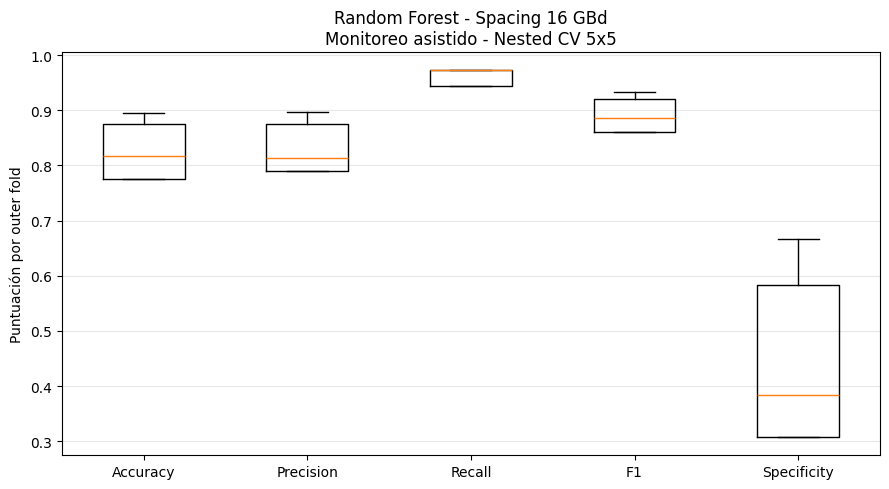


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8272
OOF Precision:   0.8317
OOF Recall:      0.9611
OOF F1 ALARMA:   0.8918
OOF Specificity: 0.4444

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.80      0.44      0.57        63
      ALARMA       0.83      0.96      0.89       180

    accuracy                           0.83       243
   macro avg       0.82      0.70      0.73       243
weighted avg       0.82      0.83      0.81       243


Matriz de confusión OOF absoluta:
[[ 28  35]
 [  7 173]]


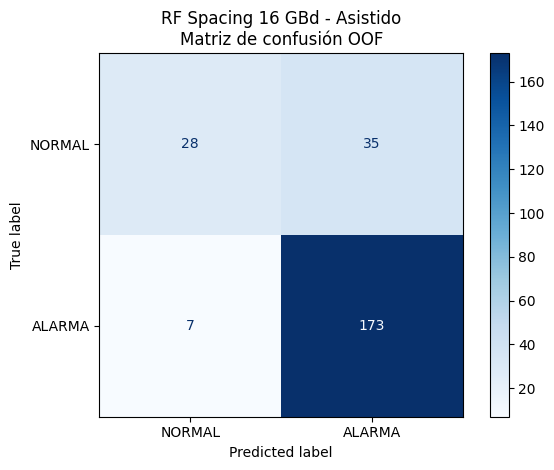


Matriz de confusión OOF normalizada:
[[0.44444444 0.55555556]
 [0.03888889 0.96111111]]


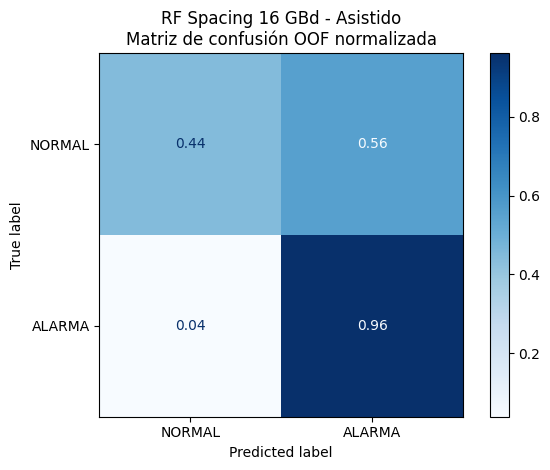


Predicciones OOF guardadas.

HIPERPARÁMETROS SELECCIONADOS POR OUTER FOLD
 fold  max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1
    1       10.0         sqrt                 1                  5           100          0.899885
    2        NaN         sqrt                 1                  5           200          0.895820
    3        NaN         sqrt                 1                  2           100          0.911494
    4        NaN         sqrt                 1                  5           100          0.897625
    5        NaN         sqrt                 1                  2           400          0.890876

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 70.299 µs/muestra
Inference Std:  39.188 µs/muestra
Mediciones totales: 500

La medición corresponde al tiempo promedio por muestra dentro de un batch.
No incluye carga del CSV, búsqueda de hiperparámetros ni entrenamiento.

ENTRENANDO MODELO FINAL - RANDOM FOREST

Mejores hiperpar

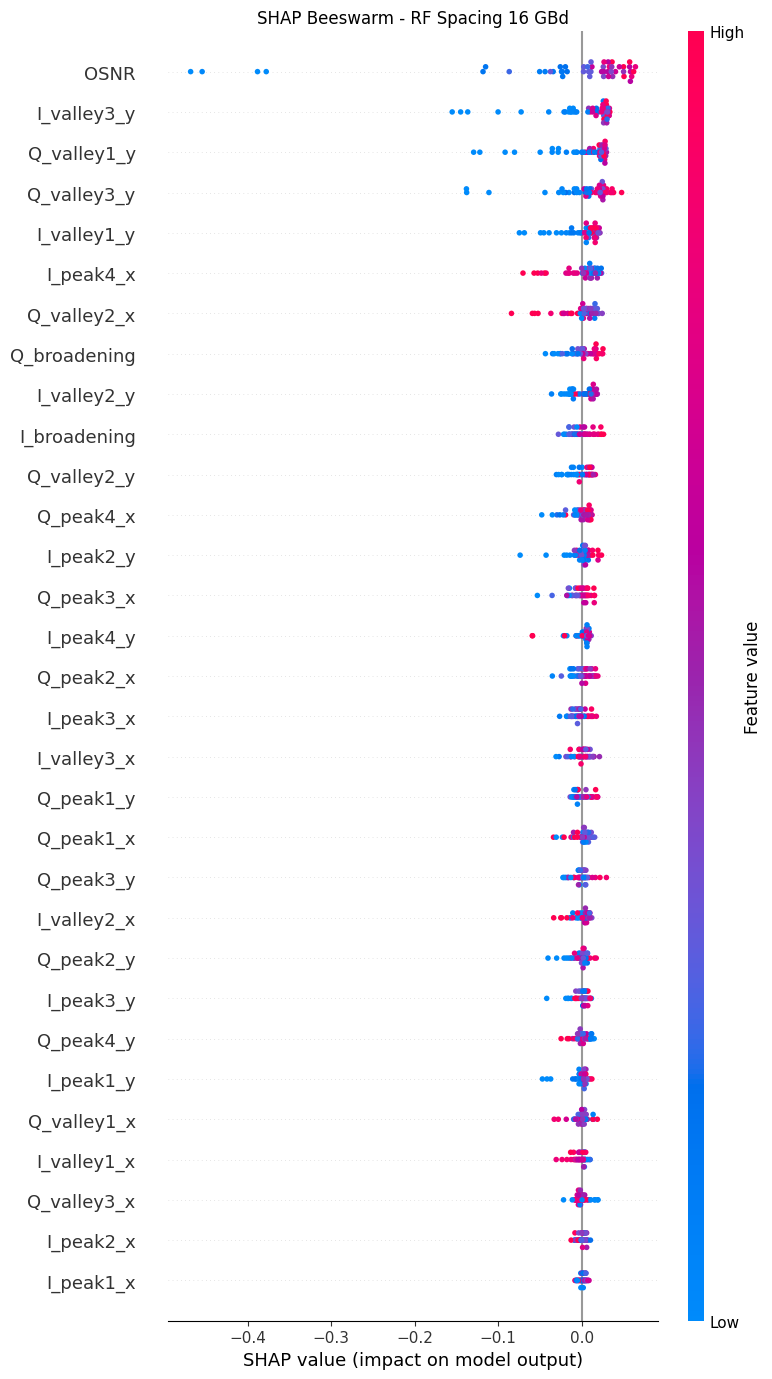

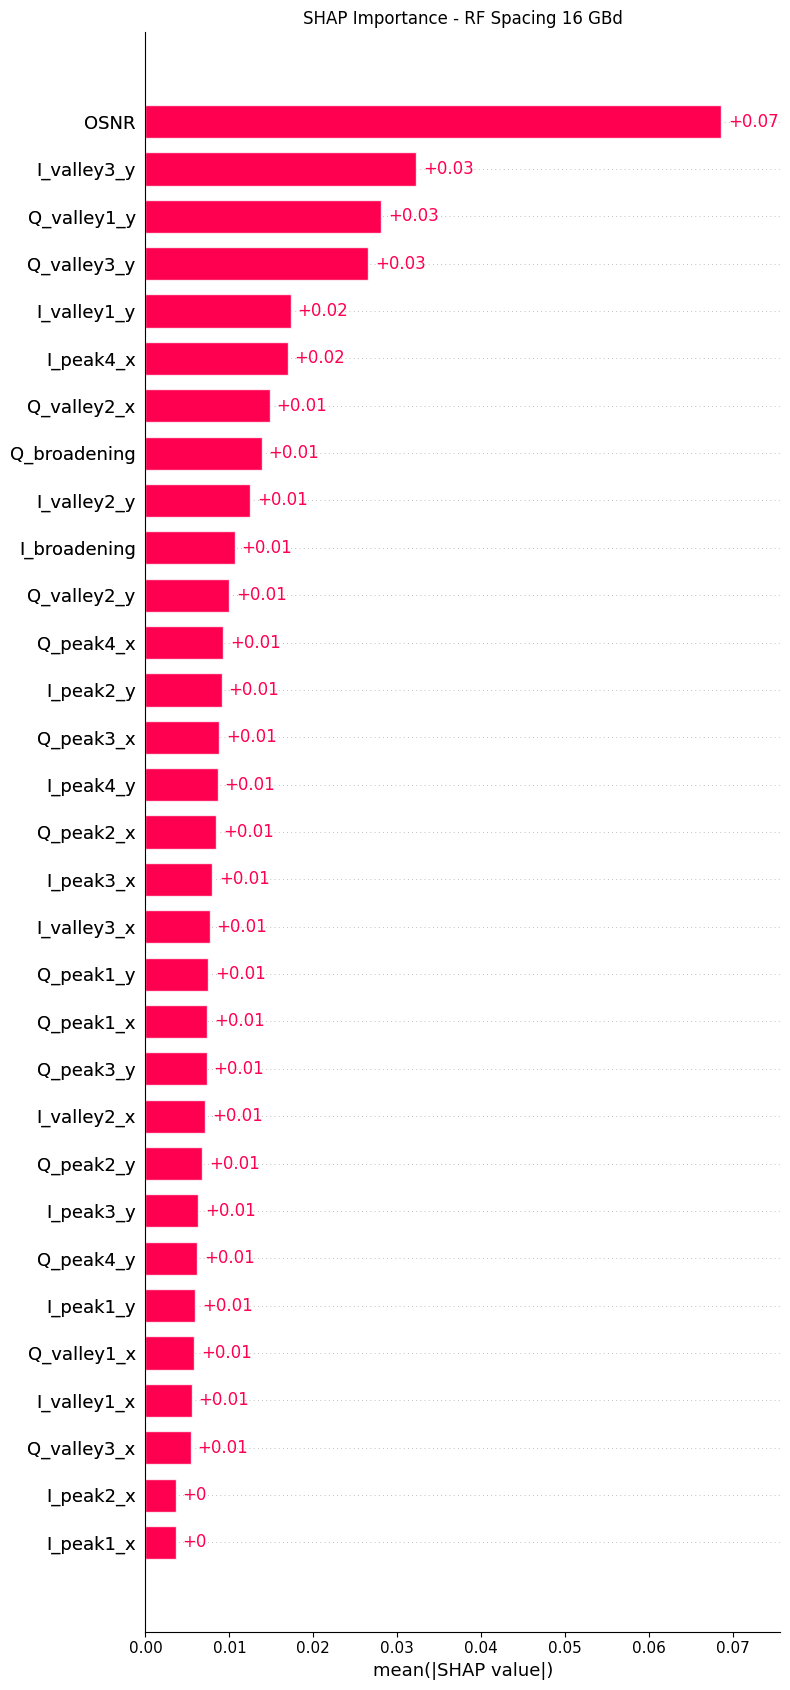

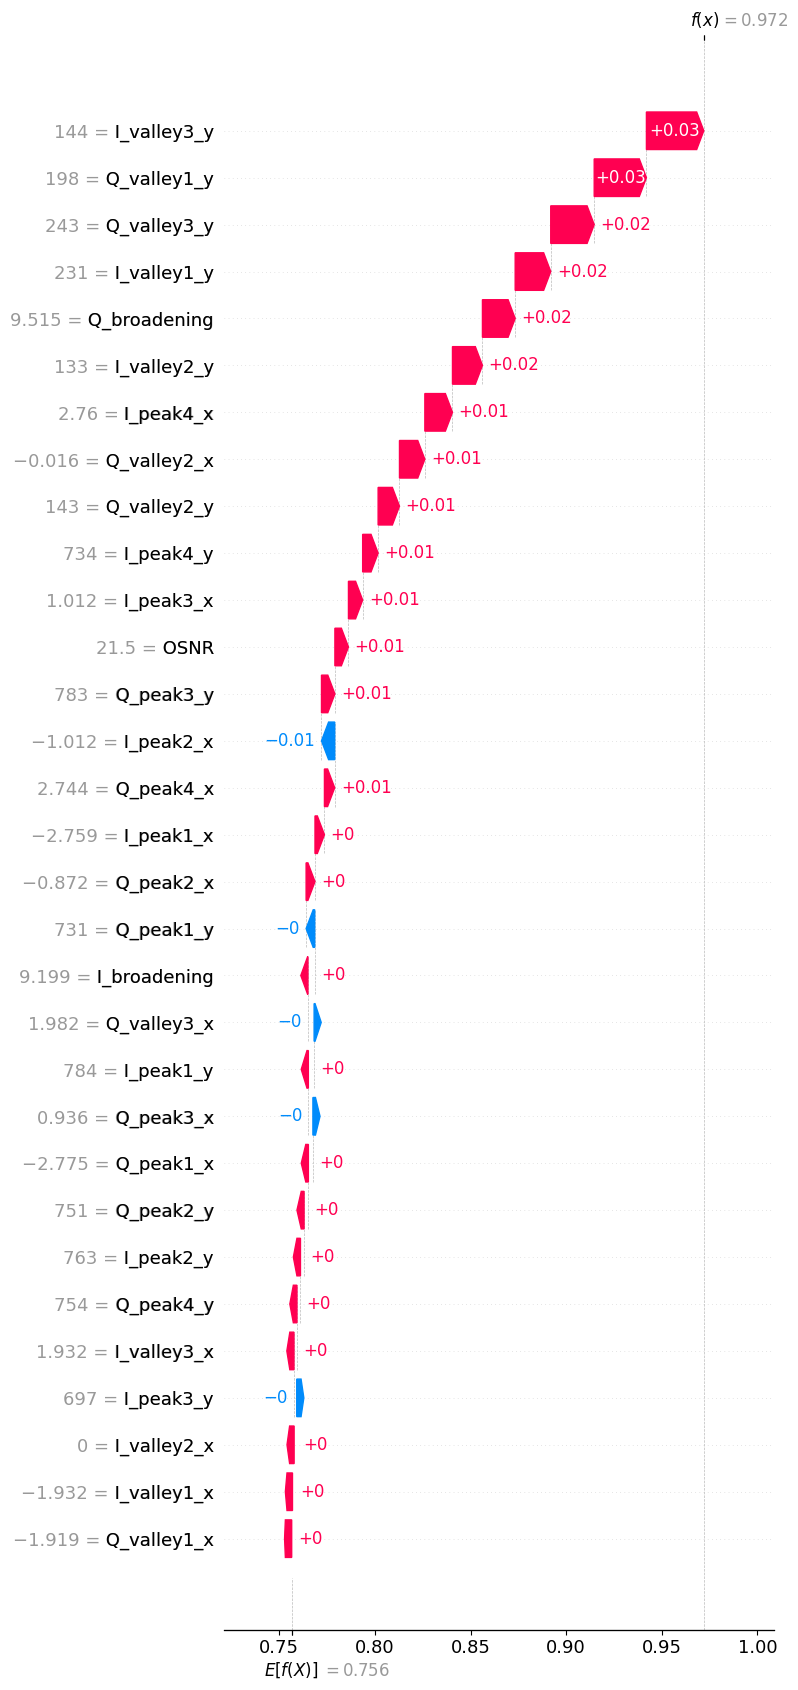


RESUMEN FINAL - RF SPACING 16 GBd
MONITOREO ASISTIDO - NESTED CV 5x5

OUTER CV (PROMEDIO ± STD):
ACCURACY    : 0.8276 ± 0.0499
PRECISION   : 0.8336 ± 0.0444
RECALL      : 0.9611 ± 0.0136
F1          : 0.8924 ± 0.0301
SPECIFICITY : 0.4500 ± 0.1480

MÉTRICAS GLOBALES OOF:
Accuracy:    0.8272
Precision:   0.8317
Recall:      0.9611
F1 ALARMA:   0.8918
Specificity: 0.4444

TIEMPO DE INFERENCIA:
70.299 ± 39.188 µs/muestra

SHAP:
Top feature: OSNR
Importancia relativa: 17.60%

ARCHIVOS GENERADOS:
1. rf_spacing_16GBd_asistido_nested_outer_folds.csv
2. rf_spacing_16GBd_asistido_nested_oof_predictions.csv
3. rf_spacing_16GBd_asistido_nested_best_params.csv
4. rf_spacing_16GBd_asistido_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
===============================================================
CLASIFICACIÓN DE SEPARACIÓN ESPECTRAL - 16 GBd
RANDOM FOREST - MONITOREO ASISTIDO
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OUTER-FOLD
===============================================================

OBJETIVO:
    Clasificar si la separación espectral entre canales
    es menor o igual al ancho de banda de referencia.

CLASES:
    0 = NORMAL: channel_sp > 17.6 GHz
    1 = ALARMA: channel_sp <= 17.6 GHz

MONITOREO ASISTIDO:
    Se utilizan:
        - 30 características de histogramas I/Q
        - OSNR como característica adicional

    Total: 31 características.

    channel_sp NO se utiliza como predictor,
    porque es la variable que queremos clasificar.

METODOLOGÍA:
    1. Outer CV estratificada de 5 folds.
    2. Inner CV estratificada de 5 folds.
    3. GridSearchCV dentro de cada outer train.
    4. Predicciones independientes en cada outer test.
    5. Construcción de predicciones Out-of-Fold (OOF).
    6. Métricas por outer fold y métricas OOF globales.
    7. Matrices de confusión absoluta y normalizada.
    8. Tiempo de inferencia por outer fold.
    9. Entrenamiento de un modelo final.
   10. Interpretabilidad mediante SHAP TreeExplainer.

IMPORTANTE:
    La validación se realiza por filas.
    Si varias filas pertenecen al mismo escenario experimental,
    puede ser preferible utilizar validación agrupada.
"""

# ============================================================
# 1. IMPORTAR LIBRERÍAS
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 2. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

# Umbral de separación espectral.
THRESHOLD_GHZ = 17.6

SEED = 42

# Nested CV 5x5
N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

# Repeticiones para medir el tiempo de inferencia.
N_REPETITIONS = 100

# Número de muestras para SHAP.
SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

# Prefijo para los archivos de salida.
OUTPUT_PREFIX = "rf_spacing_16GBd_asistido_nested"

# ============================================================
# 3. NOMBRES DE LAS 31 CARACTERÍSTICAS
# ============================================================

# 30 características de histogramas I/Q + OSNR.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "OSNR"]
)

assert len(feature_names) == 31

# ============================================================
# 4. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura esperada:
#
# Columnas 0-29:
#     30 características I/Q
#
# Columna 30:
#     channel_sp
#
# Columna 31:
#     OSNR

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas y "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 4.1 EXTRAER VARIABLE OBJETIVO
# ------------------------------------------------------------

# La penúltima columna contiene channel_sp.
y_spacing = matriz.iloc[:, 30].to_numpy()

# ------------------------------------------------------------
# 4.2 EXTRAER CARACTERÍSTICAS
# ------------------------------------------------------------

# Excluir channel_sp.
#
# Se conservan las 30 características I/Q
# y la última columna OSNR.

X = matriz.drop(
    columns=matriz.columns[30]
).copy()

X.columns = feature_names

# ------------------------------------------------------------
# 4.3 CONSTRUIR ETIQUETAS BINARIAS
# ------------------------------------------------------------

# NORMAL = 0 si spacing > 17.6 GHz
# ALARMA = 1 si spacing <= 17.6 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras de cada clase "
        "para los folds externos."
    )

# ============================================================
# 5. INFORMACIÓN DEL DATASET
# ============================================================

print("=" * 70)
print("CLASIFICACIÓN DE SEPARACIÓN ESPECTRAL - 16 GBd")
print("RANDOM FOREST - MONITOREO ASISTIDO")
print("=" * 70)

print(f"\nDataset: {CSV_PATH}")
print(f"Forma matriz original: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Cantidad de muestras: {n_samples}")

print(
    f"\nNORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print("\nCaracterísticas utilizadas:")

for i, feature in enumerate(feature_names, start=1):
    print(f"{i:2d}. {feature}")

print(
    "\nMONITOREO ASISTIDO: "
    "OSNR incluido como predictor."
)

print(
    "channel_sp excluido de X "
    "porque define la variable objetivo."
)

# ============================================================
# 6. DEFINIR RANDOM FOREST Y GRIDSEARCH
# ============================================================

def build_model():
    """
    Construye un Random Forest nuevo.

    Se utiliza n_jobs=1 dentro del modelo para evitar
    paralelismo anidado cuando GridSearchCV usa n_jobs=-1.

    Random Forest no requiere normalización de entradas.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )


# Se conserva el mismo grid del código original.

param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = (
    len(param_grid["n_estimators"]) *
    len(param_grid["max_depth"]) *
    len(param_grid["min_samples_split"]) *
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)

print("\nCombinaciones de hiperparámetros:", n_combinations)

# ============================================================
# 7. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# ------------------------------------------------------------
# 7.1 ESTRUCTURAS PARA PREDICCIONES OOF
# ------------------------------------------------------------

# Predicción de clase de cada muestra.
oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad de ALARMA de cada muestra.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Outer fold que evaluó cada muestra.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

# Resultados de cada fold.
outer_results = []

# Hiperparámetros seleccionados en cada fold.
outer_best_params = []

# Tiempos de inferencia por fold.
outer_inference_times = []

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 8. BUCLE PRINCIPAL: OUTER CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 8.1 DIVISIÓN EXTERNA
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 8.2 INNER CROSS-VALIDATION
    # --------------------------------------------------------

    # GridSearchCV solo utiliza el conjunto outer train.
    #
    # Cada outer fold tiene su propio proceso de
    # selección de hiperparámetros.

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_model(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    print("\nEjecutando GridSearchCV interno...")

    search.fit(
        X_outer_train,
        y_outer_train
    )

    # El mejor modelo ya fue reentrenado
    # sobre todo el outer train.

    best_rf = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Inner CV: "
        f"{search.best_score_:.4f}"
    )

    # Guardar parámetros del fold.
    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_
    })

    # --------------------------------------------------------
    # 8.3 PREDICCIONES EN EL OUTER TEST
    # --------------------------------------------------------

    # El outer test no participó en GridSearchCV.

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de ALARMA (clase 1).
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar resultados en la posición original
    # de cada muestra del dataset.

    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 8.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 8.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Primero se realiza una predicción de calentamiento.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    # Cada repetición mide el tiempo de predecir
    # todo el outer test.
    #
    # Se divide por el número de muestras
    # para obtener µs/muestra dentro del batch.

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 8.6 GUARDAR MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1 ALARMA:   {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 9. VERIFICAR PREDICCIONES OOF
# ============================================================

# Todas las muestras deben haber sido evaluadas
# exactamente una vez como parte de un outer test.

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Hay muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Hay muestras sin outer fold asignado."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Hay probabilidades OOF inválidas."
    )

print("\nPredicciones OOF completadas correctamente.")

# ============================================================
# 10. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS 5 OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 11. OUTER CV: PROMEDIO ± DESVIACIÓN ESTÁNDAR
# ============================================================

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 12. GRÁFICA DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "Random Forest - Spacing 16 GBd\n"
    "Monitoreo asistido - Nested CV 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 70)

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_oof.ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1 ALARMA:   {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 14. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

print("\nMatriz de confusión OOF absoluta:")

print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "RF Spacing 16 GBd - Asistido\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

# Normalización por clase verdadera.
# Cada fila representa una clase real.

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

print("\nMatriz de confusión OOF normalizada:")

print(cm_oof_norm)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "RF Spacing 16 GBd - Asistido\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 16. GUARDAR PREDICCIONES OOF
# ============================================================

# Cada fila conserva su índice original.
#
# Se incluye:
#   - spacing real en GHz
#   - clase verdadera
#   - clase predicha
#   - probabilidad estimada de ALARMA
#   - fold que realizó la predicción
#   - indicador de predicción correcta

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": matriz.iloc[:, 31].to_numpy(),
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": (
        y == oof_predictions
    )
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 17. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 70)
print("HIPERPARÁMETROS SELECCIONADOS POR OUTER FOLD")
print("=" * 70)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 18. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# Se combinan las 100 mediciones de cada fold:
#
# 5 folds x 100 repeticiones = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean = (
    all_inference_times.mean()
)

inference_std = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean:.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{inference_std:.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "\nLa medición corresponde al tiempo promedio "
    "por muestra dentro de un batch."
)

print(
    "No incluye carga del CSV, búsqueda de "
    "hiperparámetros ni entrenamiento."
)

# ============================================================
# 19. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# IMPORTANTE:
#
# Este modelo final se utiliza para SHAP.
#
# NO se utiliza para generar las predicciones OOF.
#
# Sus hiperparámetros se seleccionan mediante
# GridSearchCV usando todo el dataset.

print("\n" + "=" * 70)
print("ENTRENANDO MODELO FINAL - RANDOM FOREST")
print("=" * 70)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_model(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X, y)

final_rf = final_search.best_estimator_

print("\nMejores hiperparámetros modelo final:")

print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

# ============================================================
# 20. SHAP - TREEEXPLAINER
# ============================================================

# TreeExplainer calcula la contribución de cada
# característica a la probabilidad de ALARMA.
#
# SHAP positivo:
#     Aumenta P(ALARMA).
#
# SHAP negativo:
#     Disminuye P(ALARMA).
#
# Este SHAP corresponde al modelo final entrenado
# con todos los datos. NO es SHAP OOF.

print("\n" + "=" * 70)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# ============================================================
# 21. COMPATIBILIDAD CON VERSIONES DE SHAP
# ============================================================

# Según la versión instalada, SHAP puede devolver:
#
# 1. Una lista:
#       [SHAP_clase_0, SHAP_clase_1]
#
# 2. Un arreglo:
#       (muestras, características, clases)
#
# Se selecciona exclusivamente la clase 1 = ALARMA.

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if (
        arr.ndim == 3
        and arr.shape[2] == 2
    ):

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# Valor esperado de la clase ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

# ============================================================
# 22. IMPORTANCIA GLOBAL SHAP
# ============================================================

# Importancia de cada característica:
#
# mean(|SHAP|) sobre las muestras explicadas.

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n31 CARACTERÍSTICAS ORDENADAS POR SHAP:")

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 CARACTERÍSTICAS SHAP:")

print(
    imp_df.head(5).to_string(
        index=False
    )
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 23. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 24. GRÁFICAS SHAP
# ============================================================

# ------------------------------------------------------------
# 24.1 BEESWARM
# ------------------------------------------------------------

shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.title(
    "SHAP Beeswarm - RF Spacing 16 GBd"
)

plt.tight_layout()
plt.show()
plt.close()

# ------------------------------------------------------------
# 24.2 BAR PLOT
# ------------------------------------------------------------

shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.title(
    "SHAP Importance - RF Spacing 16 GBd"
)

plt.tight_layout()
plt.show()
plt.close()

# ------------------------------------------------------------
# 24.3 WATERFALL
# ------------------------------------------------------------

shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 25. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - RF SPACING 16 GBd")
print("MONITOREO ASISTIDO - NESTED CV 5x5")
print("=" * 70)

print("\nOUTER CV (PROMEDIO ± STD):")

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\nMÉTRICAS GLOBALES OOF:")

print(
    f"Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"Precision:   {oof_precision:.4f}"
)

print(
    f"Recall:      {oof_recall:.4f}"
)

print(
    f"F1 ALARMA:   {oof_f1:.4f}"
)

print(
    f"Specificity: {oof_specificity:.4f}"
)

print("\nTIEMPO DE INFERENCIA:")

print(
    f"{inference_mean:.3f} ± "
    f"{inference_std:.3f} µs/muestra"
)

print("\nSHAP:")

print(
    f"Top feature: "
    f"{imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia relativa: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\nARCHIVOS GENERADOS:")

print(
    f"1. {OUTPUT_PREFIX}_outer_folds.csv"
)

print(
    f"2. {OUTPUT_PREFIX}_oof_predictions.csv"
)

print(
    f"3. {OUTPUT_PREFIX}_best_params.csv"
)

print(
    f"4. {OUTPUT_PREFIX}_importancia_shap.csv"
)

print("\nPROCESO COMPLETADO.")


## SVM 16GBd para clasificar SEPARACIÓN ESPECTRAL CON OSNR

DATASET - SVM SPACING 16 GBd
MONITOREO ASISTIDO
Dataset: matriz16GBd_clas.csv
Forma original: (243, 32)
Forma X: (243, 31)
Muestras: 243
NORMAL (> 17.6 GHz): 63
ALARMA (<= 17.6 GHz): 180

OSNR incluido como predictor.
channel_spacing excluido de X.

Configuraciones del GridSearchCV: 20

INICIANDO NESTED CV 5x5

OUTER FOLD 1/5
Outer Train: 194
Outer Test:  49

Ejecutando GridSearchCV interno...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores parámetros:
{'svm__C': 1, 'svm__kernel': 'linear'}
Mejor F1 Inner CV: 0.9055
Tiempo GridSearchCV: 0.11 s

MÉTRICAS OUTER FOLD:
Accuracy:    0.7551
Precision:   0.7857
Recall:      0.9167
F1 ALARMA:   0.8462
Specificity: 0.3077
Inference Mean: 9.164 µs/muestra
Inference Std:  0.313 µs/muestra

OUTER FOLD 2/5
Outer Train: 194
Outer Test:  49

Ejecutando GridSearchCV interno...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores parámetros:
{'svm__C': 1, 'svm__kernel': 'linear'}
Mejor F1 Inner CV: 0.9050
Tiempo

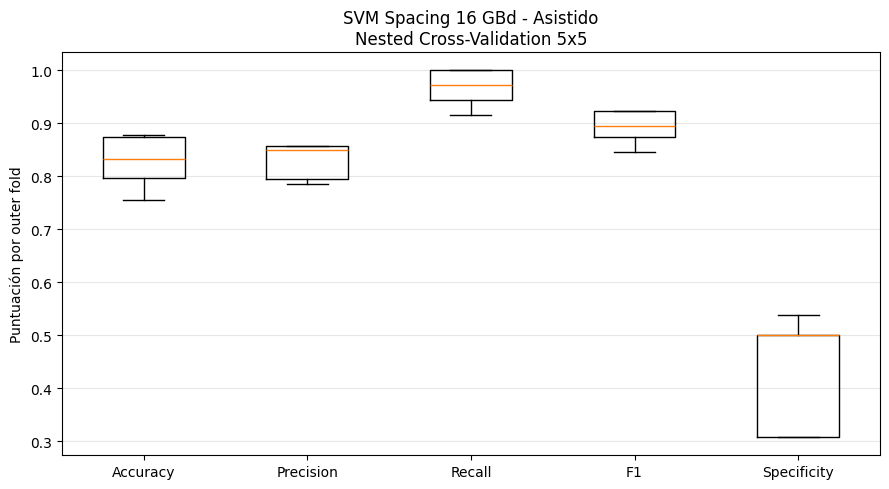


MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)
OOF Accuracy:    0.8272
OOF Precision:   0.8286
OOF Recall:      0.9667
OOF F1 ALARMA:   0.8923
OOF Specificity: 0.4286

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.82      0.43      0.56        63
      ALARMA       0.83      0.97      0.89       180

    accuracy                           0.83       243
   macro avg       0.82      0.70      0.73       243
weighted avg       0.83      0.83      0.81       243


Matriz de confusión OOF absoluta:
[[ 27  36]
 [  6 174]]


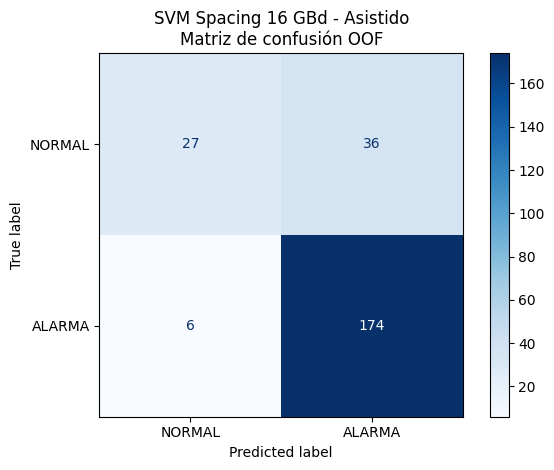


Matriz de confusión OOF normalizada:
[[0.42857143 0.57142857]
 [0.03333333 0.96666667]]


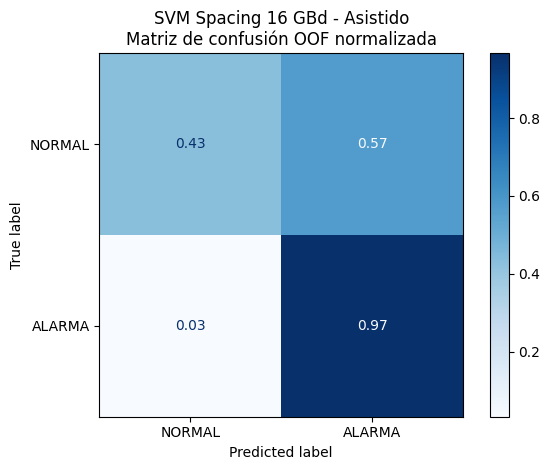


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  svm__C svm__kernel  inner_cv_best_f1  grid_time_s  svm__gamma
    1     1.0      linear          0.905494     0.105258         NaN
    2     1.0      linear          0.905027     0.127187         NaN
    3     0.1      linear          0.890328     0.115240         NaN
    4    10.0         rbf          0.896956     0.115060        0.01
    5     0.1      linear          0.867916     0.104389         NaN

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 10.132 µs/muestra
Inference Std:  1.527 µs/muestra
Mediciones totales: 500

Tiempo por muestra dentro de un batch.
Incluye StandardScaler y SVC.predict().
No incluye entrenamiento ni GridSearchCV.

ENTRENANDO MODELO FINAL SVM
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores parámetros finales:
{'svm__C': 1, 'svm__kernel': 'linear'}
F1 GridSearch final: 0.9067
Tiempo GridSearch final: 0.16 s

Tiempo entrenamiento SVM final: 0.011 s

CALCULANDO SHAP DE

  0%|          | 0/50 [00:00<?, ?it/s]


Tiempo SHAP: 1.93 s (0.03 min)

RANKING SHAP - 31 CARACTERÍSTICAS
     feature mean_abs_shap importance_percent
        OSNR      0.247321             34.34%
   Q_peak4_y      0.112679             15.65%
   I_peak4_y      0.060679              8.43%
I_broadening      0.048885              6.79%
 I_valley2_y      0.038198              5.30%
   Q_peak1_y      0.038007              5.28%
 I_valley1_y      0.034480              4.79%
Q_broadening      0.034087              4.73%
 Q_valley2_y      0.033249              4.62%
   I_peak2_y      0.026701              3.71%
   I_peak4_x      0.011237              1.56%
   I_peak1_y      0.007287              1.01%
   Q_peak2_x      0.005600              0.78%
 Q_valley1_y      0.005444              0.76%
   Q_peak3_y      0.005174              0.72%
   Q_peak1_x      0.003121              0.43%
   I_peak3_y      0.001901              0.26%
   I_peak3_x      0.001218              0.17%
 I_valley1_x      0.001175              0.16%
   I_peak1_x 

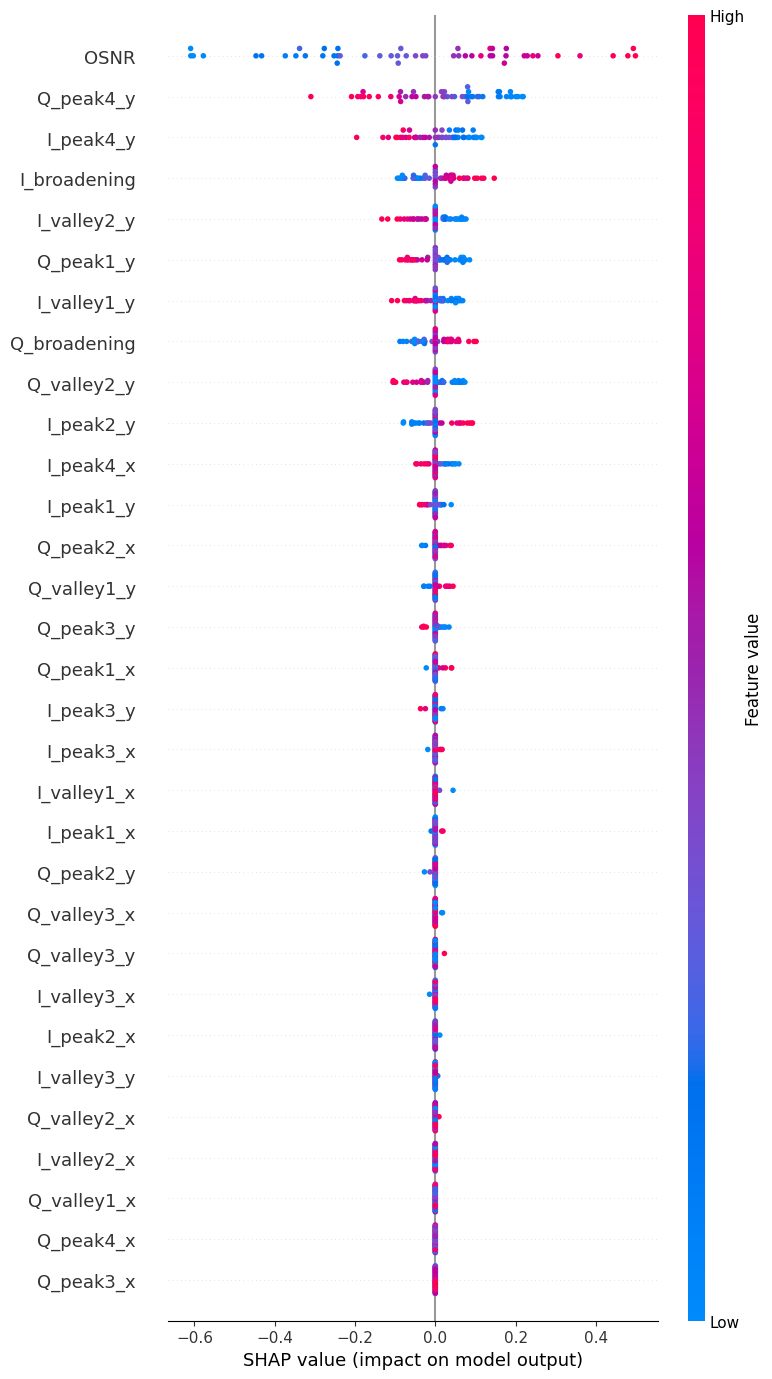

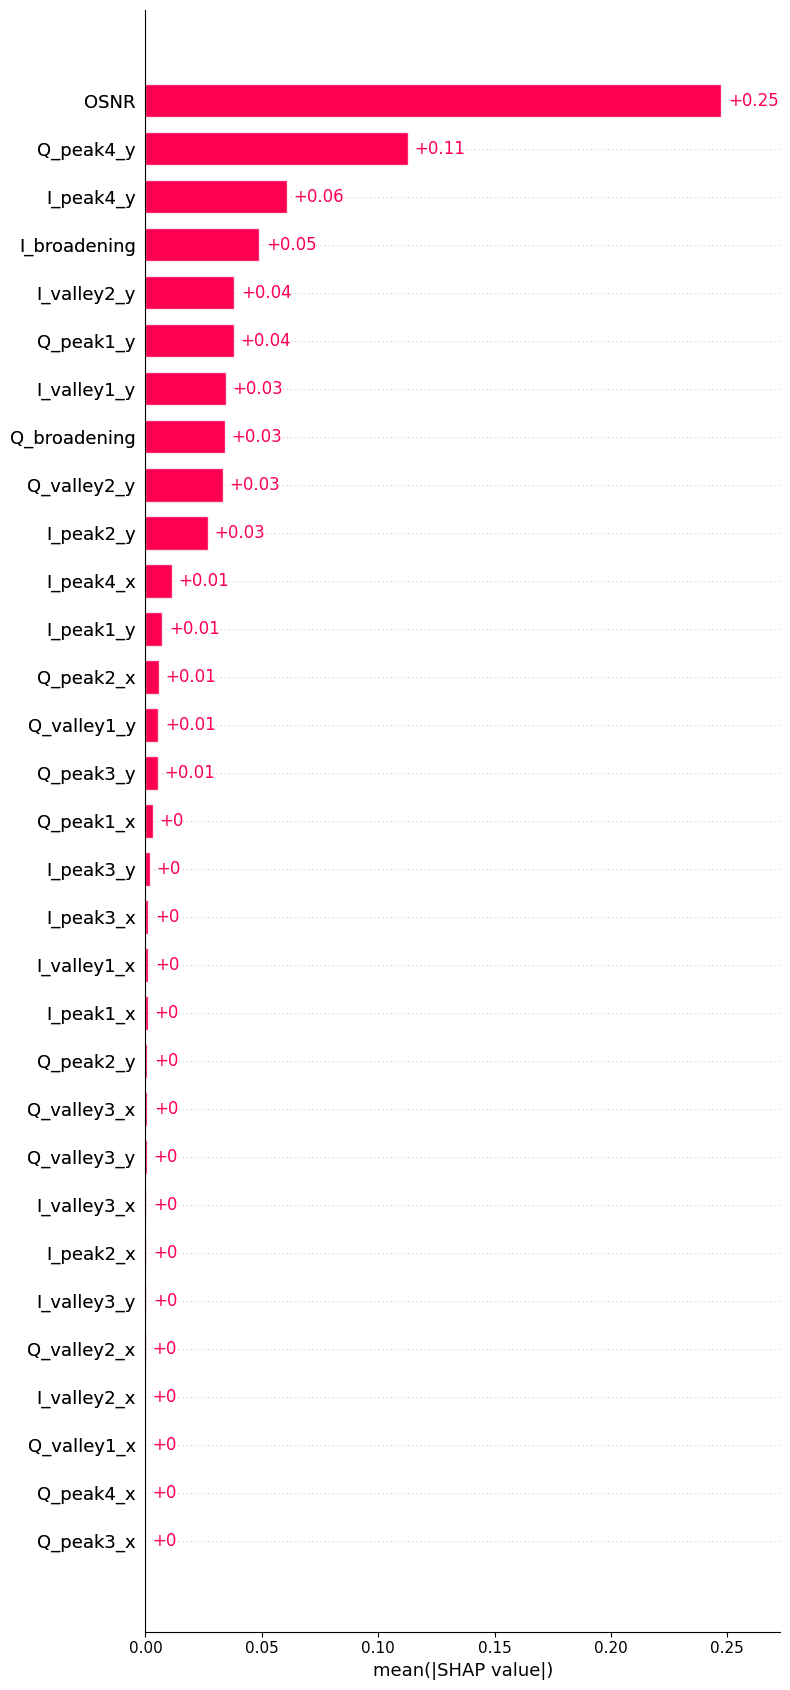

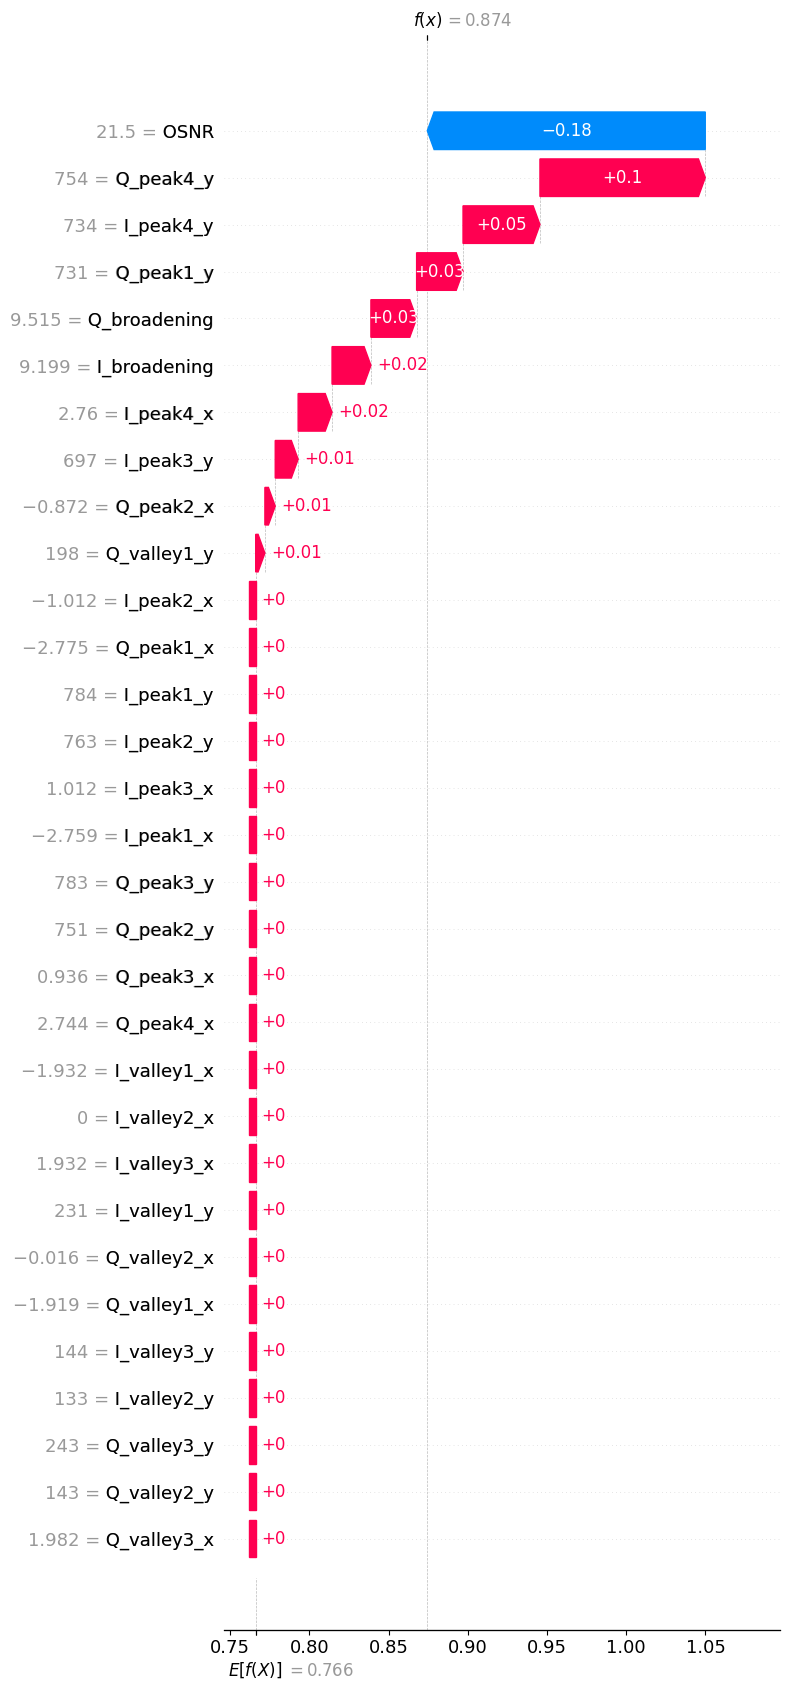


RESUMEN FINAL - SVM SPACING 16 GBd
MONITOREO ASISTIDO - NESTED CV 5x5

OUTER CV (MEDIA ± STD):
ACCURACY    : 0.8274 ± 0.0470
PRECISION   : 0.8291 ± 0.0317
RECALL      : 0.9667 ± 0.0324
F1          : 0.8924 ± 0.0294
SPECIFICITY : 0.4308 ± 0.1015

MÉTRICAS GLOBALES OOF:
Accuracy:    0.8272
Precision:   0.8286
Recall:      0.9667
F1 ALARMA:   0.8923
Specificity: 0.4286

TIEMPO DE INFERENCIA:
10.132 ± 1.527 µs/muestra

MODELO FINAL:
Kernel: linear
C: 1

SHAP:
Tiempo: 1.93 s
Top feature: OSNR
Importancia relativa: 34.34%

ARCHIVOS GENERADOS:
1. svm_spacing_16GBd_asistido_nested_outer_folds.csv
2. svm_spacing_16GBd_asistido_nested_oof_predictions.csv
3. svm_spacing_16GBd_asistido_nested_best_params.csv
4. svm_spacing_16GBd_asistido_nested_importancia_shap.csv

PROCESO COMPLETADO.


In [ ]:

"""
===============================================================
CLASIFICACIÓN DE SEPARACIÓN ESPECTRAL - 16 GBd
SVM - MONITOREO ASISTIDO
NESTED CV 5x5 + PREDICCIONES OUT-OF-FOLD (OOF)
===============================================================

CLASES:
    0 = NORMAL: channel_spacing > 17.6 GHz
    1 = ALARMA: channel_spacing <= 17.6 GHz

ENTRADAS:
    - 30 características de histogramas I/Q
    - OSNR
    Total: 31 características

VARIABLE OBJETIVO:
    channel_spacing (convertida a clase binaria)

METODOLOGÍA:
    - Outer CV: 5 folds estratificados
    - Inner CV: 5 folds estratificados
    - GridSearchCV optimizando F1 de ALARMA
    - Predicciones OOF para todas las muestras
    - Métricas por fold y globales OOF
    - Matrices de confusión
    - Tiempo de inferencia
    - Modelo final con probability=True
    - SHAP KernelExplainer

IMPORTANTE:
    SHAP explica el modelo final entrenado con todo X.
    No corresponde a una explicación OOF.
"""

# ============================================================
# 1. IMPORTAR LIBRERÍAS
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 2. CONFIGURACIÓN
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

# Para 16 GBd y roll-off = 0.1:
# BW = 16 * (1 + 0.1) = 17.6 GHz
THRESHOLD_GHZ = 17.6

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 500

OUTPUT_PREFIX = "svm_spacing_16GBd_asistido_nested"

# ============================================================
# 3. NOMBRES DE CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "OSNR"]
)

assert len(feature_names) == 31

# ============================================================
# 4. CARGAR Y VALIDAR DATOS
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Columnas 0-29: características I/Q
# Columna 30: channel_spacing
# Columna 31: OSNR

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas y "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ------------------------------------------------------------
# 4.1 VARIABLE OBJETIVO
# ------------------------------------------------------------

y_spacing = matriz.iloc[:, 30].to_numpy()

# ------------------------------------------------------------
# 4.2 ENTRADAS: MONITOREO ASISTIDO
# ------------------------------------------------------------

# Eliminar channel_spacing porque es el target.
# Mantener OSNR como característica de entrada.

X = matriz.drop(
    columns=matriz.columns[30]
).copy()

X.columns = feature_names

# ------------------------------------------------------------
# 4.3 CLASIFICACIÓN BINARIA
# ------------------------------------------------------------

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para realizar los folds externos."
    )

print("=" * 70)
print("DATASET - SVM SPACING 16 GBd")
print("MONITOREO ASISTIDO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma original: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print(
    "\nOSNR incluido como predictor."
)

print(
    "channel_spacing excluido de X."
)

# ============================================================
# 5. DEFINIR PIPELINE SVM
# ============================================================

def build_svm(probability=False, params=None):
    """
    Construye un pipeline nuevo:

        StandardScaler -> SVC

    El escalado se ajusta dentro de cada entrenamiento,
    evitando utilizar estadísticas del outer test.

    Durante GridSearchCV se usa probability=False
    para reducir el costo computacional.

    En el modelo final se usa probability=True
    para explicar P(ALARMA) mediante SHAP.
    """

    pipeline = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                probability=probability,
                random_state=SEED
            )
        )
    ])

    if params is not None:
        pipeline.set_params(**params)

    return pipeline

# ============================================================
# 6. GRID DE HIPERPARÁMETROS
# ============================================================

# Se conserva el grid del código original:
#
# LINEAR:
#     4 valores de C
#
# RBF:
#     4 valores de C x 4 valores de gamma
#
# TOTAL:
#     20 configuraciones

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [
            0.1,
            1,
            10,
            100
        ]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [
            0.1,
            1,
            10,
            100
        ],
        "svm__gamma": [
            "scale",
            0.01,
            0.1,
            1
        ]
    }
]

print("\nConfiguraciones del GridSearchCV: 20")

# ============================================================
# 7. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Predicciones OOF.
oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Decision function OOF.
# Esta es la salida del SVM sin calibrar probabilidades.
oof_decision = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Fold que predijo cada muestra.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 70)
print("INICIANDO NESTED CV 5x5")
print("=" * 70)

# ============================================================
# 8. BUCLE OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 8.1 DATOS DEL OUTER FOLD
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)}"
    )

    print(
        f"Outer Test:  {len(X_outer_test)}"
    )

    # --------------------------------------------------------
    # 8.2 INNER CV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    search = GridSearchCV(
        estimator=build_svm(probability=False),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    print("\nEjecutando GridSearchCV interno...")

    grid_start = time.perf_counter()

    # IMPORTANTE:
    # Solo se utilizan los datos del outer train.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    # GridSearchCV ya reentrenó el mejor pipeline
    # sobre todo el outer train.
    best_svm = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s"
    )

    # Guardar hiperparámetros.
    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 8.3 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # El modelo nunca vio estas muestras
    # durante entrenamiento ni selección.

    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    # Salida continua del SVM:
    # valores positivos favorecen ALARMA.
    y_outer_decision = best_svm.decision_function(
        X_outer_test
    )

    # Guardar cada predicción en la posición
    # original de su muestra.
    oof_predictions[test_idx] = y_outer_pred

    oof_decision[test_idx] = y_outer_decision

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 8.4 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 8.5 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Se mide el pipeline completo:
    # StandardScaler + SVC.predict().
    #
    # Se usa probability=False, como en la
    # selección interna.
    #
    # El tiempo es por muestra dentro de un batch,
    # no la latencia individual de una muestra.

    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 8.6 GUARDAR RESULTADOS
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:    {accuracy:.4f}")
    print(f"Precision:   {precision:.4f}")
    print(f"Recall:      {recall:.4f}")
    print(f"F1 ALARMA:   {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")

    print(
        f"Inference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 9. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_decision).all():
    raise RuntimeError(
        "Existen valores decision_function inválidos."
    )

print("\nPredicciones OOF completadas correctamente.")

# ============================================================
# 10. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 11. OUTER CV: PROMEDIO ± STD
# ============================================================

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 12. BOXPLOT DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "SVM Spacing 16 GBd - Asistido\n"
    "Nested Cross-Validation 5x5"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD (OOF)")
print("=" * 70)

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_oof.ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

print(
    f"OOF Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"OOF Precision:   {oof_precision:.4f}"
)

print(
    f"OOF Recall:      {oof_recall:.4f}"
)

print(
    f"OOF F1 ALARMA:   {oof_f1:.4f}"
)

print(
    f"OOF Specificity: {oof_specificity:.4f}"
)

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 14. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

print("\nMatriz de confusión OOF absoluta:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Spacing 16 GBd - Asistido\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

print("\nMatriz de confusión OOF normalizada:")
print(cm_oof_norm)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "SVM Spacing 16 GBd - Asistido\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 16. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": matriz.iloc[:, 31].to_numpy(),
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_function": oof_decision,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 17. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 70)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 70)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 18. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# 5 folds x 100 repeticiones = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean = (
    all_inference_times.mean()
)

inference_std = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean:.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{inference_std:.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "\nTiempo por muestra dentro de un batch."
)

print(
    "Incluye StandardScaler y SVC.predict()."
)

print(
    "No incluye entrenamiento ni GridSearchCV."
)

# ============================================================
# 19. ENTRENAR MODELO FINAL
# ============================================================

# Este modelo se entrena con TODO el dataset.
#
# Su objetivo es proporcionar un clasificador final
# y calcular SHAP.
#
# NO se utiliza para evaluar las métricas OOF.

print("\n" + "=" * 70)
print("ENTRENANDO MODELO FINAL SVM")
print("=" * 70)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_svm(probability=False),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

print("\nMejores parámetros finales:")
print(final_best_params)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

# ------------------------------------------------------------
# 19.1 REENTRENAR CON PROBABILITY=True
# ------------------------------------------------------------

# El modelo final conserva kernel, C y gamma
# seleccionados mediante GridSearchCV.
#
# probability=True permite utilizar predict_proba()
# para calcular SHAP en unidades de probabilidad.
#
# Este entrenamiento puede ser más costoso que
# el realizado con probability=False.

final_svm = build_svm(
    probability=True,
    params=final_best_params
)

final_train_start = time.perf_counter()

final_svm.fit(X, y)

final_train_time = (
    time.perf_counter() - final_train_start
)

print(
    f"\nTiempo entrenamiento SVM final: "
    f"{final_train_time:.3f} s"
)

# ============================================================
# 20. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica:
#
#     P(ALARMA) = predict_proba[:, 1]
#
# SHAP positivo:
#     aumenta P(ALARMA).
#
# SHAP negativo:
#     disminuye P(ALARMA).
#
# Se utiliza el modelo final entrenado
# con todo el dataset.
#
# IMPORTANTE:
# Estos SHAP NO son OOF.

print("\n" + "=" * 70)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

print(
    f"SHAP nsamples: {SHAP_NSAMPLES}"
)

# ------------------------------------------------------------
# 20.1 FUNCIÓN PARA SHAP
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe una matriz de 31 características y
    devuelve la probabilidad de ALARMA.

    Se reconstruye el DataFrame para preservar
    los nombres y el orden de las columnas.
    """

    frame = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.predict_proba(
        frame
    )[:, 1]

# ------------------------------------------------------------
# 20.2 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = (
    time.perf_counter() - shap_start
)

print(
    f"\nTiempo SHAP: "
    f"{shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 21. VERIFICAR DIMENSIONES SHAP
# ============================================================

shap_values = np.asarray(raw)

# Para una función de salida escalar se espera:
# (n_muestras, 31 características)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

base_alarm = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

# ============================================================
# 22. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 31 CARACTERÍSTICAS")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print(
    f"\nSuma de porcentajes: "
    f"{imp_df['importance_percent'].sum():.2f}%"
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 23. CREAR SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 24. GRÁFICAS SHAP
# ============================================================

# Beeswarm
shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Bar
shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# Waterfall
shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 25. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - SVM SPACING 16 GBd")
print("MONITOREO ASISTIDO - NESTED CV 5x5")
print("=" * 70)

print("\nOUTER CV (MEDIA ± STD):")

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric.upper():12s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\nMÉTRICAS GLOBALES OOF:")

print(
    f"Accuracy:    {oof_accuracy:.4f}"
)

print(
    f"Precision:   {oof_precision:.4f}"
)

print(
    f"Recall:      {oof_recall:.4f}"
)

print(
    f"F1 ALARMA:   {oof_f1:.4f}"
)

print(
    f"Specificity: {oof_specificity:.4f}"
)

print("\nTIEMPO DE INFERENCIA:")

print(
    f"{inference_mean:.3f} ± "
    f"{inference_std:.3f} µs/muestra"
)

print("\nMODELO FINAL:")

print(
    f"Kernel: "
    f"{final_best_params['svm__kernel']}"
)

print(
    f"C: "
    f"{final_best_params['svm__C']}"
)

if final_best_params["svm__kernel"] == "rbf":

    print(
        f"Gamma: "
        f"{final_best_params['svm__gamma']}"
    )

print("\nSHAP:")

print(
    f"Tiempo: {shap_time:.2f} s"
)

print(
    f"Top feature: "
    f"{imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia relativa: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\nARCHIVOS GENERADOS:")

print(
    f"1. {OUTPUT_PREFIX}_outer_folds.csv"
)

print(
    f"2. {OUTPUT_PREFIX}_oof_predictions.csv"
)

print(
    f"3. {OUTPUT_PREFIX}_best_params.csv"
)

print(
    f"4. {OUTPUT_PREFIX}_importancia_shap.csv"
)

print("\nPROCESO COMPLETADO.")


## KNN 16GBd para clasificar SEPARACIÓN ESPECTRAL CON OSNR

KNN - SPACING 16 GBd - MONITOREO ASISTIDO
Dataset: matriz16GBd_clas.csv
Forma original: (243, 32)
Forma X: (243, 31)
Total muestras: 243
NORMAL (> 17.6 GHz): 63
ALARMA (<= 17.6 GHz): 180
OSNR incluida como predictor.
channel_spacing excluido de X.

Criterio de optimización: F1-MACRO
Combinaciones del grid: 84

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: 194 muestras
Outer Test:  49 muestras

Ejecutando GridSearchCV interno...

Mejores hiperparámetros:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'uniform'}
Mejor F1-Macro Inner CV: 0.6385
Tiempo GridSearchCV: 0.20 s

MÉTRICAS OUTER FOLD:
Accuracy:          0.7959
Balanced Accuracy: 0.6400
F1 Macro:          0.6597

CLASE ALARMA:
Precision:         0.7955
Recall:            0.9722
F1:                0.8750

CLASE NORMAL:
Precision:         0.8000
Recall:            0.3077
F1:                0.4444

Inference: 21.773 ± 0.516 µs/muestra

OUTER FOLD 2/5
Outer Train: 194 muestras
Out

/tmp/ipykernel_4165/766343682.py:588: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


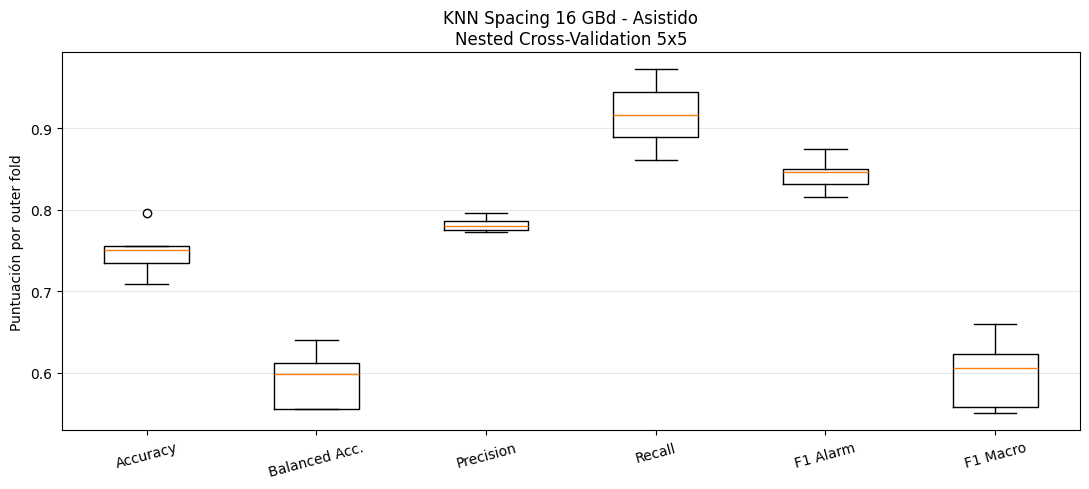


MÉTRICAS GLOBALES OOF
accuracy            : 0.7490
balanced_accuracy   : 0.5933
precision_alarm     : 0.7820
recall_alarm        : 0.9167
f1_alarm            : 0.8440
precision_normal    : 0.5312
recall_normal       : 0.2698
f1_normal           : 0.3579
f1_macro            : 0.6009
specificity         : 0.2698

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.53      0.27      0.36        63
      ALARMA       0.78      0.92      0.84       180

    accuracy                           0.75       243
   macro avg       0.66      0.59      0.60       243
weighted avg       0.72      0.75      0.72       243


Matriz de confusión OOF:
[[ 17  46]
 [ 15 165]]


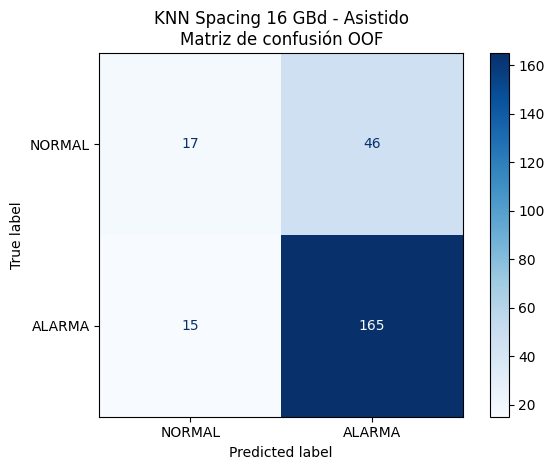

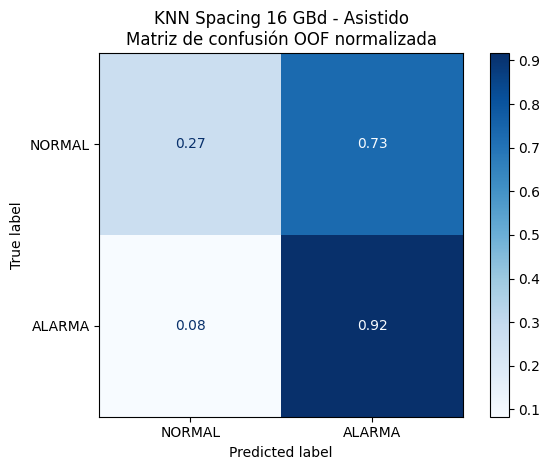


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold knn__metric  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1_macro  grid_time_s
    1   euclidean                 5       1      uniform                0.638461     0.203506
    2   manhattan                 5       1      uniform                0.624293     0.146373
    3   manhattan                 5       1      uniform                0.655234     0.142508
    4   euclidean                 3       1      uniform                0.680687     0.132711
    5   euclidean                 3       1      uniform                0.659013     0.130431

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 20.869 µs/muestra
Inference Std:  1.992 µs/muestra
Mediciones totales: 500

Tiempo promedio por muestra dentro de un batch.
Incluye StandardScaler y KNN.predict().
No incluye entrenamiento ni GridSearchCV.

ENTRENANDO MODELO FINAL KNN

Mejores parámetros finales:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__p': 

  0%|          | 0/50 [00:00<?, ?it/s]


Tiempo SHAP: 0.80 s (0.01 min)

RANKING SHAP - 31 CARACTERÍSTICAS
     feature mean_abs_shap importance_percent
        OSNR      0.034971             11.24%
 I_valley2_x      0.021396              6.88%
 Q_valley2_x      0.018988              6.10%
   I_peak3_x      0.016172              5.20%
 I_valley3_x      0.014599              4.69%
   Q_peak4_x      0.014577              4.69%
   I_peak1_x      0.011693              3.76%
   Q_peak2_x      0.011653              3.75%
   I_peak4_x      0.011406              3.67%
   I_peak4_y      0.011241              3.61%
 Q_valley1_x      0.010840              3.48%
   Q_peak3_y      0.010267              3.30%
   Q_peak3_x      0.010128              3.26%
   Q_peak4_y      0.009736              3.13%
   Q_peak1_x      0.009143              2.94%
 I_valley2_y      0.008255              2.65%
   Q_peak1_y      0.008204              2.64%
   I_peak2_x      0.008064              2.59%
 Q_valley3_x      0.007031              2.26%
   I_peak1_y 

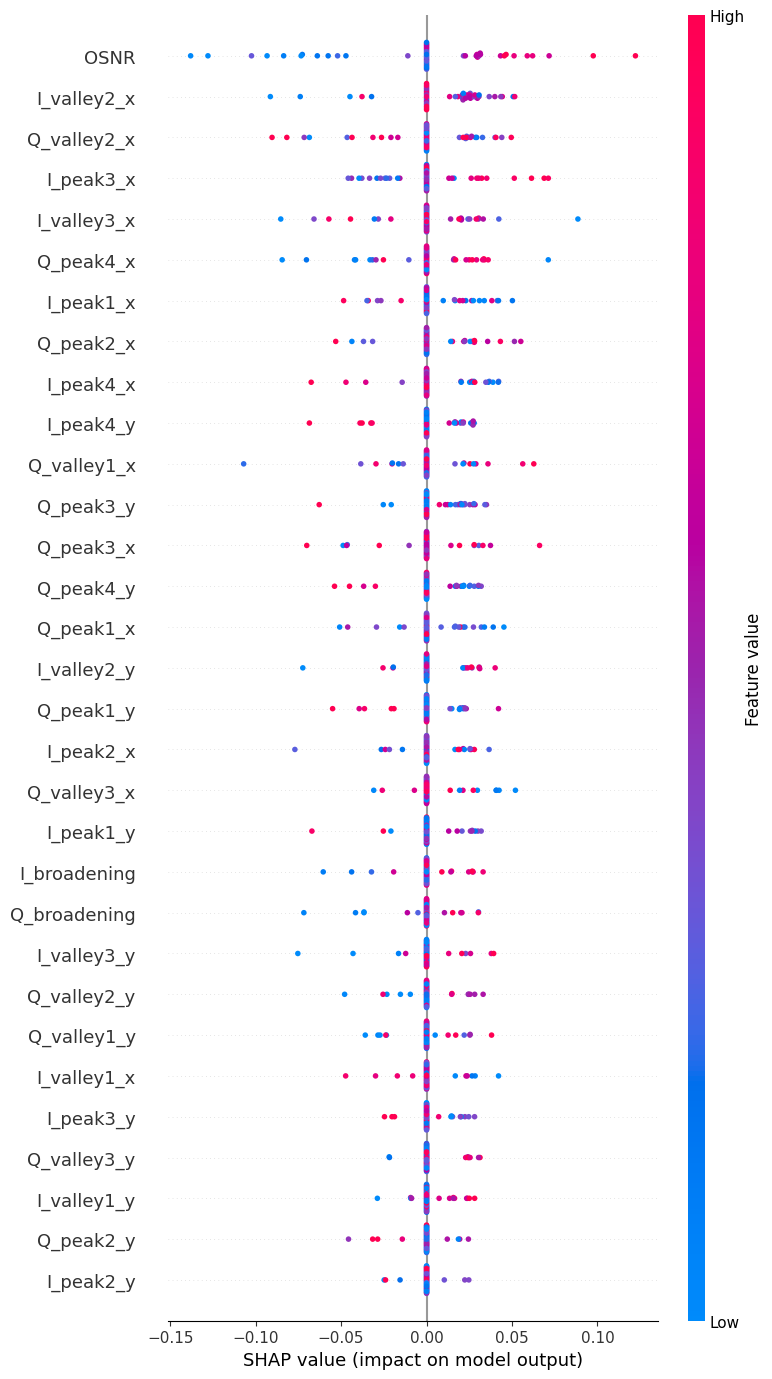

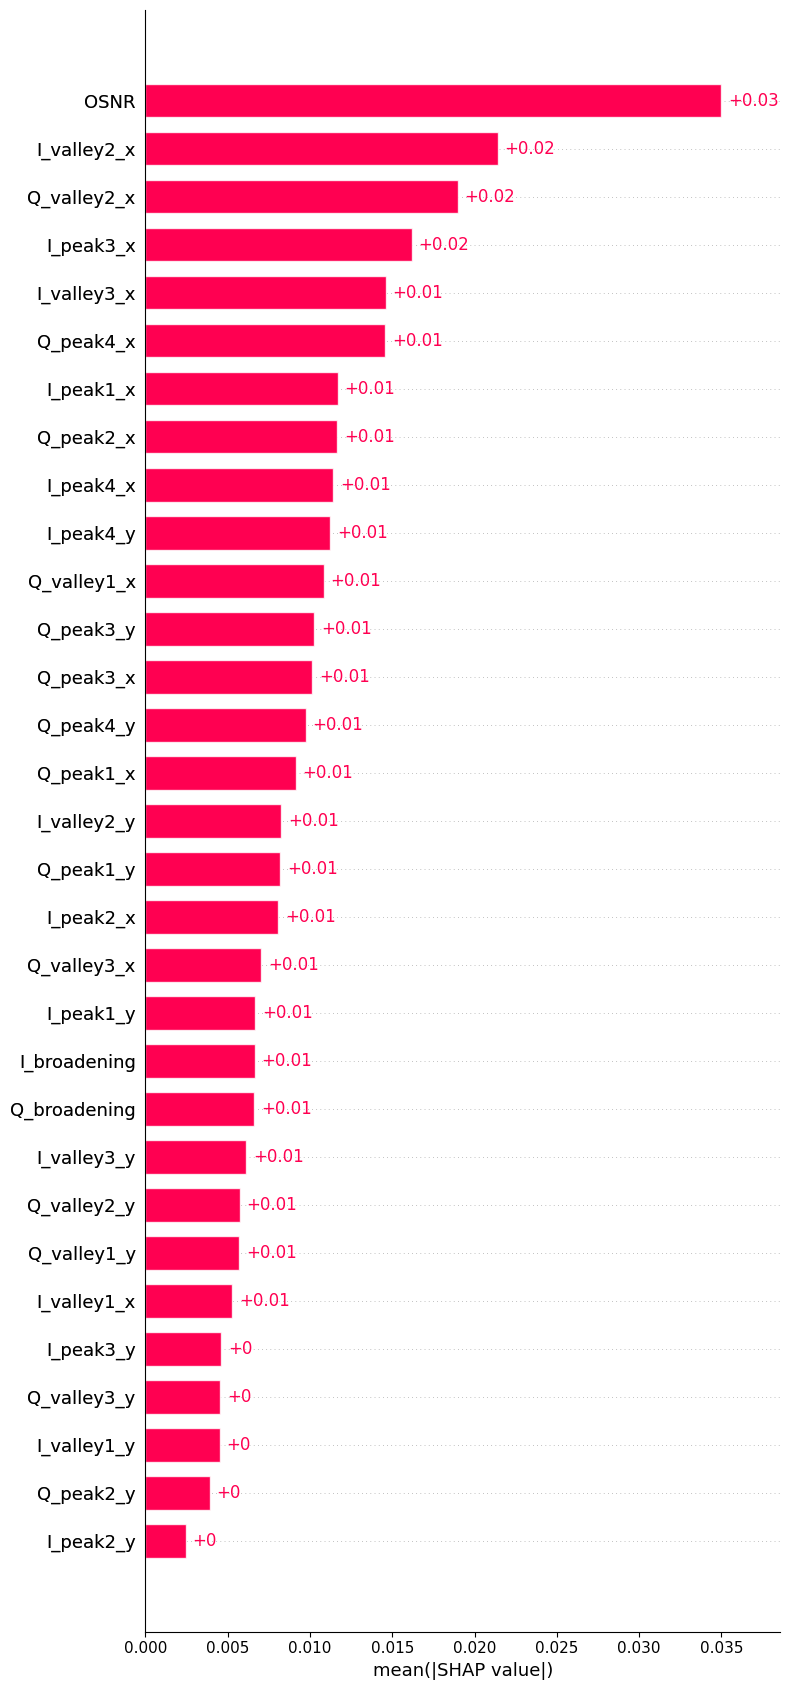

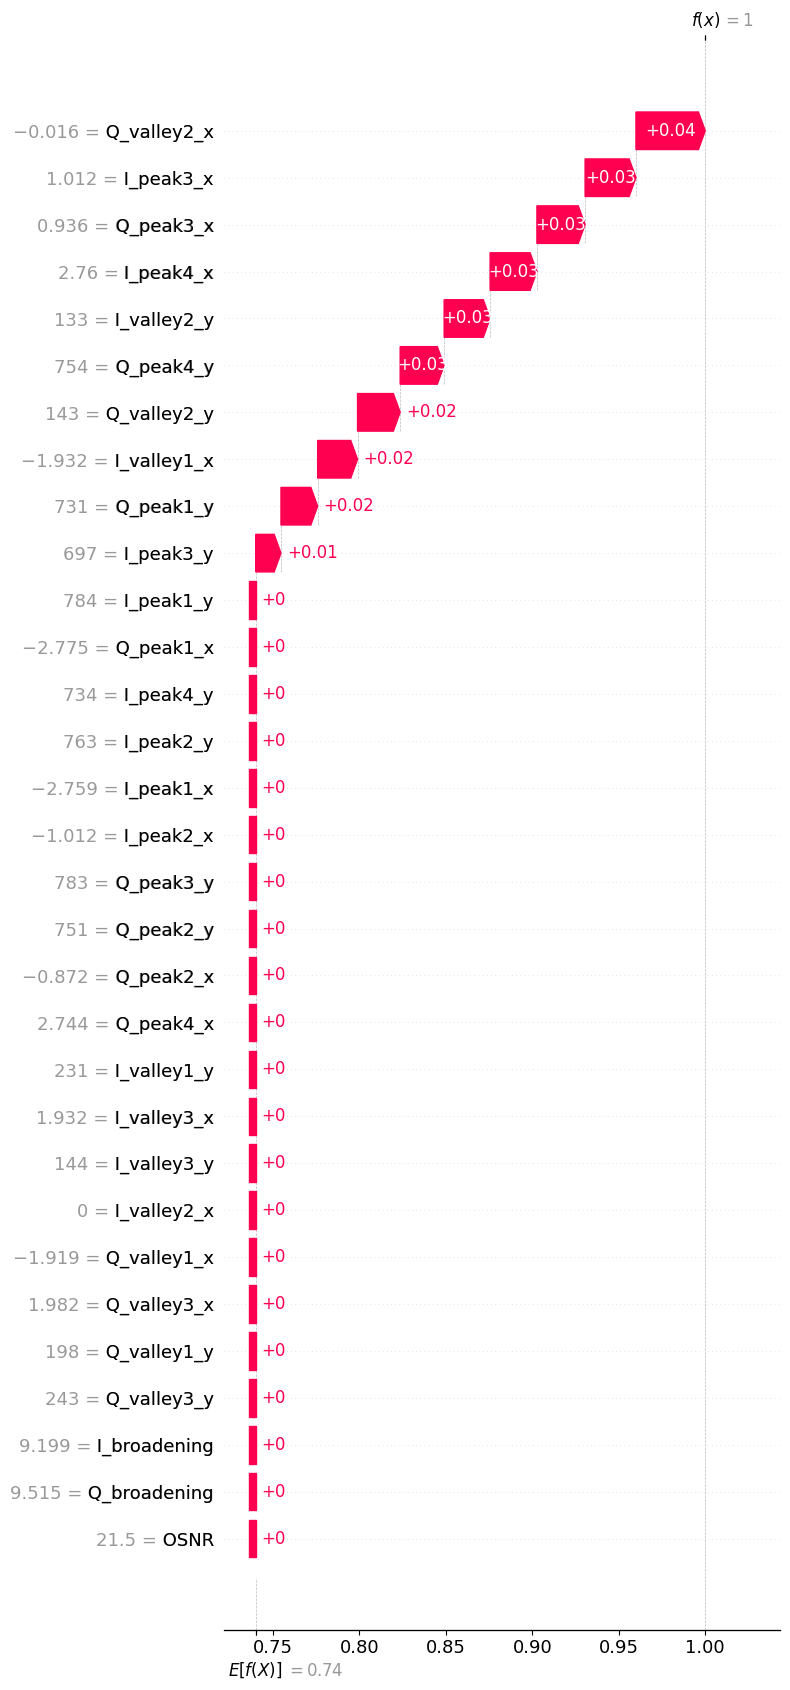


RESUMEN FINAL - KNN SPACING 16 GBd
MONITOREO ASISTIDO - NESTED CV 5x5

--- OUTER CV: PROMEDIO ± STD ---
accuracy            : 0.7488 ± 0.0286
balanced_accuracy   : 0.5923 ± 0.0329
precision_alarm     : 0.7819 ± 0.0081
recall_alarm        : 0.9167 ± 0.0393
f1_alarm            : 0.8436 ± 0.0198
precision_normal    : 0.5493 ± 0.1404
recall_normal       : 0.2679 ± 0.0554
f1_normal           : 0.3551 ± 0.0704
f1_macro            : 0.5994 ± 0.0410
specificity         : 0.2679 ± 0.0554

--- MÉTRICAS GLOBALES OOF ---
accuracy            : 0.7490
balanced_accuracy   : 0.5933
precision_alarm     : 0.7820
recall_alarm        : 0.9167
f1_alarm            : 0.8440
precision_normal    : 0.5312
recall_normal       : 0.2698
f1_normal           : 0.3579
f1_macro            : 0.6009
specificity         : 0.2698

--- TIEMPO DE INFERENCIA ---
Inference: 20.869 ± 1.992 µs/muestra

--- MODELO FINAL ---
Mejores parámetros:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uni

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

# Para 16 GBd y roll-off = 0.1:
# BW = 16 * (1 + 0.1) = 17.6 GHz
THRESHOLD_GHZ = 17.6

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 500

OUTPUT_PREFIX = "knn_spacing_16GBd_asistido_nested"

# ============================================================
# 2. NOMBRES DE LAS CARACTERÍSTICAS
# ============================================================

# 30 características extraídas de histogramas I/Q
# + OSNR conocida = 31 características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "OSNR"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR EL DATASET
# ============================================================

matriz = pd.read_csv(CSV_PATH, header=None)

# Estructura esperada:
# Columnas 0-29: características I/Q
# Columna 30: channel_spacing
# Columna 31: OSNR

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas y "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(pd.to_numeric, errors="raise")

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError("El CSV contiene NaN o infinitos.")

# ============================================================
# 4. DEFINIR ENTRADAS Y VARIABLE OBJETIVO
# ============================================================

# Separación espectral real.
y_spacing = matriz.iloc[:, 30].to_numpy()

# Monitoreo asistido:
# 30 características I/Q + OSNR.
#
# Excluimos channel_spacing porque es la variable
# que queremos clasificar.

X = matriz.drop(columns=matriz.columns[30]).copy()
X.columns = feature_names

# Clasificación binaria:
# 0 = NORMAL: spacing > 17.6 GHz
# 1 = ALARMA: spacing <= 17.6 GHz

y = (y_spacing <= THRESHOLD_GHZ).astype(int)

n_samples = len(y)
class_counts = np.bincount(y, minlength=2)

# Verificar suficientes muestras para ambos niveles CV.
if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds externos."
    )

# En cada outer train debe haber suficientes muestras
# de ambas clases para los cinco folds internos.
min_outer_train_class = min(
    count - int(np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para los folds internos."
    )

print("=" * 70)
print("KNN - SPACING 16 GBd - MONITOREO ASISTIDO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma original: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print("OSNR incluida como predictor.")
print("channel_spacing excluido de X.")

# ============================================================
# 5. DEFINIR PIPELINE KNN
# ============================================================

def build_knn():
    """
    Construye un pipeline nuevo:

        StandardScaler -> KNeighborsClassifier

    El escalado se ajusta exclusivamente con los datos
    de entrenamiento de cada fold.

    Esto evita utilizar estadísticas del outer test
    durante el entrenamiento.
    """

    return Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

# ============================================================
# 6. GRID DE HIPERPARÁMETROS
# ============================================================

# Conservamos el grid del código original.
#
# Nota:
# Para metric="euclidean" o "manhattan", el parámetro p
# no cambia la distancia. Por ello algunas combinaciones
# son equivalentes.
#
# Se mantiene el grid original para preservar la lógica
# de búsqueda del experimento.

param_grid = {
    "knn__n_neighbors": [
        3, 5, 7, 9, 11, 15, 21
    ],
    "knn__weights": [
        "uniform", "distance"
    ],
    "knn__metric": [
        "euclidean", "manhattan", "minkowski"
    ],
    "knn__p": [1, 2]
}

print("\nCriterio de optimización: F1-MACRO")
print("Combinaciones del grid: 84")

# ============================================================
# 7. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra tendrá una única predicción OOF.
oof_predictions = np.full(
    n_samples, -1, dtype=int
)

# Probabilidad OOF de la clase ALARMA.
oof_prob_alarm = np.full(
    n_samples, np.nan, dtype=float
)

# Identificar el fold que evaluó cada muestra.
oof_fold = np.full(
    n_samples, -1, dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 8. BUCLE PRINCIPAL: OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 8.1 DIVIDIR OUTER TRAIN Y OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {len(train_idx)} muestras")
    print(f"Outer Test:  {len(test_idx)} muestras")

    # --------------------------------------------------------
    # 8.2 CONFIGURAR INNER CV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 8.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    search = GridSearchCV(
        estimator=build_knn(),
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=0
    )

    print("\nEjecutando GridSearchCV interno...")

    grid_start = time.perf_counter()

    # IMPORTANTE:
    # Solo se utiliza el outer train.
    # El outer test NO participa en la búsqueda.
    search.fit(X_outer_train, y_outer_train)

    grid_time = time.perf_counter() - grid_start

    # GridSearchCV reentrena automáticamente el mejor
    # pipeline utilizando todo el outer train.
    best_knn = search.best_estimator_

    print("\nMejores hiperparámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1-Macro Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1_macro": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 8.4 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Estas muestras no fueron utilizadas para
    # entrenar ni seleccionar hiperparámetros.
    y_outer_pred = best_knn.predict(X_outer_test)

    # Probabilidad de ALARMA.
    y_outer_prob = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar predicciones en sus posiciones originales.
    oof_predictions[test_idx] = y_outer_pred
    oof_prob_alarm[test_idx] = y_outer_prob
    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 8.5 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(
        y_outer_test, y_outer_pred
    )

    balanced_acc = balanced_accuracy_score(
        y_outer_test, y_outer_pred
    )

    precision_alarm = precision_score(
        y_outer_test,
        y_outer_pred,
        pos_label=1,
        zero_division=0
    )

    recall_alarm = recall_score(
        y_outer_test,
        y_outer_pred,
        pos_label=1,
        zero_division=0
    )

    f1_alarm = f1_score(
        y_outer_test,
        y_outer_pred,
        pos_label=1,
        zero_division=0
    )

    precision_normal = precision_score(
        y_outer_test,
        y_outer_pred,
        pos_label=0,
        zero_division=0
    )

    recall_normal = recall_score(
        y_outer_test,
        y_outer_pred,
        pos_label=0,
        zero_division=0
    )

    f1_normal = f1_score(
        y_outer_test,
        y_outer_pred,
        pos_label=0,
        zero_division=0
    )

    f1_macro = f1_score(
        y_outer_test,
        y_outer_pred,
        average="macro",
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    # --------------------------------------------------------
    # 8.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up para reducir el efecto de inicialización.
    _ = best_knn.predict(
        X_outer_test.iloc[:min(10, len(X_outer_test))]
    )

    inference_times = np.empty(N_REPETITIONS)

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(X_outer_test)

        elapsed = time.perf_counter() - start

        # Tiempo promedio por muestra en el batch.
        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 8.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "balanced_accuracy": balanced_acc,
        "precision_alarm": precision_alarm,
        "recall_alarm": recall_alarm,
        "f1_alarm": f1_alarm,
        "precision_normal": precision_normal,
        "recall_normal": recall_normal,
        "f1_normal": f1_normal,
        "f1_macro": f1_macro,
        "specificity": specificity,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Balanced Accuracy: {balanced_acc:.4f}")
    print(f"F1 Macro:          {f1_macro:.4f}")

    print("\nCLASE ALARMA:")
    print(f"Precision:         {precision_alarm:.4f}")
    print(f"Recall:            {recall_alarm:.4f}")
    print(f"F1:                {f1_alarm:.4f}")

    print("\nCLASE NORMAL:")
    print(f"Precision:         {precision_normal:.4f}")
    print(f"Recall:            {recall_normal:.4f}")
    print(f"F1:                {f1_normal:.4f}")

    print(
        f"\nInference: {inference_mean_us:.3f} "
        f"± {inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 9. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_prob_alarm).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nPredicciones OOF completadas correctamente.")

# ============================================================
# 10. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(outer_results)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(results_df.to_string(index=False))

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 11. OUTER CV: PROMEDIO Y DESVIACIÓN ESTÁNDAR
# ============================================================

metrics = [
    "accuracy",
    "balanced_accuracy",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "precision_normal",
    "recall_normal",
    "f1_normal",
    "f1_macro",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metrics:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:20s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 12. BOXPLOT DE MÉTRICAS OUTER CV
# ============================================================

plot_metrics = [
    "accuracy",
    "balanced_accuracy",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "f1_macro"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [results_df[m].values for m in plot_metrics],
    labels=[
        "Accuracy",
        "Balanced Acc.",
        "Precision",
        "Recall",
        "F1 Alarm",
        "F1 Macro"
    ]
)

plt.ylabel("Puntuación por outer fold")

plt.title(
    "KNN Spacing 16 GBd - Asistido\n"
    "Nested Cross-Validation 5x5"
)

plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. MÉTRICAS GLOBALES OUT-OF-FOLD
# ============================================================

cm_oof = confusion_matrix(
    y, oof_predictions, labels=[0, 1]
)

tn, fp, fn, tp = cm_oof.ravel()

oof_metrics = {
    "accuracy": accuracy_score(y, oof_predictions),

    "balanced_accuracy": balanced_accuracy_score(
        y, oof_predictions
    ),

    "precision_alarm": precision_score(
        y, oof_predictions,
        pos_label=1, zero_division=0
    ),

    "recall_alarm": recall_score(
        y, oof_predictions,
        pos_label=1, zero_division=0
    ),

    "f1_alarm": f1_score(
        y, oof_predictions,
        pos_label=1, zero_division=0
    ),

    "precision_normal": precision_score(
        y, oof_predictions,
        pos_label=0, zero_division=0
    ),

    "recall_normal": recall_score(
        y, oof_predictions,
        pos_label=0, zero_division=0
    ),

    "f1_normal": f1_score(
        y, oof_predictions,
        pos_label=0, zero_division=0
    ),

    "f1_macro": f1_score(
        y, oof_predictions,
        average="macro", zero_division=0
    ),

    "specificity": (
        tn / (tn + fp) if (tn + fp) > 0 else np.nan
    )
}

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OOF")
print("=" * 70)

for metric, value in oof_metrics.items():
    print(f"{metric:20s}: {value:.4f}")

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 14. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Spacing 16 GBd - Asistido\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "KNN Spacing 16 GBd - Asistido\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 16. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": matriz.iloc[:, 31].to_numpy(),
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_prob_alarm,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 17. GUARDAR HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(outer_best_params)

print("\n" + "=" * 70)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 70)

print(params_df.to_string(index=False))

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 18. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# Cinco folds x 100 repeticiones = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean = all_inference_times.mean()
inference_std = all_inference_times.std()

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean:.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{inference_std:.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "\nTiempo promedio por muestra dentro de un batch."
)

print(
    "Incluye StandardScaler y KNN.predict()."
)

print(
    "No incluye entrenamiento ni GridSearchCV."
)

# ============================================================
# 19. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# Este modelo final se utiliza para SHAP.
#
# NO se utiliza para calcular las métricas OOF.
#
# Se vuelve a ejecutar GridSearchCV utilizando
# todo el dataset.

print("\n" + "=" * 70)
print("ENTRENANDO MODELO FINAL KNN")
print("=" * 70)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_knn(),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=0
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_knn = final_search.best_estimator_

print("\nMejores parámetros finales:")
print(final_search.best_params_)

print(
    f"F1-Macro GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

# ============================================================
# 20. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explicará:
#
#     P(ALARMA) = predict_proba[:, 1]
#
# SHAP positivo:
#     Aumenta la probabilidad estimada de ALARMA.
#
# SHAP negativo:
#     Disminuye la probabilidad estimada de ALARMA.
#
# IMPORTANTE:
# Estas explicaciones corresponden al modelo final
# entrenado con todos los datos.
# NO son explicaciones OOF.

print("\n" + "=" * 70)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(f"Background: {len(background)} muestras")
print(f"Muestras explicadas: {len(explained)}")
print(f"SHAP nsamples: {SHAP_NSAMPLES}")

# ------------------------------------------------------------
# 20.1 FUNCIÓN DE PREDICCIÓN PARA SHAP
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe las 31 características y devuelve
    la probabilidad estimada de ALARMA.
    """

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(data)[:, 1]

# ------------------------------------------------------------
# 20.2 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw_shap = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = time.perf_counter() - shap_start

shap_values = np.asarray(raw_shap)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: {shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

base_alarm = float(
    np.asarray(explainer.expected_value).item()
)

print(
    f"\nTiempo SHAP: "
    f"{shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 21. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:
    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )
else:
    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 31 CARACTERÍSTICAS")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 SHAP:")
print(imp_df.head(5).to_string(index=False))

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 22. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 23. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 24. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 25. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 26. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - KNN SPACING 16 GBd")
print("MONITOREO ASISTIDO - NESTED CV 5x5")
print("=" * 70)

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metrics:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:20s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():
    print(f"{metric:20s}: {value:.4f}")

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean:.3f} "
    f"± {inference_std:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print("Mejores parámetros:")
print(final_search.best_params_)

print(
    f"F1-Macro GridSearch: "
    f"{final_search.best_score_:.4f}"
)

print("\n--- SHAP ---")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## RDF 32GBd para clasificar SEPARACIÓN ESPECTRAL CON OSNR


DATASET - RANDOM FOREST SPACING 32 GBd
MONITOREO ASISTIDO
Dataset: matriz32GBd_clasifi_correct.csv
Forma original: (9330, 32)
Forma X: (9330, 31)
Muestras: 9330
NORMAL (> 35.2 GHz): 2951
ALARMA (<= 35.2 GHz): 6379

OSNR incluida como predictor.
channel_spacing excluido de X.

GRID SEARCH - RANDOM FOREST
Combinaciones: 162
Criterio de optimización: F1 ALARMA
Outer folds: 5
Inner folds: 5

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: 7464 muestras
Outer Test:  1866 muestras

Ejecutando GridSearchCV interno...

Mejores parámetros:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 400}
Mejor F1 Inner CV: 0.8655
Tiempo GridSearchCV: 77.62 s

MÉTRICAS OUTER FOLD:
Accuracy:          0.8114
Precision ALARMA:  0.8338
Recall ALARMA:     0.9044
F1 ALARMA:         0.8677
Specificity:       0.6102
Balanced Accuracy: 0.7573
F1 Macro:          0.7697

Inference Mean: 30.953 µs/muestra
Inference Std:  0.404 µs/muestra

OUTE

/tmp/ipykernel_4165/3283431017.py:674: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


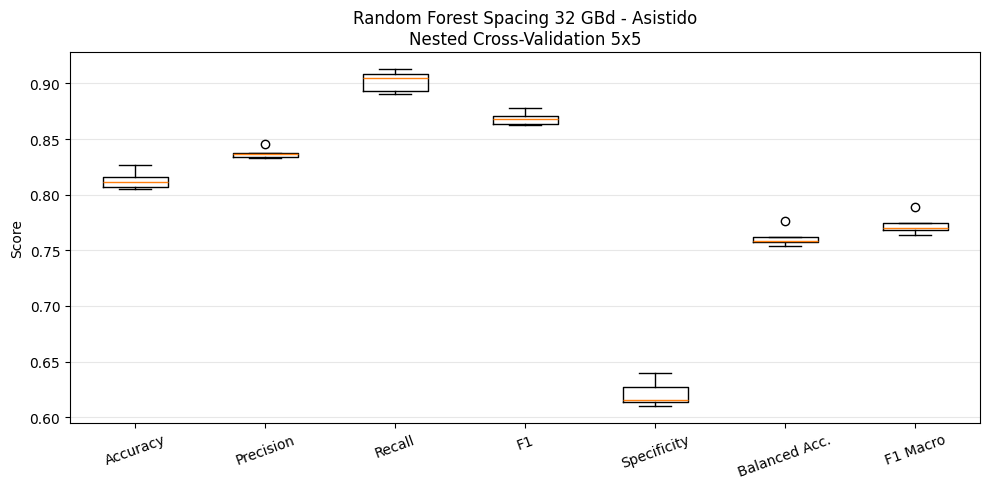


MÉTRICAS GLOBALES OUT-OF-FOLD
Accuracy:          0.8131
Precision ALARMA:  0.8373
Recall ALARMA:     0.9019
F1 ALARMA:         0.8684
Specificity:       0.6211
Balanced Accuracy: 0.7615
F1 Macro:          0.7730

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.75      0.62      0.68      2951
      ALARMA       0.84      0.90      0.87      6379

    accuracy                           0.81      9330
   macro avg       0.79      0.76      0.77      9330
weighted avg       0.81      0.81      0.81      9330


Matriz de confusión OOF:
[[1833 1118]
 [ 626 5753]]


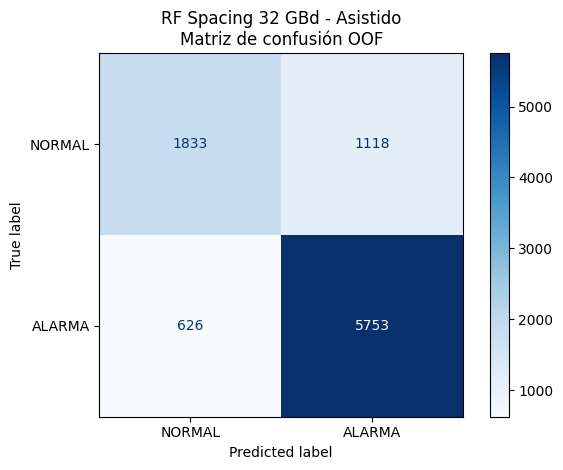


Matriz de confusión OOF normalizada:
[[0.62114537 0.37885463]
 [0.0981345  0.9018655 ]]


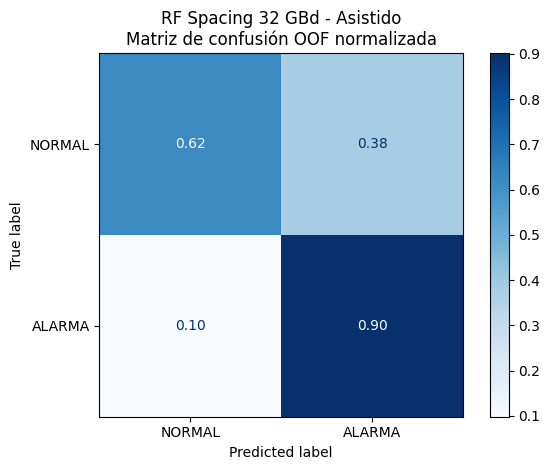


Predicciones OOF guardadas.

HIPERPARÁMETROS POR OUTER FOLD
 fold  max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1  grid_time_s
    1       20.0         sqrt                 1                 10           400          0.865549    77.619944
    2       20.0         sqrt                 1                  5           200          0.866541    72.577749
    3       20.0         sqrt                 1                  5           400          0.866808    77.003804
    4       20.0         sqrt                 2                  2           400          0.865339    76.714530
    5        NaN         sqrt                 1                  5           400          0.862465    77.474275

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 28.559 µs/muestra
Inference Std:  6.778 µs/muestra
Mediciones totales: 500

Tiempo promedio por muestra dentro de un batch.
No incluye entrenamiento ni GridSearchCV.

ENTRENANDO MODELO FINAL RANDOM FOREST

Mejores pará

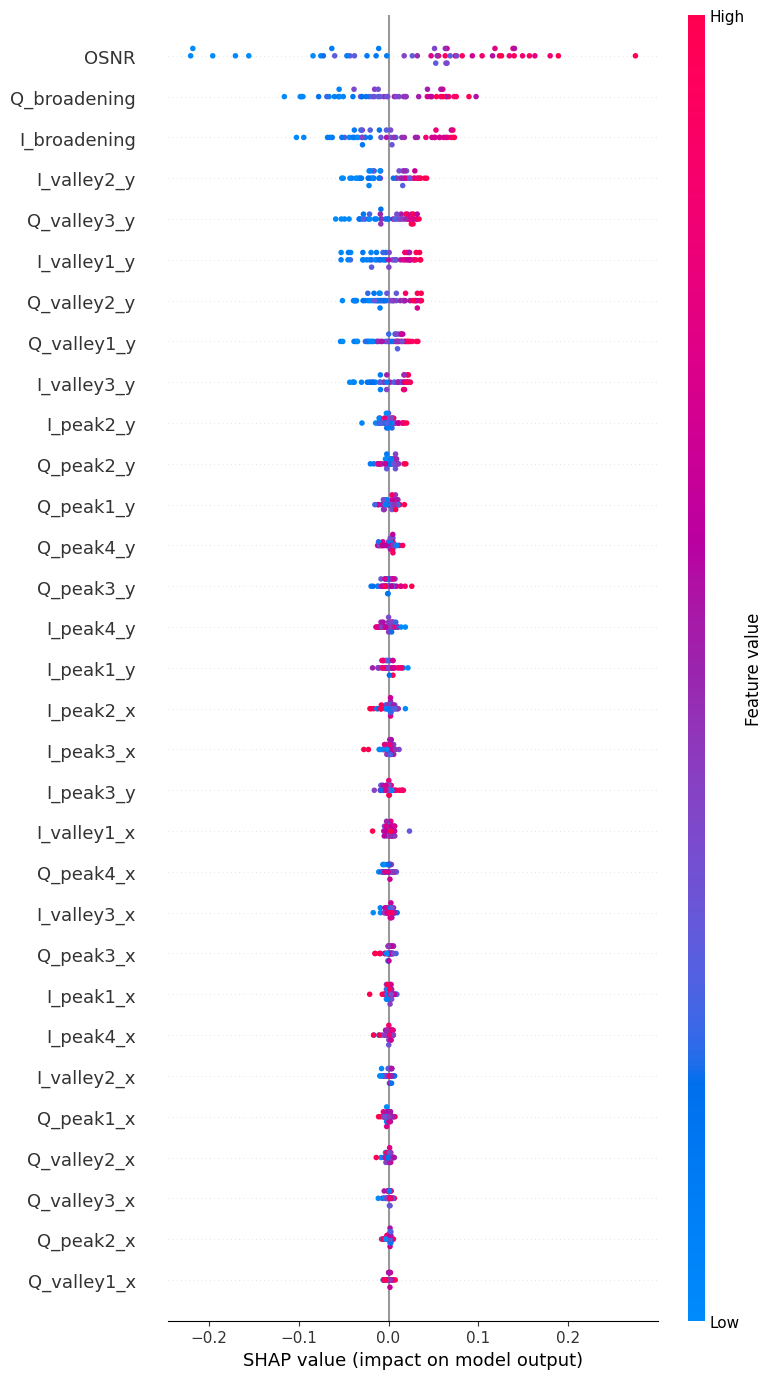

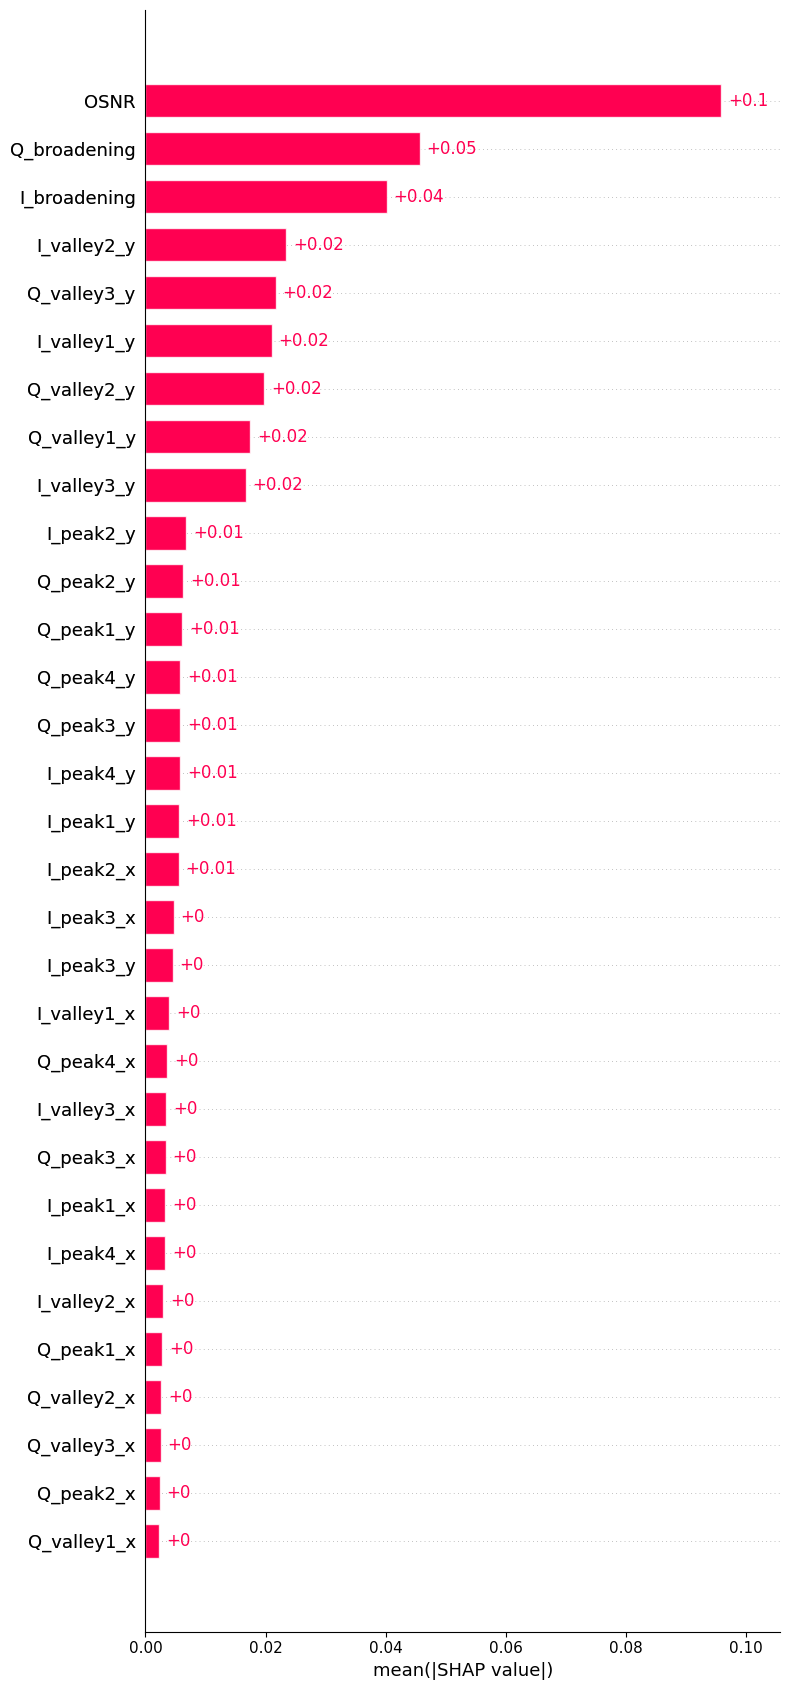

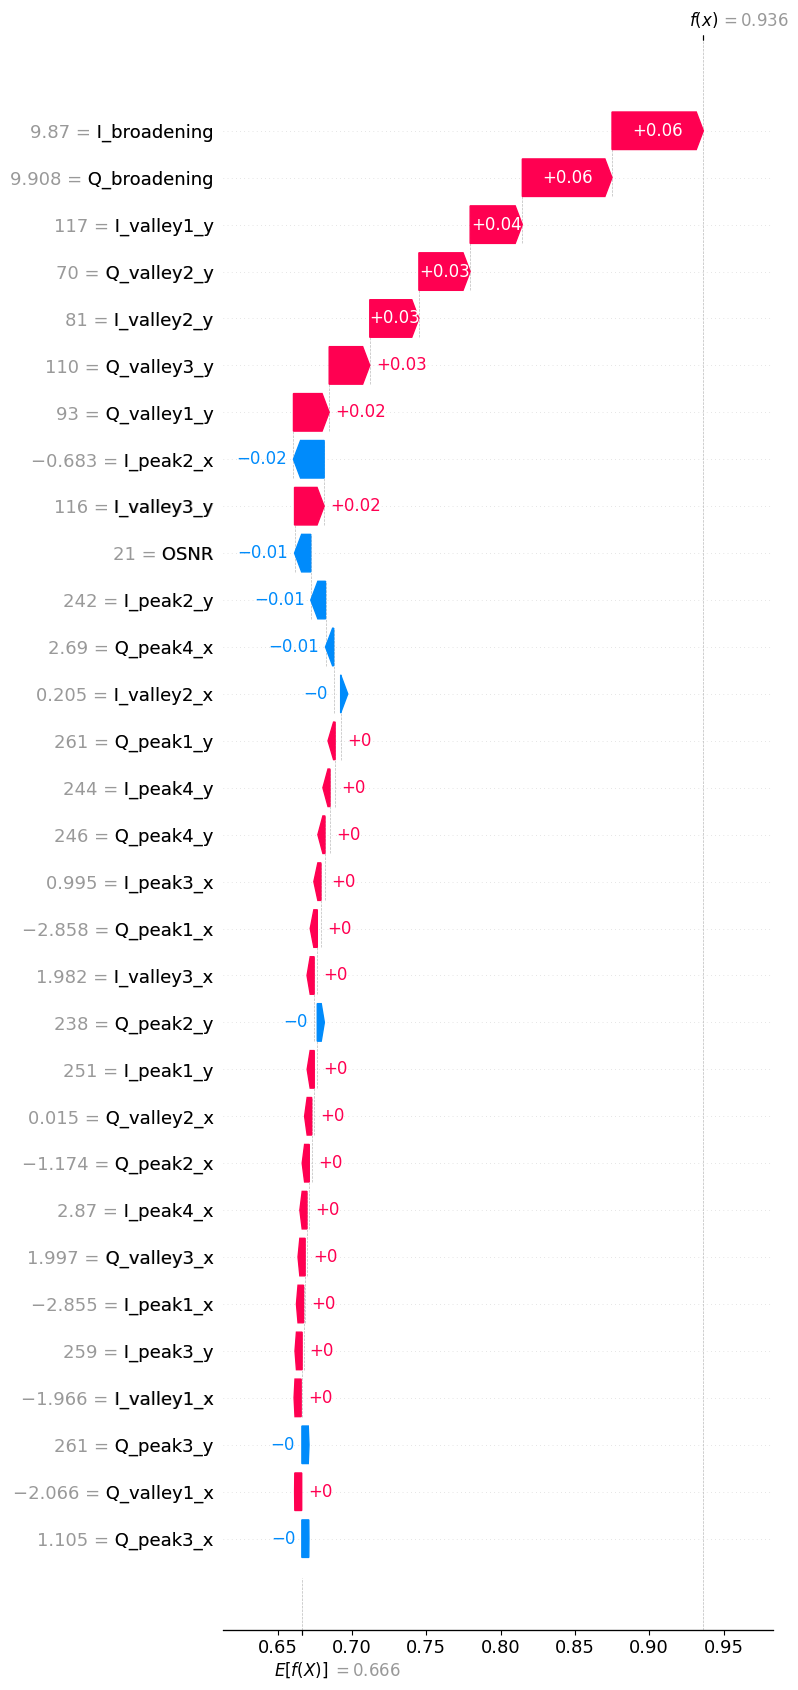


RESUMEN FINAL - RF SPACING 32 GBd
MONITOREO ASISTIDO - NESTED CV 5x5

--- OUTER CV: PROMEDIO ± STD ---
accuracy            : 0.8131 ± 0.0076
precision           : 0.8373 ± 0.0043
recall              : 0.9019 ± 0.0087
f1                  : 0.8684 ± 0.0056
specificity         : 0.6211 ± 0.0109
balanced_accuracy   : 0.7615 ± 0.0078
f1_macro            : 0.7730 ± 0.0087

--- MÉTRICAS GLOBALES OOF ---
Accuracy:          0.8131
Precision ALARMA:  0.8373
Recall ALARMA:     0.9019
F1 ALARMA:         0.8684
Specificity:       0.6211
Balanced Accuracy: 0.7615
F1 Macro:          0.7730

--- TIEMPO DE INFERENCIA ---
Inference: 28.559 ± 6.778 µs/muestra

--- MODELO FINAL ---
Mejores parámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 400}
F1 GridSearch final: 0.8688

--- SHAP ---
Tiempo SHAP: 5.47 s
Top SHAP: OSNR
Importancia relativa: 24.24%

--- ARCHIVOS GENERADOS ---
1. rf_spacing_32GBd_asistido_nested_outer_folds.csv
2. rf_spa

In [ ]:

"""
===============================================================
RANDOM FOREST - CLASIFICACIÓN DE SEPARACIÓN ESPECTRAL
32 GBd - MONITOREO ASISTIDO
NESTED CROSS-VALIDATION 5x5 + PREDICCIONES OOF
===============================================================

ENTRADAS:
    30 características de histogramas I/Q + OSNR

TARGET:
    channel_spacing

CLASES:
    0 = NORMAL: spacing > 35.2 GHz
    1 = ALARMA: spacing <= 35.2 GHz

METODOLOGÍA:
    1. Outer CV estratificada de 5 folds.
    2. Inner CV estratificada de 5 folds.
    3. GridSearchCV optimizando F1 de ALARMA.
    4. Predicciones externas Out-of-Fold.
    5. Métricas por outer fold y métricas globales OOF.
    6. Tiempo de inferencia por outer fold.
    7. Modelo final con GridSearchCV sobre todo el dataset.
    8. SHAP TreeExplainer del modelo final.

IMPORTANTE:
    Las métricas OOF provienen exclusivamente de modelos
    evaluados sobre muestras externas a su entrenamiento.

    SHAP explica el modelo final entrenado con todo X.
    Sus explicaciones no son OOF.
"""

# ============================================================
# 1. IMPORTAR LIBRERÍAS
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 2. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

# Para 32 GBd y roll-off = 0.1:
# BW = Rs * (1 + alpha)
# BW = 32 * 1.1 = 35.2 GHz

THRESHOLD_GHZ = 35.2

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

OUTPUT_PREFIX = "rf_spacing_32GBd_asistido_nested"

# ============================================================
# 3. NOMBRES DE LAS CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "OSNR"]
)

assert len(feature_names) == 31

# ============================================================
# 4. CARGAR Y VALIDAR EL DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura esperada:
#
# Columnas 0-29: características I/Q
# Columna 30: channel_spacing
# Columna 31: OSNR
#
# Total: 32 columnas.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas y "
        f"se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 5. DEFINIR X E y
# ============================================================

# ------------------------------------------------------------
# 5.1 SEPARACIÓN ESPECTRAL REAL
# ------------------------------------------------------------

y_spacing = matriz.iloc[:, 30].to_numpy()

# ------------------------------------------------------------
# 5.2 ENTRADAS DEL MODELO ASISTIDO
# ------------------------------------------------------------

# Se elimina channel_spacing porque es el target.
# Se conserva OSNR como característica auxiliar.

X = matriz.drop(
    columns=matriz.columns[30]
).copy()

X.columns = feature_names

# ------------------------------------------------------------
# 5.3 CLASIFICACIÓN BINARIA
# ------------------------------------------------------------

# NORMAL = 0: spacing > 35.2 GHz
# ALARMA = 1: spacing <= 35.2 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

# Verificar que existan suficientes muestras por clase.
if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar los outer folds."
    )

min_outer_train_class = min(
    count - int(np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar los inner folds."
    )

print("\n" + "=" * 70)
print("DATASET - RANDOM FOREST SPACING 32 GBd")
print("MONITOREO ASISTIDO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma original: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print("\nOSNR incluida como predictor.")
print("channel_spacing excluido de X.")

# ============================================================
# 6. DEFINIR RANDOM FOREST
# ============================================================

def build_rf():
    """
    Construye un RandomForestClassifier nuevo.

    Random Forest no necesita StandardScaler porque
    sus árboles realizan divisiones por umbrales.

    n_jobs=1 dentro del estimador evita paralelismo
    anidado cuando GridSearchCV usa n_jobs=-1.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )

# ============================================================
# 7. GRID DE HIPERPARÁMETROS
# ============================================================

# Se conserva exactamente el grid original.

param_grid = {
    "n_estimators": [
        100, 200, 400
    ],
    "max_depth": [
        None, 10, 20
    ],
    "min_samples_split": [
        2, 5, 10
    ],
    "min_samples_leaf": [
        1, 2, 4
    ],
    "max_features": [
        "sqrt", "log2"
    ]
}

# 3 * 3 * 3 * 3 * 2 = 162 combinaciones.

print("\n" + "=" * 70)
print("GRID SEARCH - RANDOM FOREST")
print("=" * 70)

print("Combinaciones: 162")
print("Criterio de optimización: F1 ALARMA")
print("Outer folds: 5")
print("Inner folds: 5")

# ============================================================
# 8. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# ------------------------------------------------------------
# 8.1 ARREGLOS PARA PREDICCIONES OOF
# ------------------------------------------------------------

# Predicción binaria de cada muestra.
oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# Probabilidad estimada de ALARMA.
oof_prob_alarm = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Fold externo que evaluó cada muestra.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

# Resultados por fold.
outer_results = []

# Hiperparámetros por fold.
outer_best_params = []

# Tiempos de inferencia por fold.
outer_inference_times = []

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE PRINCIPAL: OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 DIVIDIR OUTER TRAIN Y OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(
        f"Outer Train: {len(X_outer_train)} muestras"
    )

    print(
        f"Outer Test:  {len(X_outer_test)} muestras"
    )

    # --------------------------------------------------------
    # 9.2 CONFIGURAR INNER CV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    search = GridSearchCV(
        estimator=build_rf(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=0
    )

    print("\nEjecutando GridSearchCV interno...")

    grid_start = time.perf_counter()

    # IMPORTANTE:
    # Solo se utilizan los datos del outer train.
    #
    # El outer test queda completamente separado
    # de la selección de hiperparámetros.

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    # GridSearchCV ya reentrenó el mejor Random Forest
    # utilizando todo el outer train.

    best_rf = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s"
    )

    # --------------------------------------------------------
    # 9.4 GUARDAR HIPERPARÁMETROS
    # --------------------------------------------------------

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.5 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Predicción sobre muestras que no participaron
    # en entrenamiento ni selección de hiperparámetros.

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad estimada de ALARMA.
    y_outer_prob = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar cada predicción en su posición original.
    oof_predictions[test_idx] = y_outer_pred

    oof_prob_alarm[test_idx] = y_outer_prob

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.6 MATRIZ DE CONFUSIÓN DEL FOLD
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # --------------------------------------------------------
    # 9.7 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    balanced_acc = balanced_accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    f1_macro = f1_score(
        y_outer_test,
        y_outer_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # 9.8 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        # Tiempo promedio por muestra del batch.
        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.9 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "balanced_accuracy": balanced_acc,
        "f1_macro": f1_macro,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Precision ALARMA:  {precision:.4f}")
    print(f"Recall ALARMA:     {recall:.4f}")
    print(f"F1 ALARMA:         {f1:.4f}")
    print(f"Specificity:       {specificity:.4f}")
    print(f"Balanced Accuracy: {balanced_acc:.4f}")
    print(f"F1 Macro:          {f1_macro:.4f}")

    print(
        f"\nInference Mean: "
        f"{inference_mean_us:.3f} µs/muestra"
    )

    print(
        f"Inference Std:  "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold asignado."
    )

if not np.isfinite(oof_prob_alarm).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nPredicciones OOF completadas correctamente.")

# ============================================================
# 11. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 12. OUTER CV: PROMEDIO ± STD
# ============================================================

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "balanced_accuracy",
    "f1_macro"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric:20s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 13. BOXPLOT DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(10, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in metrics
    ],
    labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity",
        "Balanced Acc.",
        "F1 Macro"
    ]
)

plt.ylabel("Score")

plt.title(
    "Random Forest Spacing 32 GBd - Asistido\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 14. MÉTRICAS GLOBALES OOF
# ============================================================

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_oof.ravel()

oof_accuracy = accuracy_score(
    y,
    oof_predictions
)

oof_precision = precision_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_recall = recall_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_f1 = f1_score(
    y,
    oof_predictions,
    zero_division=0
)

oof_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

oof_balanced_acc = balanced_accuracy_score(
    y,
    oof_predictions
)

oof_f1_macro = f1_score(
    y,
    oof_predictions,
    average="macro",
    zero_division=0
)

print(f"Accuracy:          {oof_accuracy:.4f}")
print(f"Precision ALARMA:  {oof_precision:.4f}")
print(f"Recall ALARMA:     {oof_recall:.4f}")
print(f"F1 ALARMA:         {oof_f1:.4f}")
print(f"Specificity:       {oof_specificity:.4f}")
print(f"Balanced Accuracy: {oof_balanced_acc:.4f}")
print(f"F1 Macro:          {oof_f1_macro:.4f}")

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=[
            "NORMAL",
            "ALARMA"
        ],
        zero_division=0
    )
)

# ============================================================
# 15. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "RF Spacing 32 GBd - Asistido\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

print("\nMatriz de confusión OOF normalizada:")
print(cm_oof_norm)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=[
        "NORMAL",
        "ALARMA"
    ]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "RF Spacing 32 GBd - Asistido\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": matriz.iloc[:, 31].to_numpy(),
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_prob_alarm,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

print("\nPredicciones OOF guardadas.")

# ============================================================
# 18. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\n" + "=" * 70)
print("HIPERPARÁMETROS POR OUTER FOLD")
print("=" * 70)

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 19. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# Cinco folds x 100 repeticiones = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean = (
    all_inference_times.mean()
)

inference_std = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean:.3f} µs/muestra"
)

print(
    f"Inference Std:  "
    f"{inference_std:.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "\nTiempo promedio por muestra dentro de un batch."
)

print(
    "No incluye entrenamiento ni GridSearchCV."
)

# ============================================================
# 20. ENTRENAR MODELO FINAL CON TODOS LOS DATOS
# ============================================================

# El modelo final se utiliza para SHAP.
#
# NO se utiliza para calcular las métricas OOF.
#
# Se ejecuta un GridSearchCV adicional sobre todo X
# para seleccionar los hiperparámetros finales.

print("\n" + "=" * 70)
print("ENTRENANDO MODELO FINAL RANDOM FOREST")
print("=" * 70)

final_inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_rf(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=0
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_rf = final_search.best_estimator_

print("\nMejores parámetros finales:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

# ============================================================
# 21. SHAP - TREEEXPLAINER
# ============================================================

# SHAP explicará la salida:
#
#     P(ALARMA) = predict_proba[:, 1]
#
# Un valor SHAP positivo aumenta la probabilidad
# estimada de ALARMA respecto al valor base.
#
# Un valor SHAP negativo la disminuye.
#
# IMPORTANTE:
# Estas explicaciones corresponden al modelo final
# entrenado con todo el dataset.
# NO son explicaciones OOF.

print("\n" + "=" * 70)
print("CALCULANDO SHAP DEL MODELO FINAL")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

# ------------------------------------------------------------
# 21.1 CREAR TREEEXPLAINER
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

# ------------------------------------------------------------
# 21.2 CALCULAR VALORES SHAP
# ------------------------------------------------------------

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

shap_time = (
    time.perf_counter() - shap_start
)

print(
    f"\nTiempo SHAP: "
    f"{shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 22. EXTRAER SHAP DE LA CLASE ALARMA
# ============================================================

# SHAP puede devolver:
#
# Versiones antiguas:
#     lista con un array por clase.
#
# Versiones recientes:
#     array de dimensiones:
#     (muestras, características, clases).
#
# Queremos exclusivamente la clase ALARMA = 1.

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if arr.ndim == 3 and arr.shape[2] == 2:

        shap_values = arr[:, :, 1]

    elif arr.ndim == 2:

        shap_values = arr

    else:

        raise ValueError(
            f"Forma SHAP inesperada: {arr.shape}"
        )

if shap_values.shape != explained.shape:

    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba {explained.shape}."
    )

# ============================================================
# 23. VALOR BASE SHAP DE ALARMA
# ============================================================

base = np.asarray(
    explainer.expected_value
)

if base.size == 2:

    base_alarm = float(
        base.reshape(-1)[1]
    )

else:

    base_alarm = float(
        base.item()
    )

# ============================================================
# 24. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df[
    "mean_abs_shap"
].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 *
        imp_df["mean_abs_shap"] /
        total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 31 CARACTERÍSTICAS")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 SHAP:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 25. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 26. GRÁFICA SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. GRÁFICA SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. GRÁFICA SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 29. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - RF SPACING 32 GBd")
print("MONITOREO ASISTIDO - NESTED CV 5x5")
print("=" * 70)

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metrics:

    values = results_df[
        metric
    ].to_numpy()

    print(
        f"{metric:20s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

print(
    f"Accuracy:          {oof_accuracy:.4f}"
)

print(
    f"Precision ALARMA:  {oof_precision:.4f}"
)

print(
    f"Recall ALARMA:     {oof_recall:.4f}"
)

print(
    f"F1 ALARMA:         {oof_f1:.4f}"
)

print(
    f"Specificity:       {oof_specificity:.4f}"
)

print(
    f"Balanced Accuracy: {oof_balanced_acc:.4f}"
)

print(
    f"F1 Macro:          {oof_f1_macro:.4f}"
)

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean:.3f} "
    f"± {inference_std:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print("Mejores parámetros:")
print(final_search.best_params_)

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print("\n--- SHAP ---")

print(
    f"Tiempo SHAP: {shap_time:.2f} s"
)

print(
    f"Top SHAP: "
    f"{imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia relativa: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(
    f"1. {OUTPUT_PREFIX}_outer_folds.csv"
)

print(
    f"2. {OUTPUT_PREFIX}_oof_predictions.csv"
)

print(
    f"3. {OUTPUT_PREFIX}_best_params.csv"
)

print(
    f"4. {OUTPUT_PREFIX}_importancia_shap.csv"
)

print("\nPROCESO COMPLETADO.")


## SVM 32GBd para clasificar SEPARACIÓN ESPECTRAL CON OSNR

SVM SPACING 32 GBd - MONITOREO ASISTIDO
Dataset: matriz32GBd_clasifi_correct.csv
Forma matriz: (9330, 32)
Forma X: (9330, 31)
Total muestras: 9330
NORMAL: 2951
ALARMA: 6379
Características: 30 I/Q + OSNR
Target: channel_spacing

Configuración GridSearchCV:
Kernels: Linear y RBF
Combinaciones: 20
Scoring: F1 de ALARMA
Nested CV: 5 outer x 5 inner

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: 7464
Outer Test:  1866

Ejecutando GridSearchCV...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores parámetros:
{'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Mejor F1 Inner CV: 0.8449
Tiempo GridSearchCV: 20.50 s

MÉTRICAS OUTER FOLD:
Accuracy:          0.7819
Precision ALARMA:  0.8133
Recall ALARMA:     0.8840
F1 ALARMA:         0.8472
Specificity:       0.5610
Balanced Accuracy: 0.7225
F1 Macro:          0.7332
Inference: 176.513 ± 0.687 µs/muestra

OUTER FOLD 2/5
Outer Train: 7464
Outer Test:  1866

Ejecutando GridSearchCV...
Fitting 5 fold

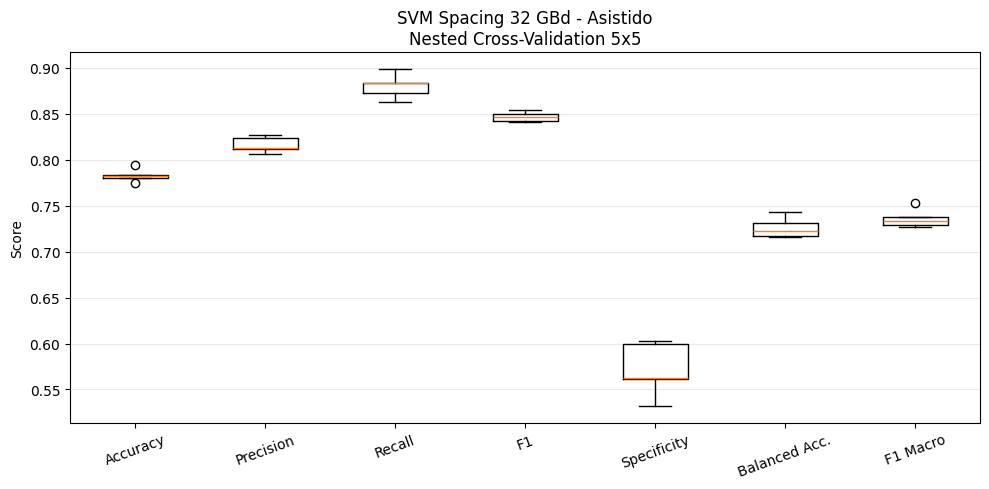


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy            : 0.7827
precision           : 0.8163
recall              : 0.8804
f1                  : 0.8471
specificity         : 0.5717
balanced_accuracy   : 0.7260
f1_macro            : 0.7359

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.69      0.57      0.62      2951
      ALARMA       0.82      0.88      0.85      6379

    accuracy                           0.78      9330
   macro avg       0.75      0.73      0.74      9330
weighted avg       0.78      0.78      0.78      9330


Matriz de confusión OOF:
[[1687 1264]
 [ 763 5616]]


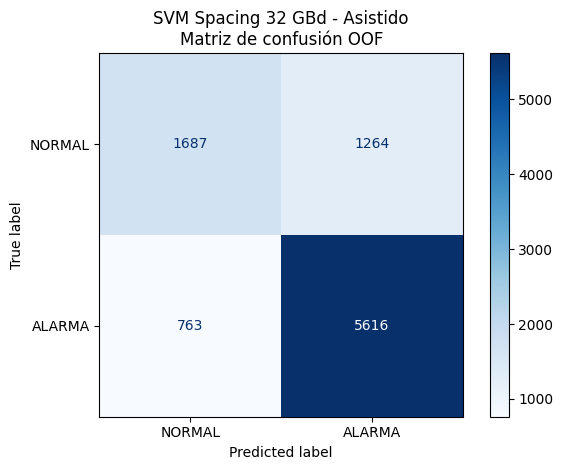

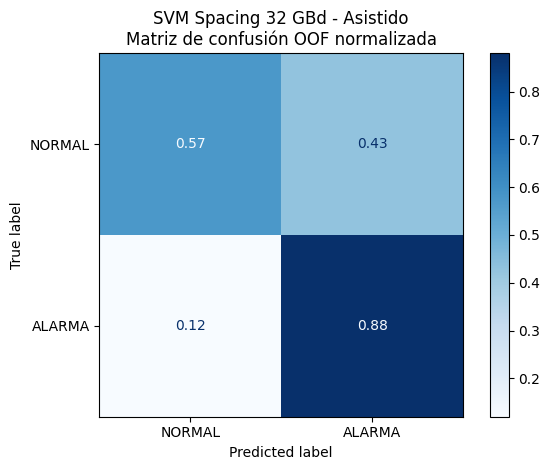


HIPERPARÁMETROS POR OUTER FOLD:
 fold  svm__C svm__gamma svm__kernel  inner_cv_best_f1  grid_time_s
    1       1      scale         rbf          0.844915    20.503703
    2       1      scale         rbf          0.846529    18.664289
    3       1      scale         rbf          0.848915    17.984734
    4       1       0.01         rbf          0.843990    17.170380
    5       1      scale         rbf          0.843512    18.833571

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 175.879 µs/muestra
Inference Std: 0.757 µs/muestra
Mediciones: 500
Incluye StandardScaler y SVM.predict().
No incluye entrenamiento ni GridSearchCV.

GRID SEARCH FINAL - TODO EL DATASET
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros finales:
{'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Mejor F1 GridSearch final: 0.8478
Tiempo GridSearch final: 26.78 s

MODELO FINAL:
Kernel: rbf
C: 1
Gamma: scale
Tiempo entrenamiento final: 6.75 s

SHAP - MODELO FINAL
B

  0%|          | 0/20 [00:00<?, ?it/s]


Tiempo SHAP: 17.40 s (0.29 min)

RANKING SHAP - 31 CARACTERÍSTICAS
     feature mean_abs_shap importance_percent
        OSNR      0.226389             47.20%
Q_broadening      0.055957             11.67%
I_broadening      0.038497              8.03%
 I_valley1_y      0.035599              7.42%
 Q_valley2_y      0.018815              3.92%
 I_valley2_y      0.017156              3.58%
 Q_valley3_y      0.017004              3.55%
 I_valley3_y      0.009450              1.97%
   I_peak4_y      0.008877              1.85%
 Q_valley1_y      0.007482              1.56%
   I_peak3_x      0.006433              1.34%
   I_peak2_x      0.004726              0.99%
   Q_peak3_x      0.004684              0.98%
   I_peak4_x      0.004441              0.93%
 I_valley3_x      0.003191              0.67%
 I_valley2_x      0.002959              0.62%
   Q_peak2_y      0.002803              0.58%
 Q_valley3_x      0.002377              0.50%
   Q_peak4_x      0.002368              0.49%
   I_peak2_y

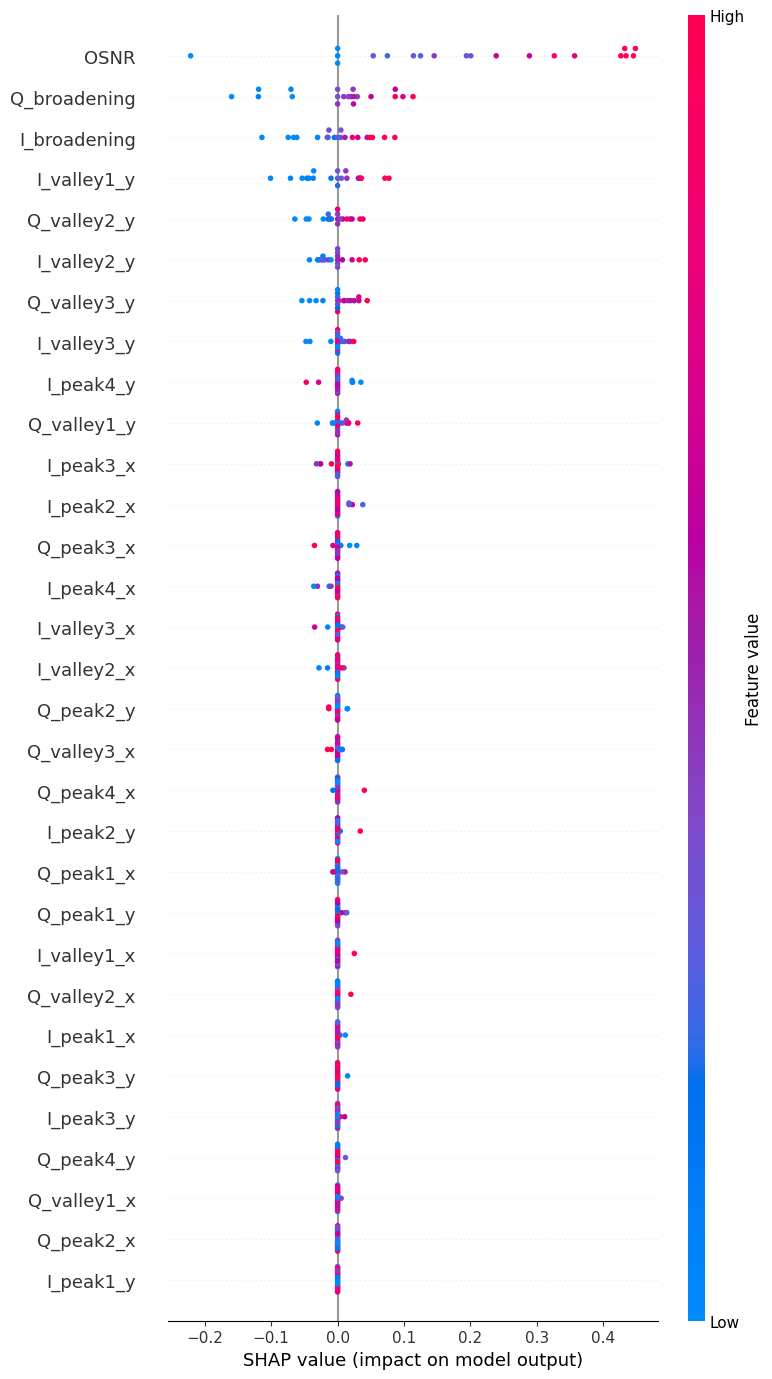

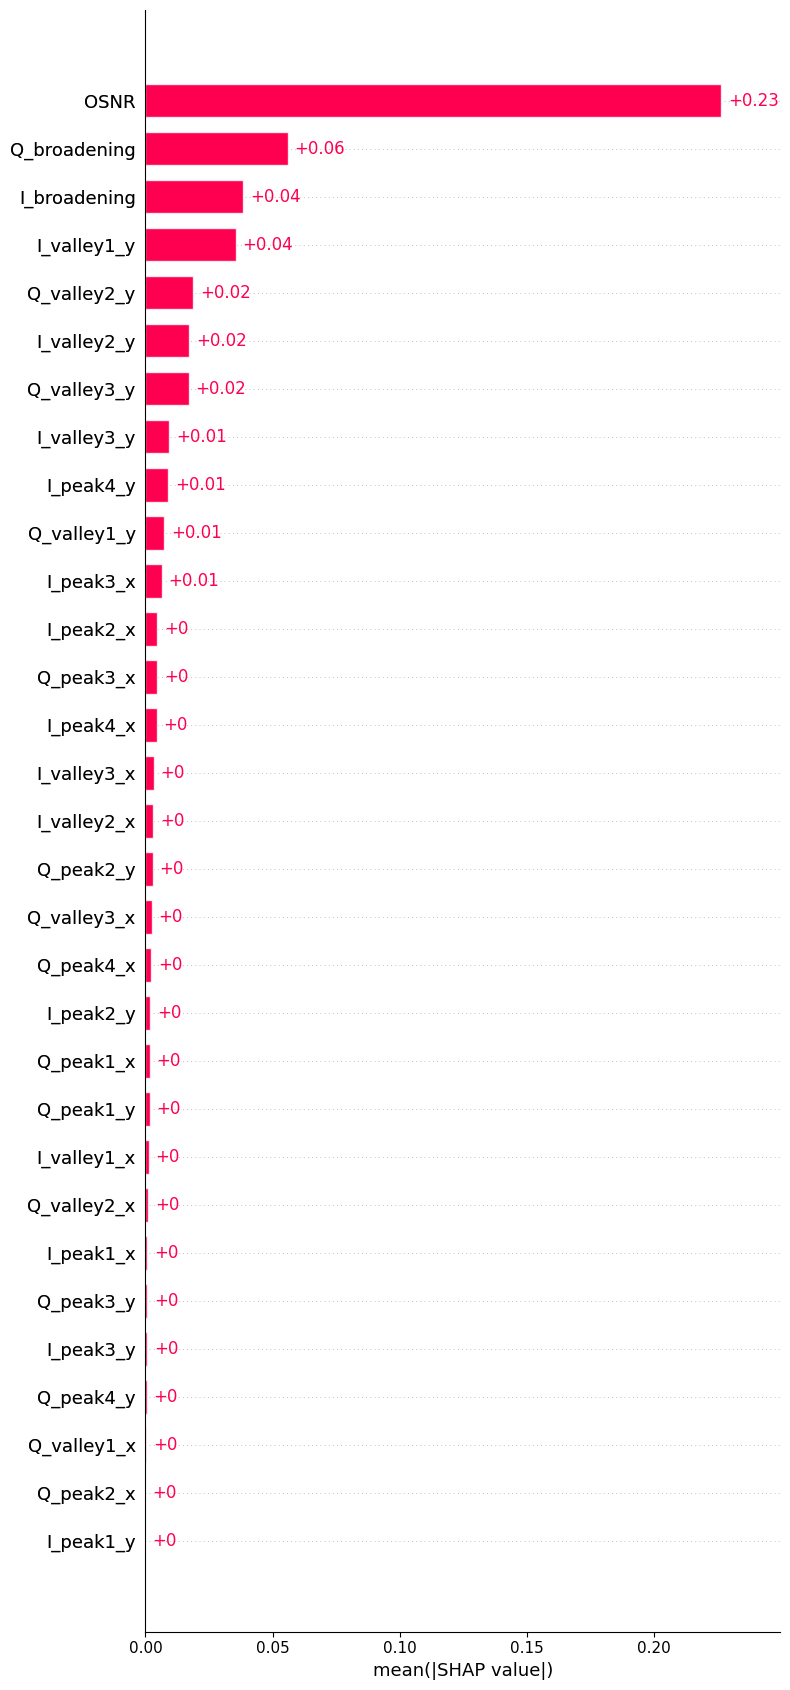

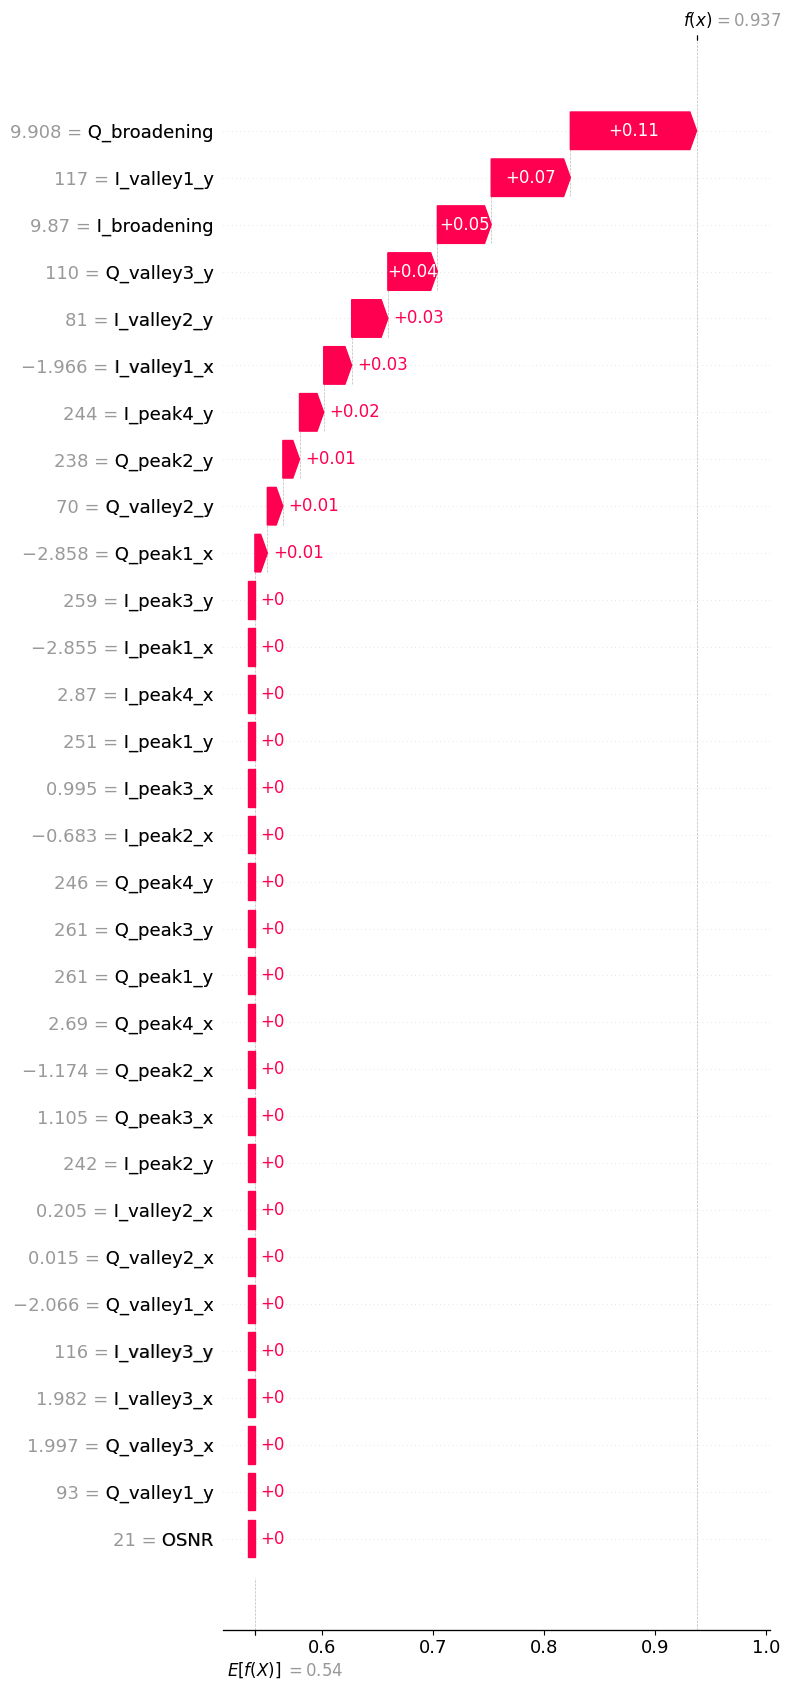


RESUMEN FINAL - SVM SPACING 32 GBd
MONITOREO ASISTIDO - NESTED CV 5x5

--- OUTER CV: PROMEDIO ± STD ---
accuracy            : 0.7827 ± 0.0067
precision           : 0.8164 ± 0.0079
recall              : 0.8804 ± 0.0122
f1                  : 0.8471 ± 0.0050
specificity         : 0.5717 ± 0.0264
balanced_accuracy   : 0.7260 ± 0.0102
f1_macro            : 0.7358 ± 0.0092

--- MÉTRICAS GLOBALES OOF ---
accuracy            : 0.7827
precision           : 0.8163
recall              : 0.8804
f1                  : 0.8471
specificity         : 0.5717
balanced_accuracy   : 0.7260
f1_macro            : 0.7359

--- TIEMPO DE INFERENCIA ---
Inference: 175.879 ± 0.757 µs/muestra

--- MODELO FINAL ---
Kernel: rbf
C: 1
Gamma: scale
F1 GridSearch final: 0.8478
GridSearch final: 26.78 s
Entrenamiento probabilístico: 6.75 s

--- SHAP ---
Tiempo SHAP: 17.40 s
Top SHAP: OSNR
Importancia: 47.20%

--- ARCHIVOS GENERADOS ---
1. svm_spacing_32GBd_asistido_nested_outer_folds.csv
2. svm_spacing_32GBd_asistido_nes

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

# 32 GBd, roll-off = 0.1 -> BW = 35.2 GHz
THRESHOLD_GHZ = 35.2

SEED = 42
N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

# Se conservan los valores reducidos del código original.
SHAP_BACKGROUND = 20
SHAP_EXPLAIN = 20
SHAP_NSAMPLES = 200

OUTPUT_PREFIX = "svm_spacing_32GBd_asistido_nested"

# ============================================================
# 2. CARACTERÍSTICAS
# ============================================================

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "OSNR"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATOS
# ============================================================

matriz = pd.read_csv(CSV_PATH, header=None)

# Columnas:
# 0-29 -> 30 características I/Q
# 30   -> channel_spacing
# 31   -> OSNR

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas, "
        f"pero se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(pd.to_numeric, errors="raise")

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError("El CSV contiene NaN o infinitos.")

# Variable física que queremos clasificar.
y_spacing = matriz.iloc[:, 30].to_numpy()

# Monitoreo asistido:
# X = 30 características I/Q + OSNR.
# Se excluye channel_spacing porque es el target.
X = matriz.drop(columns=matriz.columns[30]).copy()
X.columns = feature_names

# 0 = NORMAL: spacing > 35.2 GHz
# 1 = ALARMA: spacing <= 35.2 GHz
y = (y_spacing <= THRESHOLD_GHZ).astype(int)

n_samples = len(y)
class_counts = np.bincount(y, minlength=2)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras de ambas clases "
        "para ejecutar Outer CV."
    )

min_outer_train_class = min(
    count - int(np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Inner CV."
    )

print("=" * 70)
print("SVM SPACING 32 GBd - MONITOREO ASISTIDO")
print("=" * 70)
print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")
print(f"NORMAL: {class_counts[0]}")
print(f"ALARMA: {class_counts[1]}")
print("Características: 30 I/Q + OSNR")
print("Target: channel_spacing")

# ============================================================
# 4. PIPELINE SVM
# ============================================================

def build_svm(probability=False):
    """
    Crea un pipeline nuevo:

        StandardScaler -> SVC

    El StandardScaler se ajusta dentro de cada fold,
    evitando fuga de información del conjunto test.

    Durante GridSearchCV:
        probability=False -> entrenamiento más rápido.

    Para SHAP del modelo final:
        probability=True -> permite predict_proba().
    """

    return Pipeline([
        ("scaler", StandardScaler()),
        (
            "svm",
            SVC(
                probability=probability,
                random_state=SEED
            )
        )
    ])

# ============================================================
# 5. GRID DE HIPERPARÁMETROS
# ============================================================

# Conservamos el grid reducido del código original.
#
# Linear:
#     4 valores de C -> 4 combinaciones.
#
# RBF:
#     4 valores de C x 4 gamma -> 16 combinaciones.
#
# Total = 20 combinaciones.

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1, 1]
    }
]

print("\nConfiguración GridSearchCV:")
print("Kernels: Linear y RBF")
print("Combinaciones: 20")
print("Scoring: F1 de ALARMA")
print("Nested CV: 5 outer x 5 inner")

# ============================================================
# 6. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una predicción OOF.
oof_predictions = np.full(
    n_samples, -1, dtype=int
)

# Guardaremos decision_function, no predict_proba.
# Así evitamos entrenar modelos probabilísticos
# durante cada outer fold.
oof_decision_scores = np.full(
    n_samples, np.nan, dtype=float
)

oof_fold = np.full(
    n_samples, -1, dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 7. BUCLE PRINCIPAL: OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 7.1 OUTER TRAIN / OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {len(train_idx)}")
    print(f"Outer Test:  {len(test_idx)}")

    # --------------------------------------------------------
    # 7.2 INNER CV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 7.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    # Solo recibe X_outer_train y y_outer_train.
    # Nunca utiliza muestras del outer test.
    search = GridSearchCV(
        estimator=build_svm(probability=False),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    print("\nEjecutando GridSearchCV...")

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = time.perf_counter() - grid_start

    # GridSearchCV reentrena el mejor pipeline
    # sobre todo el outer train.
    best_svm = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 7.4 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Estas predicciones son externas a la búsqueda
    # y al entrenamiento del modelo de este fold.
    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    # Puntuación de decisión del SVM.
    # NO es una probabilidad.
    y_outer_score = best_svm.decision_function(
        X_outer_test
    )

    # Reconstruir las predicciones OOF en el orden
    # original del dataset.
    oof_predictions[test_idx] = y_outer_pred
    oof_decision_scores[test_idx] = y_outer_score
    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 7.5 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_outer_test,
        y_outer_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(
        y_outer_test, y_outer_pred
    )

    precision = precision_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    recall = recall_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if tn + fp > 0
        else np.nan
    )

    balanced_acc = balanced_accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    f1_macro = f1_score(
        y_outer_test,
        y_outer_pred,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # 7.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_svm.predict(
        X_outer_test.iloc[:min(10, len(X_outer_test))]
    )

    inference_times = np.empty(N_REPETITIONS)

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(X_outer_test)

        elapsed = time.perf_counter() - start

        # Tiempo promedio por muestra dentro del batch.
        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = inference_times.mean() * 1e6
    inference_std_us = inference_times.std() * 1e6

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 7.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "specificity": specificity,
        "balanced_accuracy": balanced_acc,
        "f1_macro": f1_macro,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")
    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Precision ALARMA:  {precision:.4f}")
    print(f"Recall ALARMA:     {recall:.4f}")
    print(f"F1 ALARMA:         {f1:.4f}")
    print(f"Specificity:       {specificity:.4f}")
    print(f"Balanced Accuracy: {balanced_acc:.4f}")
    print(f"F1 Macro:          {f1_macro:.4f}")

    print(
        f"Inference: {inference_mean_us:.3f} "
        f"± {inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 8. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_decision_scores).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print("\nPredicciones OOF completadas.")

# ============================================================
# 9. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(outer_results)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(results_df.to_string(index=False))

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 10. PROMEDIO Y DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "balanced_accuracy",
    "f1_macro"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metrics:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:20s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 11. BOXPLOT DE MÉTRICAS OUTER CV
# ============================================================

plt.figure(figsize=(10, 5))

plt.boxplot(
    [results_df[m].values for m in metrics],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Specificity",
        "Balanced Acc.",
        "F1 Macro"
    ]
)

plt.ylabel("Score")

plt.title(
    "SVM Spacing 32 GBd - Asistido\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 12. MÉTRICAS GLOBALES OOF
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_oof.ravel()

oof_metrics = {
    "accuracy": accuracy_score(
        y, oof_predictions
    ),
    "precision": precision_score(
        y, oof_predictions, zero_division=0
    ),
    "recall": recall_score(
        y, oof_predictions, zero_division=0
    ),
    "f1": f1_score(
        y, oof_predictions, zero_division=0
    ),
    "specificity": (
        tn / (tn + fp)
        if tn + fp > 0
        else np.nan
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y, oof_predictions
    ),
    "f1_macro": f1_score(
        y,
        oof_predictions,
        average="macro",
        zero_division=0
    )
}

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():
    print(f"{metric:20s}: {value:.4f}")

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

# ============================================================
# 13. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Spacing 32 GBd - Asistido\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 14. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "SVM Spacing 32 GBd - Asistido\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. GUARDAR PREDICCIONES OOF
# ============================================================

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": matriz.iloc[:, 31].to_numpy(),
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score_alarm": oof_decision_scores,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 16. GUARDAR HIPERPARÁMETROS POR FOLD
# ============================================================

params_df = pd.DataFrame(outer_best_params)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")
print(params_df.to_string(index=False))

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 17. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean = all_inference_times.mean()
inference_std = all_inference_times.std()

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std:.3f} µs/muestra"
)

print(
    f"Mediciones: {len(all_inference_times)}"
)

print(
    "Incluye StandardScaler y SVM.predict()."
)

print(
    "No incluye entrenamiento ni GridSearchCV."
)

# ============================================================
# 18. GRIDSEARCHCV FINAL SOBRE TODO EL DATASET
# ============================================================

# Este GridSearchCV es independiente de las métricas OOF.
#
# Su finalidad es seleccionar el modelo final que se
# utilizará para el análisis SHAP.
#
# Durante la búsqueda mantenemos probability=False.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - TODO EL DATASET")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_svm(probability=False),
    param_grid=param_grid,
    scoring="f1",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

print("\nMejores hiperparámetros finales:")
print(final_best_params)

print(
    f"Mejor F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

# ============================================================
# 19. CREAR MODELO FINAL CON probability=True
# ============================================================

# El GridSearchCV ya seleccionó kernel, C y gamma.
#
# Ahora entrenamos un SVM probabilístico usando esos
# hiperparámetros para poder explicar P(ALARMA).
#
# IMPORTANTE:
# SVC(probability=True) utiliza calibración probabilística
# interna. Por ello este modelo puede producir algunas
# predicciones distintas del SVC(probability=False).
#
# Las métricas OOF siguen correspondiendo exclusivamente
# a los modelos externos con probability=False.

best_kernel = final_best_params["svm__kernel"]
best_C = final_best_params["svm__C"]
best_gamma = final_best_params.get(
    "svm__gamma",
    "scale"
)

final_svm = Pipeline([
    ("scaler", StandardScaler()),
    (
        "svm",
        SVC(
            kernel=best_kernel,
            C=best_C,
            gamma=best_gamma,
            probability=True,
            random_state=SEED
        )
    )
])

final_train_start = time.perf_counter()

final_svm.fit(X, y)

final_train_time = (
    time.perf_counter() - final_train_start
)

print("\nMODELO FINAL:")
print(f"Kernel: {best_kernel}")
print(f"C: {best_C}")

if best_kernel == "rbf":
    print(f"Gamma: {best_gamma}")

print(
    f"Tiempo entrenamiento final: "
    f"{final_train_time:.2f} s"
)

# ============================================================
# 20. SHAP - KERNELEXPLAINER
# ============================================================

# Explicaremos:
#
#     P(ALARMA | X)
#
# SHAP positivo:
#     Aumenta la probabilidad estimada de ALARMA.
#
# SHAP negativo:
#     Disminuye la probabilidad estimada de ALARMA.
#
# Estas explicaciones NO son OOF.
# Se obtienen del modelo final entrenado con todo X.

print("\n" + "=" * 70)
print("SHAP - MODELO FINAL")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(f"Background: {len(background)}")
print(f"Muestras explicadas: {len(explained)}")
print(f"SHAP nsamples: {SHAP_NSAMPLES}")

# ------------------------------------------------------------
# 20.1 FUNCIÓN DE PROBABILIDAD PARA SHAP
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe una matriz de 31 características.

    Devuelve la probabilidad estimada de pertenecer
    a la clase ALARMA = 1.
    """

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.predict_proba(data)[:, 1]

# ------------------------------------------------------------
# 20.2 CALCULAR VALORES SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw_shap = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = (
    time.perf_counter() - shap_start
)

shap_values = np.asarray(raw_shap)

# Para una función con salida escalar por muestra,
# esperamos una matriz:
#
# (n_muestras_explicadas, 31 características)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: {shap_values.shape}. "
        f"Se esperaba {explained.shape}"
    )

base_alarm = float(
    np.asarray(explainer.expected_value).item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 21. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:
    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )
else:
    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 31 CARACTERÍSTICAS")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 SHAP:")
print(imp_df.head(5).to_string(index=False))

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 22. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 23. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 24. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 25. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 26. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - SVM SPACING 32 GBd")
print("MONITOREO ASISTIDO - NESTED CV 5x5")
print("=" * 70)

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metrics:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:20s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():
    print(f"{metric:20s}: {value:.4f}")

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean:.3f} "
    f"± {inference_std:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print(f"Kernel: {best_kernel}")
print(f"C: {best_C}")

if best_kernel == "rbf":
    print(f"Gamma: {best_gamma}")

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"GridSearch final: {final_grid_time:.2f} s"
)

print(
    f"Entrenamiento probabilístico: "
    f"{final_train_time:.2f} s"
)

print("\n--- SHAP ---")

print(f"Tiempo SHAP: {shap_time:.2f} s")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 32GBd para clasificar SEPARACIÓN ESPECTRAL CON OSNR


KNN - SPACING 32 GBd - MONITOREO ASISTIDO
Dataset: matriz32GBd_clasifi_correct.csv
Forma matriz: (9330, 32)
Forma X: (9330, 31)
Total muestras: 9330
NORMAL (> 35.2 GHz): 2951
ALARMA (<= 35.2 GHz): 6379
Características: 30 I/Q + OSNR
Criterio de optimización: F1-MACRO

GRID SEARCH:
Combinaciones: 84
Scoring: f1_macro
Outer folds: 5
Inner folds: 5

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: (7464, 31)
Outer Test:  (1866, 31)
Fitting 5 folds for each of 84 candidates, totalling 420 fits

Mejores parámetros:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Mejor F1-Macro Inner CV: 0.6753
Tiempo GridSearchCV: 1.30 s

MÉTRICAS OUTER FOLD:
accuracy              : 0.7095
balanced_accuracy     : 0.6368
f1_macro              : 0.6429
precision_alarm       : 0.7629
recall_alarm          : 0.8346
f1_alarm              : 0.7972
precision_normal      : 0.5511
recall_normal         : 0.4390
f1_normal             : 0.4887
specificity 

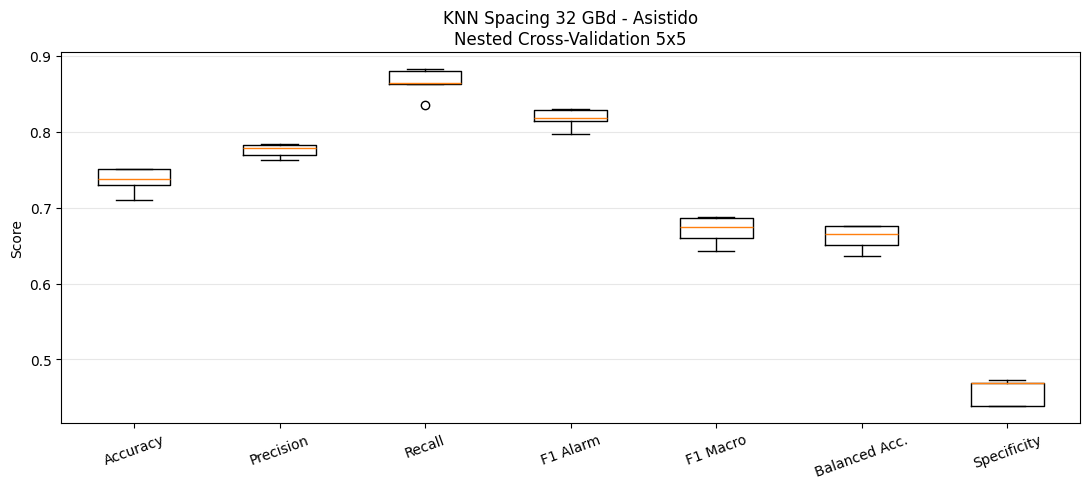


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy              : 0.7358
balanced_accuracy     : 0.6611
f1_macro              : 0.6701
precision_alarm       : 0.7751
recall_alarm          : 0.8644
f1_alarm              : 0.8173
precision_normal      : 0.6097
recall_normal         : 0.4578
f1_normal             : 0.5229
specificity           : 0.4578

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.61      0.46      0.52      2951
      ALARMA       0.78      0.86      0.82      6379

    accuracy                           0.74      9330
   macro avg       0.69      0.66      0.67      9330
weighted avg       0.72      0.74      0.72      9330


Matriz de confusión OOF:
[[1351 1600]
 [ 865 5514]]


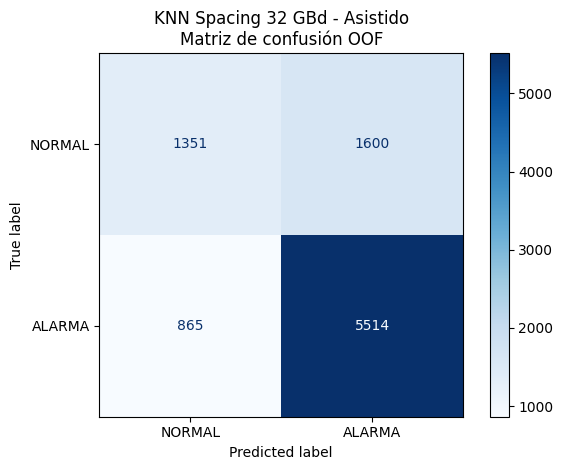

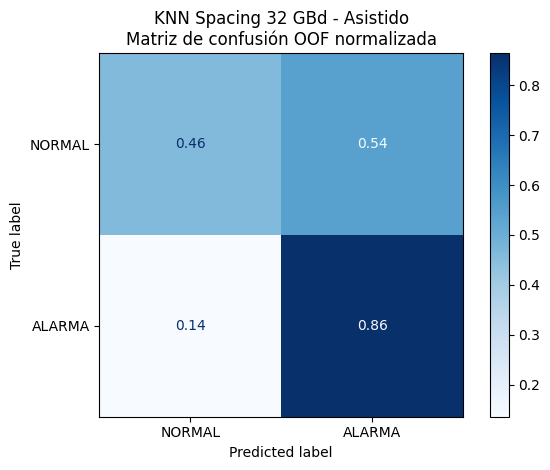


HIPERPARÁMETROS POR OUTER FOLD:
 fold knn__metric  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1_macro  grid_time_s
    1   manhattan                 7       1      uniform                0.675293     1.302137
    2   manhattan                21       1     distance                0.671533     1.240819
    3   manhattan                21       1      uniform                0.671783     1.233106
    4   manhattan                21       1     distance                0.669976     1.234134
    5   manhattan                21       1      uniform                0.668353     1.239038

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 11.403 µs/muestra
Inference Std: 0.642 µs/muestra
Mediciones totales: 500
Incluye StandardScaler y KNN.predict().
No incluye GridSearchCV ni entrenamiento.

GRID SEARCH FINAL - TODO EL DATASET
Fitting 5 folds for each of 84 candidates, totalling 420 fits

Mejores hiperparámetros finales:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 15, 'knn__p': 1,

  0%|          | 0/50 [00:00<?, ?it/s]


Tiempo SHAP: 2.95 s (0.05 min)

RANKING SHAP - 31 CARACTERÍSTICAS
     feature mean_abs_shap importance_percent
        OSNR      0.075810             17.71%
I_broadening      0.036969              8.64%
Q_broadening      0.031703              7.41%
 I_valley2_y      0.018146              4.24%
 Q_valley3_y      0.015687              3.67%
 Q_valley2_y      0.015525              3.63%
 I_valley1_y      0.015461              3.61%
   I_peak4_x      0.014671              3.43%
 I_valley1_x      0.014338              3.35%
 I_valley3_y      0.013001              3.04%
 Q_valley1_y      0.012790              2.99%
   I_peak2_x      0.012758              2.98%
   Q_peak2_x      0.011690              2.73%
   I_peak4_y      0.011454              2.68%
   Q_peak2_y      0.010671              2.49%
   Q_peak1_y      0.010036              2.35%
   Q_peak4_y      0.009511              2.22%
   Q_peak4_x      0.009487              2.22%
   I_peak3_y      0.009213              2.15%
   I_peak3_x 

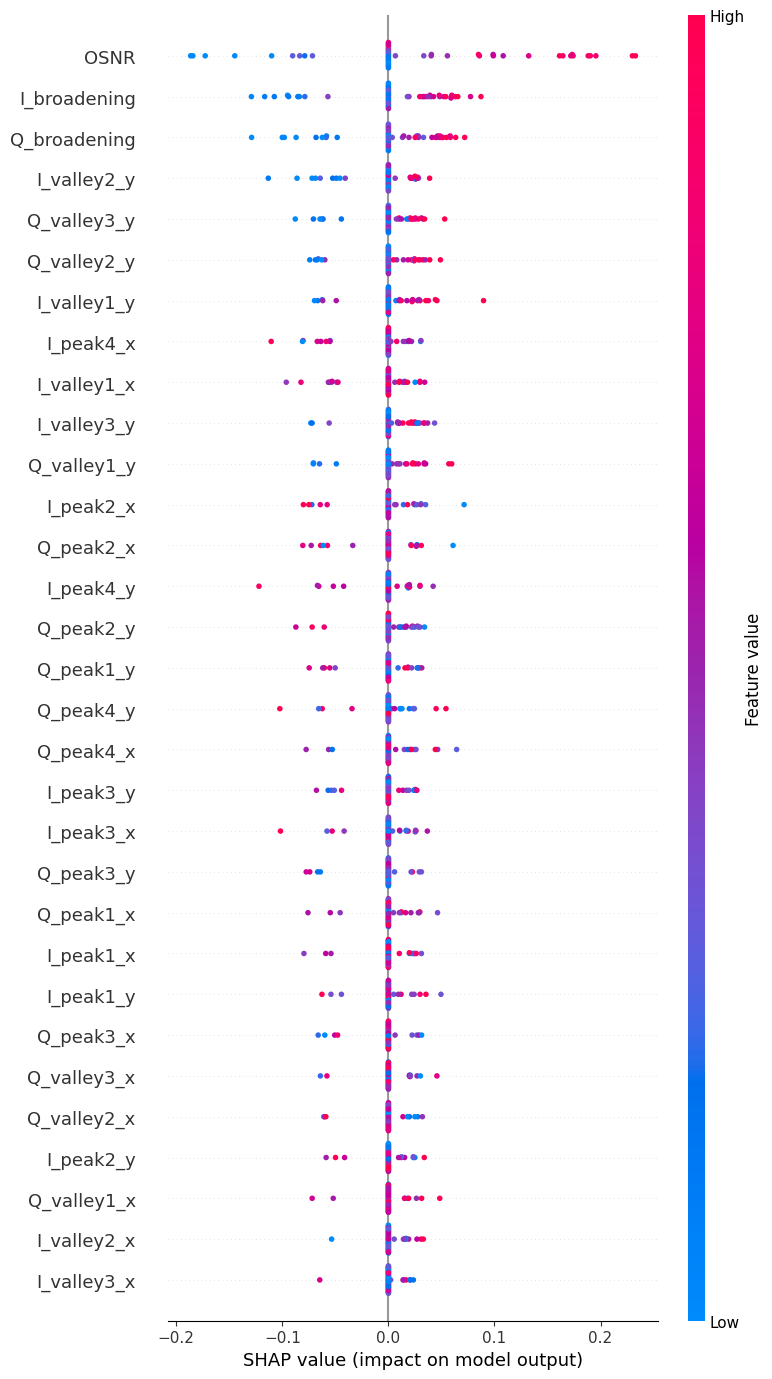

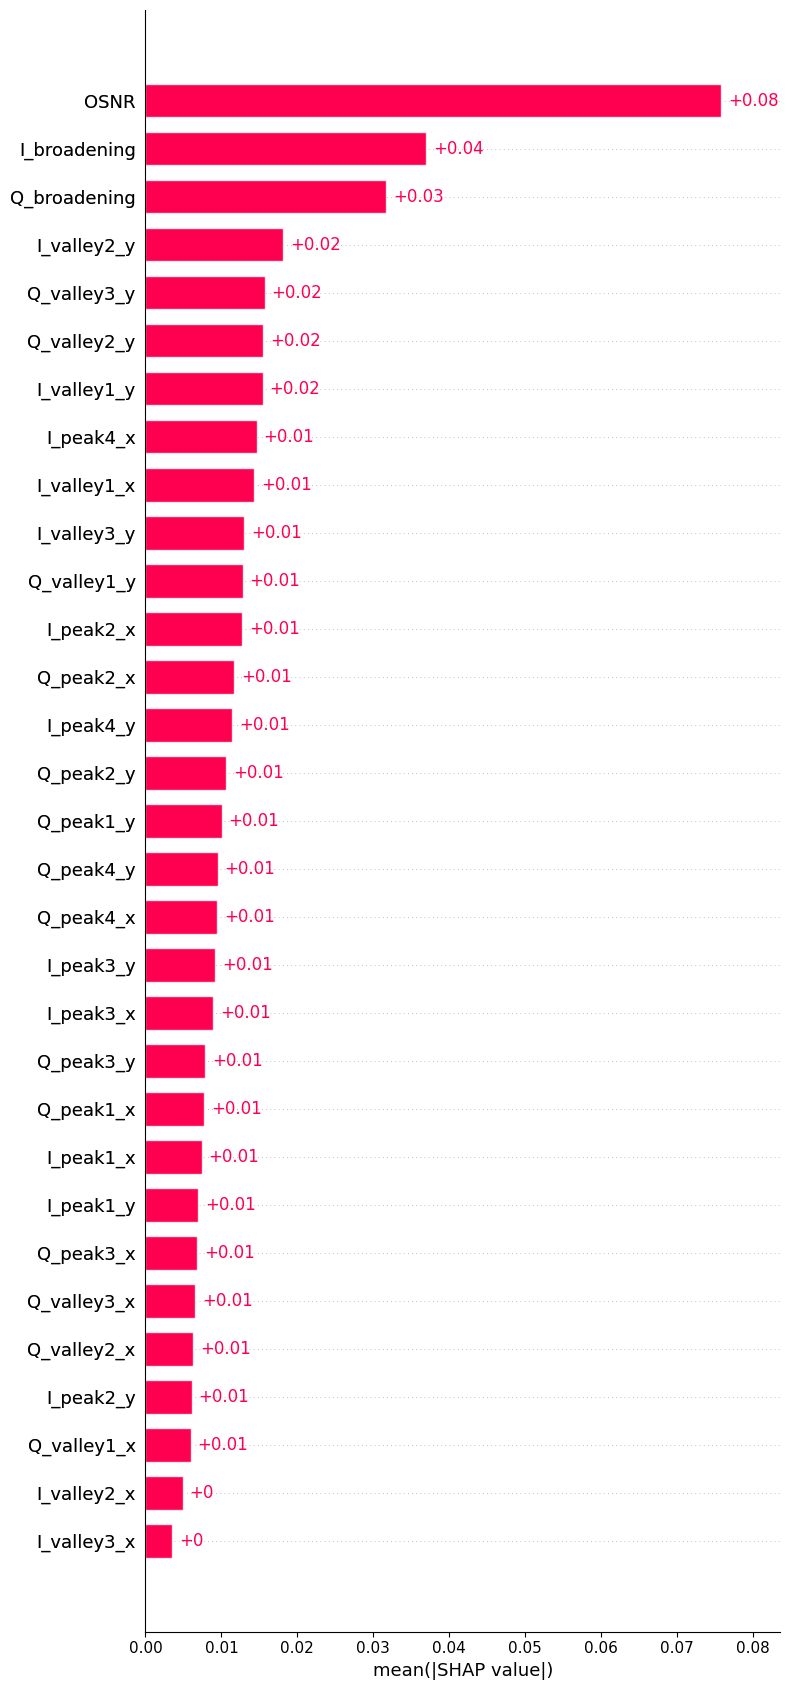

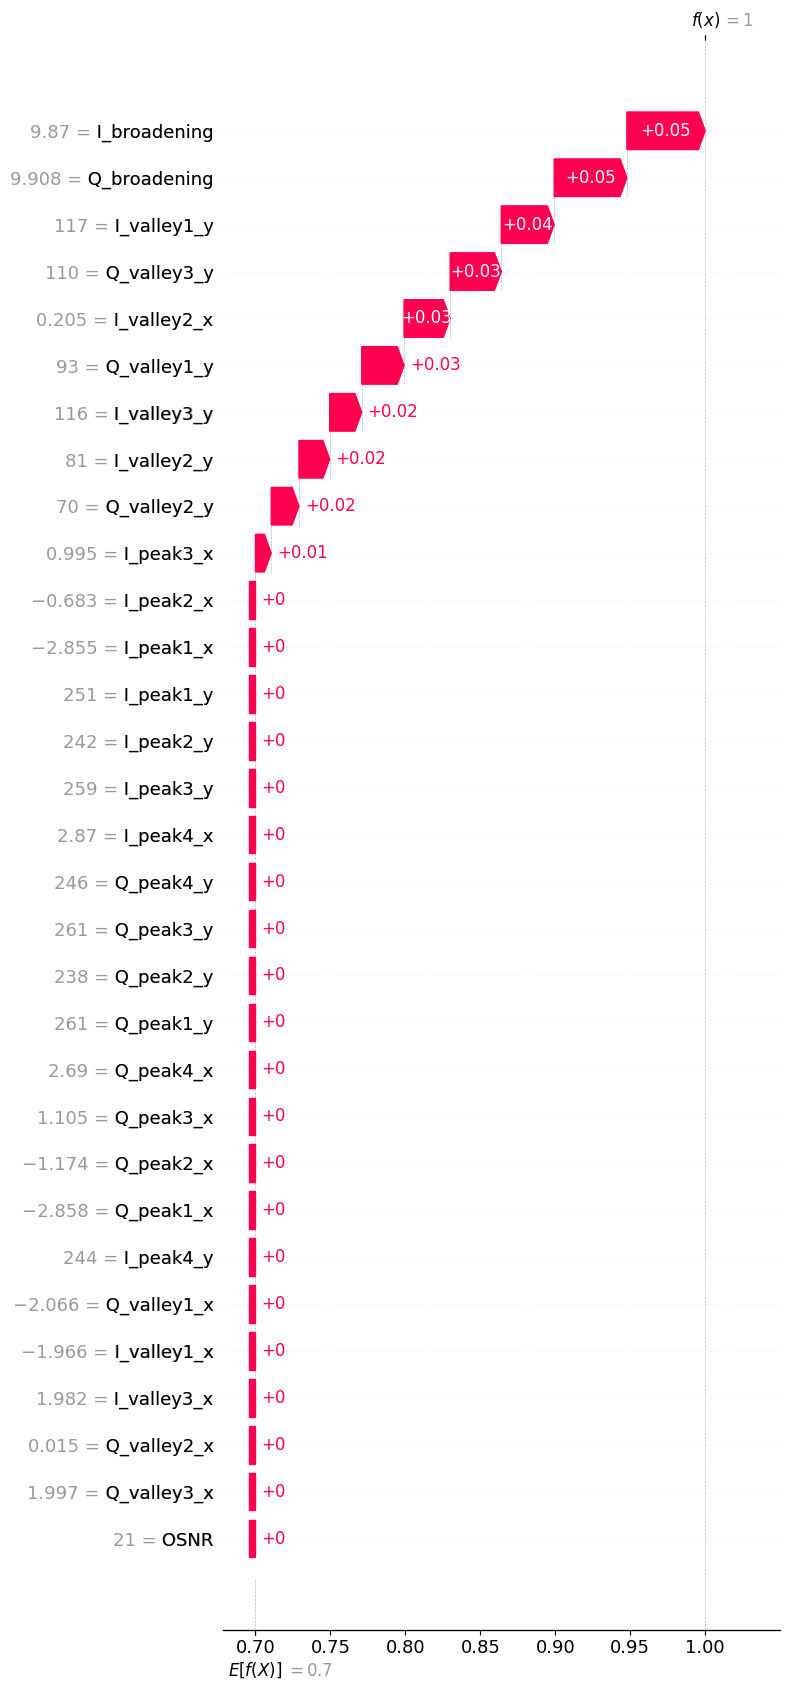


RESUMEN FINAL - KNN SPACING 32 GBd
MONITOREO ASISTIDO - NESTED CV 5x5

--- OUTER CV: PROMEDIO ± STD ---
accuracy              : 0.7358 ± 0.0155
balanced_accuracy     : 0.6611 ± 0.0151
f1_macro              : 0.6702 ± 0.0168
precision_alarm       : 0.7750 ± 0.0078
recall_alarm          : 0.8644 ± 0.0169
f1_alarm              : 0.8173 ± 0.0117
precision_normal      : 0.6107 ± 0.0355
recall_normal         : 0.4578 ± 0.0154
f1_normal             : 0.5232 ± 0.0222
specificity           : 0.4578 ± 0.0154

--- MÉTRICAS GLOBALES OOF ---
accuracy              : 0.7358
balanced_accuracy     : 0.6611
f1_macro              : 0.6701
precision_alarm       : 0.7751
recall_alarm          : 0.8644
f1_alarm              : 0.8173
precision_normal      : 0.6097
recall_normal         : 0.4578
f1_normal             : 0.5229
specificity           : 0.4578

--- TIEMPO DE INFERENCIA ---
Inference: 11.403 ± 0.642 µs/muestra

--- MODELO FINAL ---
{'knn__metric': 'euclidean', 'knn__n_neighbors': 15, 'knn__p': 1,

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

# 32 GBd con roll-off = 0.1
# BW = Rs * (1 + alpha) = 32 * 1.1 = 35.2 GHz
THRESHOLD_GHZ = 35.2

SEED = 42

# Nested Cross-Validation
N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

# Tiempo de inferencia
N_REPETITIONS = 100

# SHAP
SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 500

# Prefijo para archivos de resultados
OUTPUT_PREFIX = "knn_spacing_32GBd_asistido_nested"

# ============================================================
# 2. NOMBRES DE LAS CARACTERÍSTICAS
# ============================================================

# 30 características de histogramas I/Q
# + OSNR como información auxiliar.
#
# Total = 31 características.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening", "OSNR"]
)

assert len(feature_names) == 31

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura esperada:
#
# Columnas 0-29: características I/Q
# Columna 30:    channel_spacing
# Columna 31:    OSNR

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas y se encontraron "
        f"{matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 4. DEFINIR X E y
# ============================================================

# Target físico: channel spacing
y_spacing = matriz.iloc[:, 30].to_numpy()

# MONITOREO ASISTIDO:
#
# X contiene:
#   - 30 características I/Q
#   - OSNR
#
# NO contiene channel_spacing.

X = pd.concat(
    [
        matriz.iloc[:, :30],
        matriz.iloc[:, 31]
    ],
    axis=1
).copy()

X.columns = feature_names

# Clases:
#
# 0 = NORMAL: spacing > 35.2 GHz
# 1 = ALARMA: spacing <= 35.2 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

if X.shape[1] != 31:
    raise ValueError(
        "X debe contener exactamente 31 características."
    )

class_counts = np.bincount(y, minlength=2)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras de ambas clases "
        "para Outer CV."
    )

# Verificar que cada outer train tenga suficientes
# muestras para ejecutar Inner CV.
min_outer_train_class = min(
    count - int(np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para Inner CV."
    )

print("\n" + "=" * 70)
print("KNN - SPACING 32 GBd - MONITOREO ASISTIDO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print("Características: 30 I/Q + OSNR")
print("Criterio de optimización: F1-MACRO")

# ============================================================
# 5. PIPELINE KNN
# ============================================================

def build_knn():
    """
    Crea un pipeline nuevo:

        StandardScaler -> KNeighborsClassifier

    StandardScaler se ajusta únicamente sobre
    los datos de entrenamiento de cada fold.

    Esto evita que las estadísticas del outer test
    participen en el entrenamiento.
    """

    return Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

# ============================================================
# 6. GRID DE HIPERPARÁMETROS
# ============================================================

# Se conserva el grid original:
#
# n_neighbors: 7 valores
# weights:     2 valores
# metric:      3 valores
# p:           2 valores
#
# 7 * 2 * 3 * 2 = 84 combinaciones.
#
# NOTA:
# En sklearn, p no afecta las distancias cuando
# metric="euclidean" o metric="manhattan".
# Por tanto, este grid contiene configuraciones
# matemáticamente redundantes.
#
# Lo mantenemos para respetar el código original.

param_grid = {
    "knn__n_neighbors": [
        3, 5, 7, 9, 11, 15, 21
    ],
    "knn__weights": [
        "uniform",
        "distance"
    ],
    "knn__metric": [
        "euclidean",
        "manhattan",
        "minkowski"
    ],
    "knn__p": [
        1, 2
    ]
}

n_combinations = len(list(ParameterGrid(param_grid)))

# KNN necesita al menos k muestras de entrenamiento
# dentro de cada inner fold.
#
# Verificamos que el mayor k sea válido.

max_k = max(param_grid["knn__n_neighbors"])

min_inner_train_size = (
    (n_samples - int(np.ceil(n_samples / N_OUTER_FOLDS)))
    -
    int(np.ceil(
        (n_samples - int(np.ceil(n_samples / N_OUTER_FOLDS)))
        / N_INNER_FOLDS
    ))
)

if max_k > min_inner_train_size:
    raise ValueError(
        f"El grid incluye k={max_k}, pero el tamaño "
        f"mínimo estimado del inner train es "
        f"{min_inner_train_size}."
    )

print("\nGRID SEARCH:")
print(f"Combinaciones: {n_combinations}")
print("Scoring: f1_macro")
print(f"Outer folds: {N_OUTER_FOLDS}")
print(f"Inner folds: {N_INNER_FOLDS}")

# ============================================================
# 7. FUNCIÓN PARA CALCULAR MÉTRICAS
# ============================================================

def calculate_metrics(y_true, y_pred):
    """
    Calcula métricas globales y por clase.

    Clase 0 = NORMAL
    Clase 1 = ALARMA

    Specificity = TN / (TN + FP)
                = Recall de NORMAL
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "precision_alarm": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall_alarm": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1_alarm": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "precision_normal": precision_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "recall_normal": recall_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "f1_normal": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }

    return metrics

# ============================================================
# 8. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Predicciones OOF:
# cada muestra será predicha una sola vez,
# cuando pertenezca al outer test.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# KNN proporciona probabilidades directamente.
oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

# Fold al que pertenece cada predicción.
oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

nested_start = time.perf_counter()

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE PRINCIPAL: OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 SEPARAR OUTER TRAIN / OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {X_outer_train.shape}")
    print(f"Outer Test:  {X_outer_test.shape}")

    # --------------------------------------------------------
    # 9.2 INNER CROSS-VALIDATION
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH DENTRO DEL OUTER TRAIN
    # --------------------------------------------------------

    # IMPORTANTE:
    #
    # GridSearchCV solo recibe X_outer_train.
    # No ve X_outer_test.
    #
    # Por tanto, la selección de hiperparámetros
    # ocurre dentro del outer fold.

    search = GridSearchCV(
        estimator=build_knn(),
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    # GridSearchCV reentrena el mejor modelo
    # con todo el outer train.
    best_knn = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1-Macro Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1_macro": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.4 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # Estas muestras nunca fueron usadas para
    # seleccionar los hiperparámetros ni entrenar
    # el modelo correspondiente a este fold.

    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar en la posición original del dataset.
    oof_predictions[test_idx] = y_outer_pred
    oof_probabilities[test_idx] = y_outer_proba
    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.5 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    fold_metrics = calculate_metrics(
        y_outer_test,
        y_outer_pred
    )

    # --------------------------------------------------------
    # 9.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        # Tiempo promedio por muestra del batch.
        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        **fold_metrics,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    for metric, value in fold_metrics.items():
        if metric not in ["tn", "fp", "fn", "tp"]:
            print(f"{metric:22s}: {value:.4f}")

    print(
        f"\nInference: {inference_mean_us:.3f} "
        f"± {inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. TIEMPO TOTAL NESTED CV
# ============================================================

nested_time = (
    time.perf_counter() - nested_start
)

print("\n" + "=" * 70)
print("NESTED CROSS-VALIDATION COMPLETADA")
print("=" * 70)

print(
    f"Tiempo total: {nested_time:.2f} s "
    f"({nested_time / 60:.2f} min)"
)

# ============================================================
# 11. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print("\nPredicciones OOF completadas correctamente.")

# ============================================================
# 12. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 13. PROMEDIO Y DESVIACIÓN ESTÁNDAR OUTER CV
# ============================================================

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "precision_normal",
    "recall_normal",
    "f1_normal",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:22s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 14. BOXPLOT OUTER CV
# ============================================================

plot_metrics = [
    "accuracy",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "f1_macro",
    "balanced_accuracy",
    "specificity"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [results_df[m].values for m in plot_metrics],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Alarm",
        "F1 Macro",
        "Balanced Acc.",
        "Specificity"
    ]
)

plt.ylabel("Score")

plt.title(
    "KNN Spacing 32 GBd - Asistido\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MÉTRICAS GLOBALES OOF
# ============================================================

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:
        print(f"{metric:22s}: {value:.4f}")

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Spacing 32 GBd - Asistido\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "KNN Spacing 32 GBd - Asistido\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 18. GUARDAR PREDICCIONES OOF
# ============================================================

# Cada fila corresponde a una muestra original.
#
# Se guardan:
#   - Fold externo
#   - Spacing real
#   - OSNR
#   - Clase verdadera
#   - Clase predicha
#   - Probabilidad de ALARMA
#   - Indicador de acierto

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": matriz.iloc[:, 31].to_numpy(),
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 19. GUARDAR HIPERPARÁMETROS POR FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")
print(params_df.to_string(index=False))

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 20. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean = (
    all_inference_times.mean()
)

inference_std = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std:.3f} µs/muestra"
)

print(
    f"Mediciones totales: "
    f"{len(all_inference_times)}"
)

print(
    "Incluye StandardScaler y KNN.predict()."
)

print(
    "No incluye GridSearchCV ni entrenamiento."
)

# ============================================================
# 21. GRID SEARCH FINAL SOBRE TODO EL DATASET
# ============================================================

# Este GridSearchCV se utiliza exclusivamente
# para seleccionar el modelo final de SHAP.
#
# No modifica las predicciones OOF.
#
# No debe utilizarse su best_score_ como
# resultado principal de generalización.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - TODO EL DATASET")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_knn(),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

# El modelo ya fue reajustado sobre todo X
# automáticamente por refit=True.
final_knn = final_search.best_estimator_

print("\nMejores hiperparámetros finales:")
print(final_best_params)

print(
    f"Mejor F1-Macro CV final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

# ============================================================
# 22. SHAP - KERNELEXPLAINER
# ============================================================

# Explicamos la probabilidad:
#
#     P(ALARMA | X)
#
# SHAP positivo:
#     aumenta P(ALARMA).
#
# SHAP negativo:
#     disminuye P(ALARMA).
#
# Las explicaciones corresponden al modelo
# entrenado con todo el dataset.
#
# No son explicaciones OOF.

print("\n" + "=" * 70)
print("SHAP - KNN ASISTIDO 32 GBd")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

print(
    f"nsamples: {SHAP_NSAMPLES}"
)

# ------------------------------------------------------------
# 22.1 FUNCIÓN DE PROBABILIDAD
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe 31 características y devuelve
    la probabilidad de clase ALARMA = 1.
    """

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(data)[:, 1]

# ------------------------------------------------------------
# 22.2 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw_shap = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = (
    time.perf_counter() - shap_start
)

shap_values = np.asarray(raw_shap)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: {shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

base_alarm = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 23. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:
    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )
else:
    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 31 CARACTERÍSTICAS")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 SHAP:")
print(imp_df.head(5).to_string(index=False))

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 24. CREAR SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 25. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 26. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=31,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - KNN SPACING 32 GBd")
print("MONITOREO ASISTIDO - NESTED CV 5x5")
print("=" * 70)

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:22s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:
        print(f"{metric:22s}: {value:.4f}")

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean:.3f} "
    f"± {inference_std:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print(final_best_params)

print(
    f"F1-Macro GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

print("\n--- SHAP ---")

print(f"Tiempo SHAP: {shap_time:.2f} s")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


# PARA MONITOREO CIEGO (SIN LA OSNR)

## RDF 16GBd para clasificar SEPARACIÓN ESPECTRAL SIN OSNR


RANDOM FOREST - SPACING 16 GBd - MONITOREO CIEGO
Dataset: matriz16GBd_clas.csv
Forma matriz: (243, 32)
Forma X: (243, 30)
Total muestras: 243
NORMAL (> 17.6 GHz): 63
ALARMA (<= 17.6 GHz): 180
Número de características: 30
OSNR utilizada: False
Criterio GridSearchCV: F1 ALARMA

GRID SEARCH:
Combinaciones: 162
Scoring: f1
Outer folds: 5
Inner folds: 5

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: (194, 30)
Outer Test:  (49, 30)
Fitting 5 folds for each of 162 candidates, totalling 810 fits

Mejores parámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Mejor F1 Inner CV: 0.8777
Tiempo GridSearchCV: 5.12 s (0.09 min)

MÉTRICAS OUTER FOLD:
accuracy              : 0.7347
precision             : 0.7556
recall                : 0.9444
f1                    : 0.8395
specificity           : 0.1538
balanced_accuracy     : 0.5491
f1_macro              : 0.5374
precision_normal      : 0.5000
recall_normal   

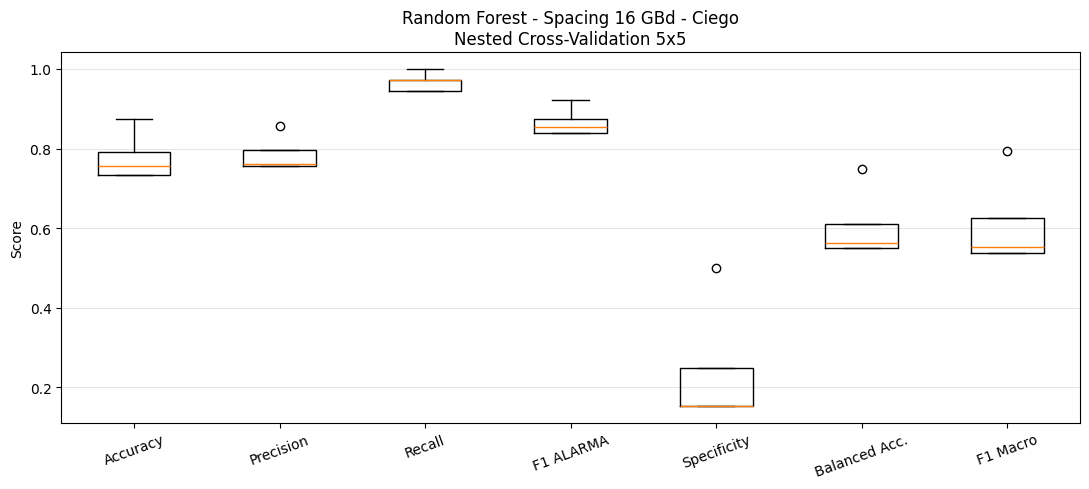


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy              : 0.7778
precision             : 0.7838
recall                : 0.9667
f1                    : 0.8657
specificity           : 0.2381
balanced_accuracy     : 0.6024
f1_macro              : 0.6114
precision_normal      : 0.7143
recall_normal         : 0.2381
f1_normal             : 0.3571

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.71      0.24      0.36        63
      ALARMA       0.78      0.97      0.87       180

    accuracy                           0.78       243
   macro avg       0.75      0.60      0.61       243
weighted avg       0.77      0.78      0.73       243


Matriz de confusión OOF:
[[ 15  48]
 [  6 174]]


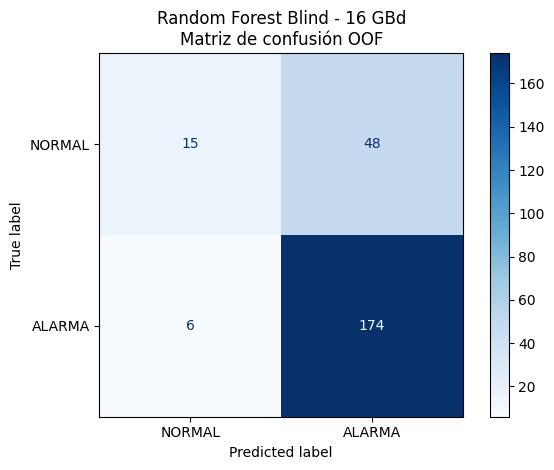

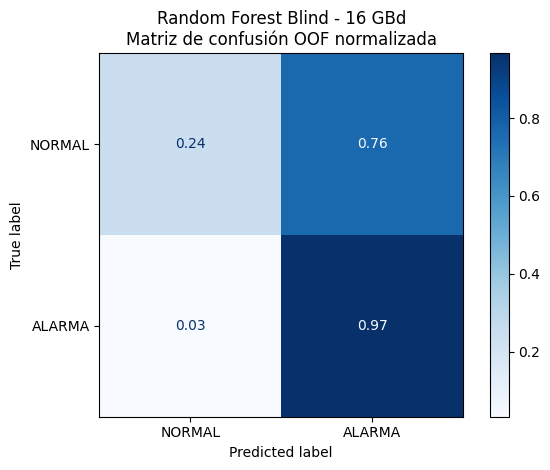


HIPERPARÁMETROS POR OUTER FOLD:
 fold max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1  grid_time_s
    1      None         sqrt                 2                  5           100          0.877662     5.117595
    2      None         sqrt                 1                  2           100          0.879655     4.247516
    3      None         sqrt                 1                  2           100          0.886001     4.193112
    4      None         sqrt                 1                  2           100          0.876945     4.209599
    5      None         log2                 1                  2           200          0.854338     4.379412

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 327.997 µs/muestra
Inference Std: 154.019 µs/muestra
Mediciones: 500
Incluye RandomForest.predict().
No incluye extracción de características, entrenamiento, Grid Search ni SHAP.

GRID SEARCH FINAL - RANDOM FOREST BLIND
Fitting 5 folds for each of 162 

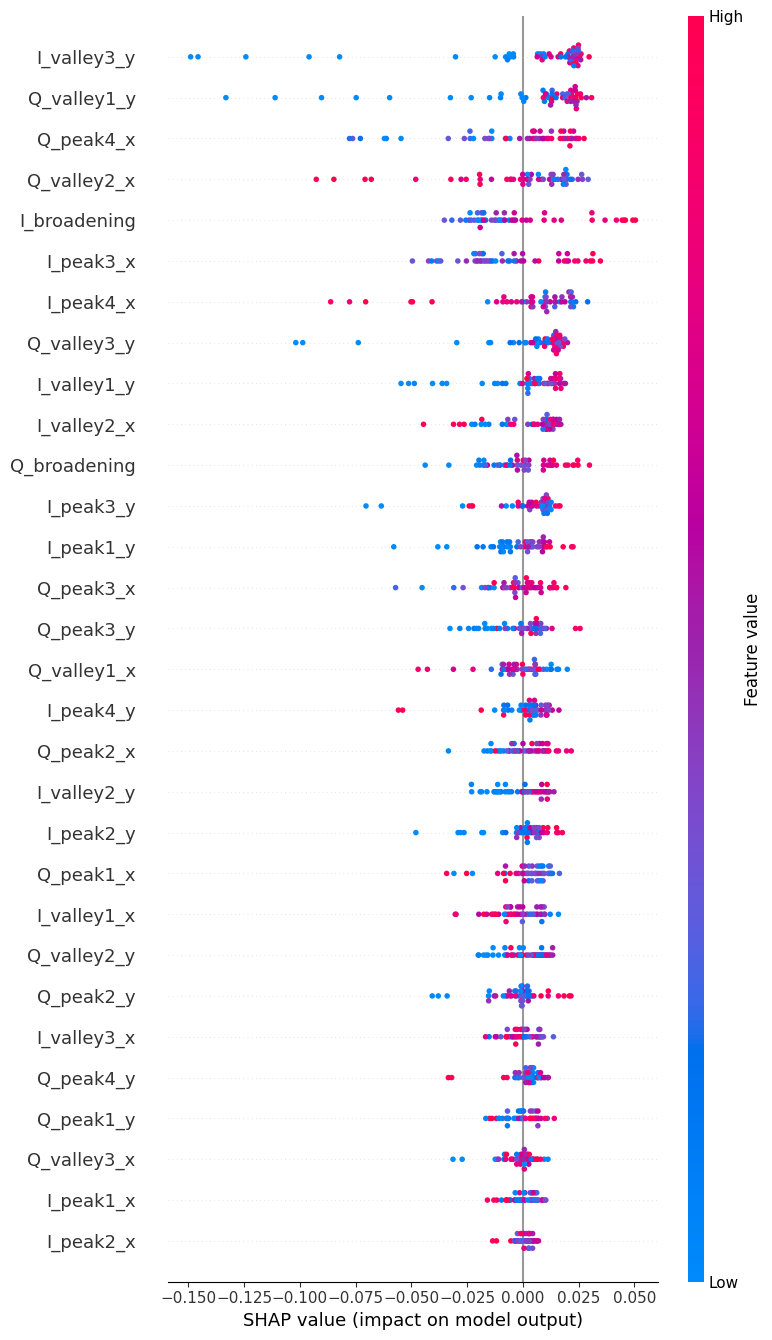

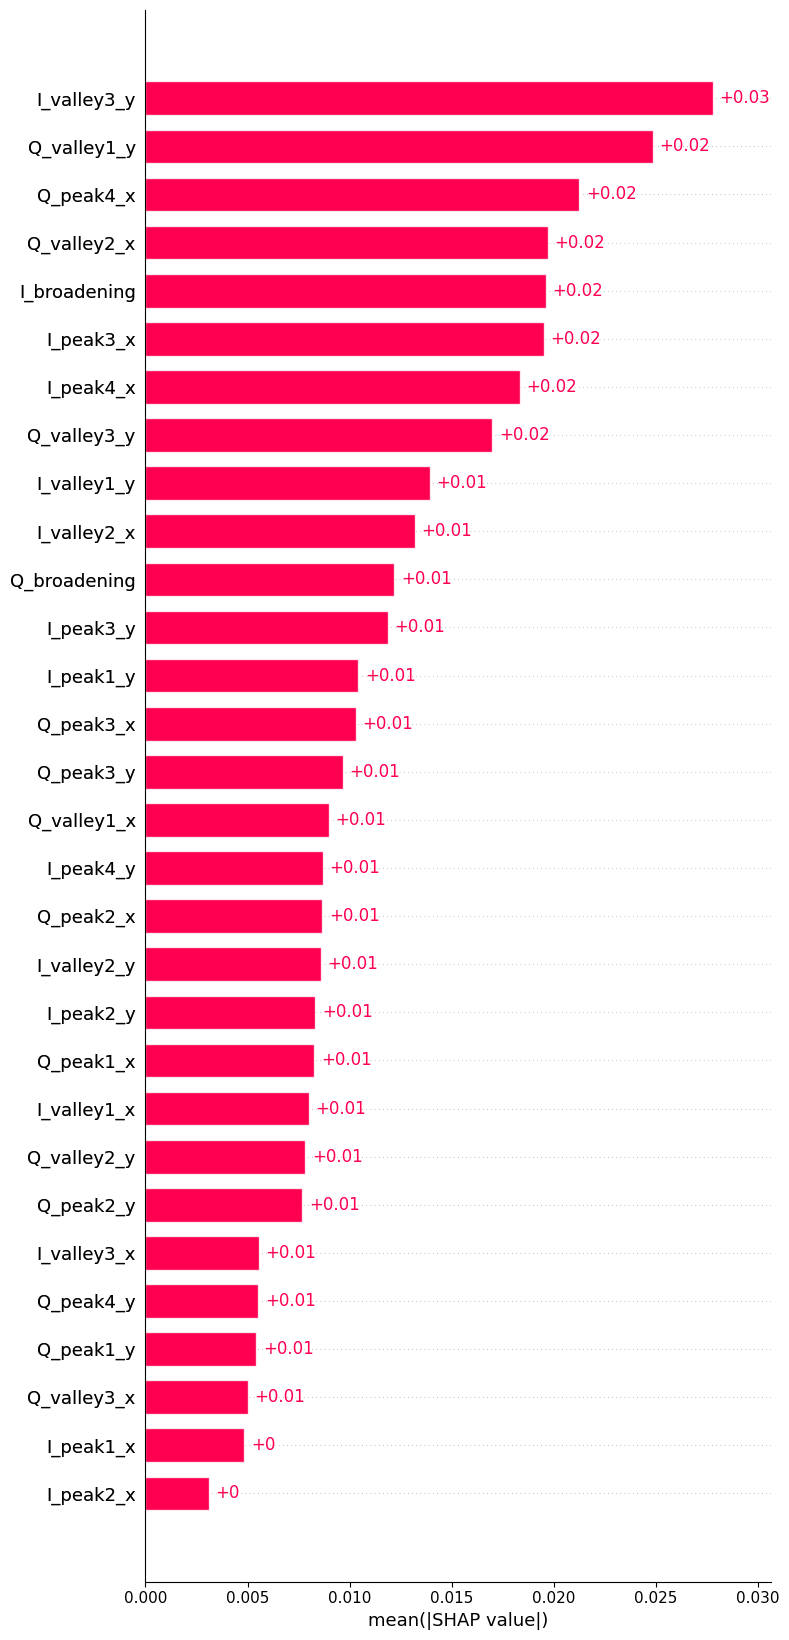

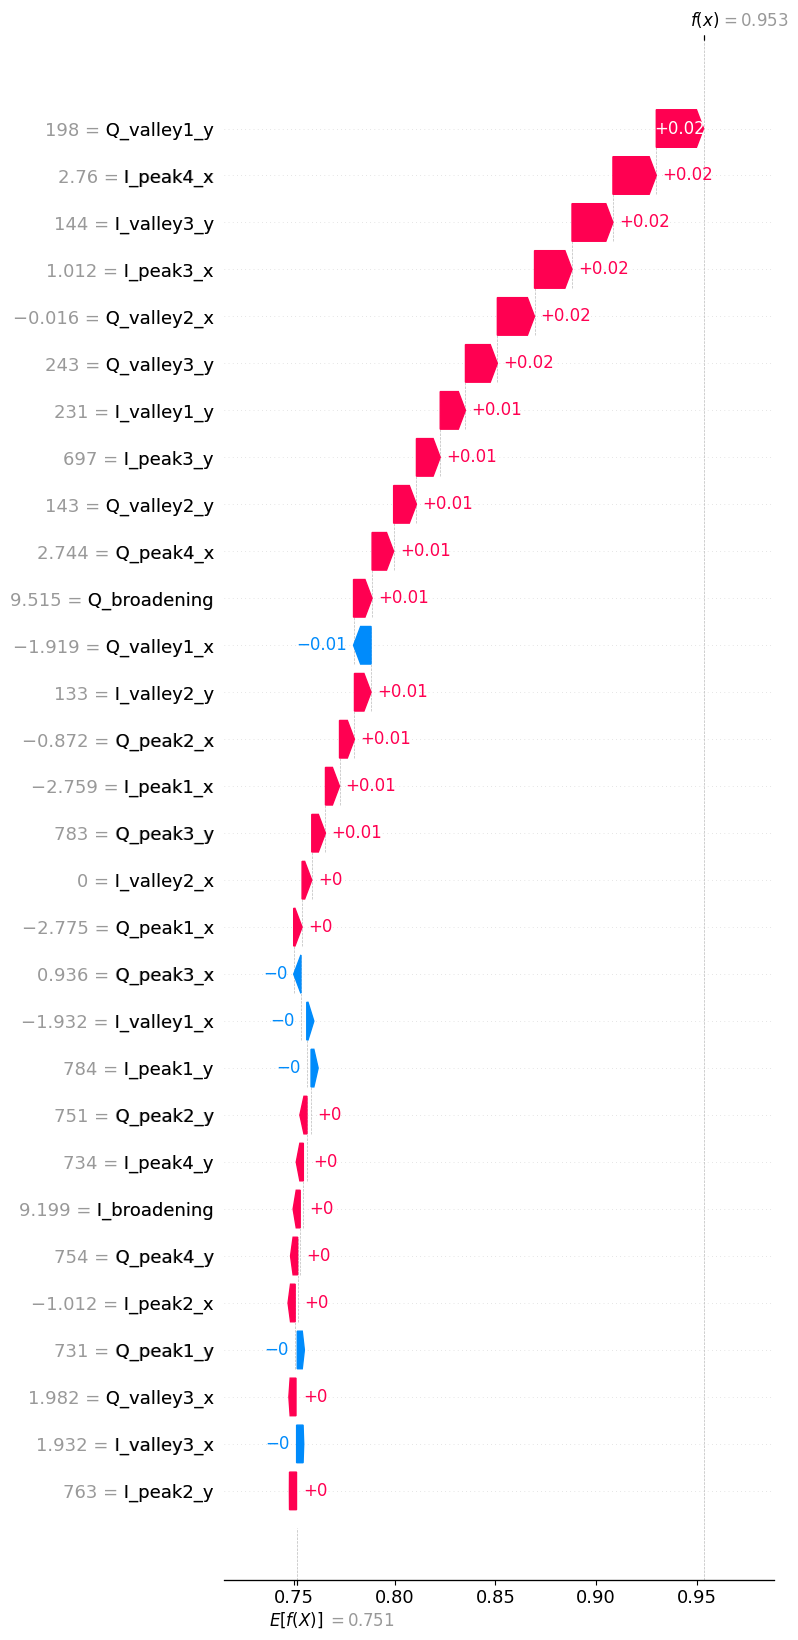


RESUMEN FINAL - RANDOM FOREST BLIND - 16 GBd
NESTED CROSS-VALIDATION 5x5

CARACTERÍSTICAS:
30 I/Q
OSNR excluida
channel_spacing excluido de X

CRITERIO DE GRID SEARCH:
F1 de ALARMA

--- OUTER CV: PROMEDIO ± STD ---
accuracy              : 0.7782 ± 0.0527
precision             : 0.7849 ± 0.0391
recall                : 0.9667 ± 0.0208
f1                    : 0.8661 ± 0.0313
specificity           : 0.2423 ± 0.1341
balanced_accuracy     : 0.6045 ± 0.0762
f1_macro              : 0.6093 ± 0.0983
precision_normal      : 0.6833 ± 0.1856
recall_normal         : 0.2423 ± 0.1341
f1_normal             : 0.3525 ± 0.1656

--- MÉTRICAS GLOBALES OOF ---
accuracy              : 0.7778
precision             : 0.7838
recall                : 0.9667
f1                    : 0.8657
specificity           : 0.2381
balanced_accuracy     : 0.6024
f1_macro              : 0.6114
precision_normal      : 0.7143
recall_normal         : 0.2381
f1_normal             : 0.3571

--- TIEMPO DE INFERENCIA ---
Inference: 32

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

# 16 GBd, roll-off = 0.1:
# BW = 16 * (1 + 0.1) = 17.6 GHz
THRESHOLD_GHZ = 17.6

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

OUTPUT_PREFIX = "rf_spacing_16GBd_blind_nested"

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
#
# Se utilizan únicamente características I/Q.
#
# NO utilizamos:
#   - OSNR
#   - channel_spacing como predictor
#
# channel_spacing se utiliza exclusivamente
# para construir la etiqueta de clasificación.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura:
#
# Columnas 0-29: 30 características I/Q
# Columna 30:    channel_spacing
# Columna 31:    OSNR
#
# Total: 32 columnas

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas y se encontraron "
        f"{matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 4. DEFINIR ENTRADAS Y TARGET
# ============================================================

# Espaciamiento espectral real.
y_spacing = matriz.iloc[:, 30].to_numpy()

# OSNR real: solo se conserva para registrar
# información de las muestras en el CSV OOF.
# Nunca se introduce al Random Forest.
osnr_values = matriz.iloc[:, 31].to_numpy()

# Solo las primeras 30 columnas.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# Clases:
#
# 0 = NORMAL: spacing > 17.6 GHz
# 1 = ALARMA: spacing <= 17.6 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras de cada clase "
        "para ejecutar Outer CV."
    )

# Comprobar también el tamaño de las clases
# después de reservar el outer test.
min_outer_train_class = min(
    int(count - np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Inner CV."
    )

print("\n" + "=" * 70)
print("RANDOM FOREST - SPACING 16 GBd - MONITOREO CIEGO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print(f"Número de características: {X.shape[1]}")
print(f"OSNR utilizada: {'OSNR' in X.columns}")
print("Criterio GridSearchCV: F1 ALARMA")

# ============================================================
# 5. RANDOM FOREST BASE
# ============================================================

def build_rf():
    """
    Crea una nueva instancia de Random Forest.

    n_jobs=1 durante GridSearchCV evita
    paralelismo anidado innecesario, ya que
    GridSearchCV utiliza n_jobs=-1.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )

# ============================================================
# 6. GRID DE HIPERPARÁMETROS
# ============================================================

# Se conserva exactamente el grid original.
#
# 3 * 3 * 3 * 3 * 2 = 162 configuraciones.

param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = len(
    list(ParameterGrid(param_grid))
)

print("\nGRID SEARCH:")
print(f"Combinaciones: {n_combinations}")
print("Scoring: f1")
print(f"Outer folds: {N_OUTER_FOLDS}")
print(f"Inner folds: {N_INNER_FOLDS}")

# ============================================================
# 7. FUNCIÓN DE MÉTRICAS
# ============================================================

def calculate_metrics(y_true, y_pred):
    """
    Calcula métricas de clasificación.

    NORMAL = 0
    ALARMA = 1

    F1, Precision y Recall sin sufijo
    se calculan para ALARMA.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "precision_normal": precision_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "recall_normal": recall_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "f1_normal": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

# ============================================================
# 8. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra tendrá una predicción realizada
# por un modelo que no la utilizó para entrenar
# ni seleccionar hiperparámetros.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

nested_start = time.perf_counter()

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 DIVIDIR OUTER TRAIN Y OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {X_outer_train.shape}")
    print(f"Outer Test:  {X_outer_test.shape}")

    # --------------------------------------------------------
    # 9.2 INNER CROSS-VALIDATION
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH DENTRO DEL OUTER TRAIN
    # --------------------------------------------------------

    # El outer test NO participa en GridSearchCV.
    #
    # GridSearchCV:
    #   1. Prueba 162 configuraciones.
    #   2. Evalúa cada una con 5 inner folds.
    #   3. Selecciona la mejor según F1 ALARMA.
    #   4. Reentrena sobre todo el outer train.

    search = GridSearchCV(
        estimator=build_rf(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    best_rf = search.best_estimator_

    # Mantener la configuración original:
    # todos los núcleos disponibles para predecir.
    best_rf.set_params(n_jobs=-1)

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s "
        f"({grid_time / 60:.2f} min)"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.4 PREDICCIONES OUTER TEST
    # --------------------------------------------------------

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar predicciones en la posición
    # original de cada muestra.

    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.5 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    fold_metrics = calculate_metrics(
        y_outer_test,
        y_outer_pred
    )

    # --------------------------------------------------------
    # 9.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up.
    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        # Tiempo por muestra dentro del batch.
        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        **fold_metrics,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    for metric, value in fold_metrics.items():

        if metric not in ["tn", "fp", "fn", "tp"]:
            print(
                f"{metric:22s}: {value:.4f}"
            )

    print("\nMatriz de confusión del fold:")

    print(
        confusion_matrix(
            y_outer_test,
            y_outer_pred,
            labels=[0, 1]
        )
    )

    print(
        f"\nInference: {inference_mean_us:.3f} "
        f"± {inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. TIEMPO TOTAL NESTED CV
# ============================================================

nested_time = (
    time.perf_counter() - nested_start
)

print("\n" + "=" * 70)
print("NESTED CROSS-VALIDATION COMPLETADA")
print("=" * 70)

print(
    f"Tiempo total: {nested_time:.2f} s "
    f"({nested_time / 60:.2f} min)"
)

# ============================================================
# 11. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print(
    "\nTodas las muestras tienen "
    "una predicción OOF válida."
)

# ============================================================
# 12. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 13. PROMEDIO ± STD DE LOS OUTER FOLDS
# ============================================================

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "balanced_accuracy",
    "f1_macro",
    "precision_normal",
    "recall_normal",
    "f1_normal"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:22s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 14. BOXPLOT DE LOS OUTER FOLDS
# ============================================================

plot_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "balanced_accuracy",
    "f1_macro"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in plot_metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 ALARMA",
        "Specificity",
        "Balanced Acc.",
        "F1 Macro"
    ]
)

plt.ylabel("Score")

plt.title(
    "Random Forest - Spacing 16 GBd - Ciego\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MÉTRICAS GLOBALES OOF
# ============================================================

# Se comparan todas las etiquetas reales
# contra las predicciones outer-fold reunidas.
#
# Cada muestra fue predicha exactamente una vez.

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:
        print(
            f"{metric:22s}: {value:.4f}"
        )

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Blind - 16 GBd\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "Random Forest Blind - 16 GBd\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 18. GUARDAR PREDICCIONES OOF
# ============================================================

# El CSV conserva el índice original.
#
# channel_spacing y OSNR se guardan
# solamente para análisis posterior.
#
# NO fueron entradas del modelo.

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": osnr_values,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 19. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 20. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# Se reúnen las 100 mediciones de cada fold.
#
# Total:
# 5 folds * 100 repeticiones = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean_us = (
    all_inference_times.mean()
)

inference_std_us = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean_us:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std_us:.3f} µs/muestra"
)

print(
    f"Mediciones: {len(all_inference_times)}"
)

print(
    "Incluye RandomForest.predict()."
)

print(
    "No incluye extracción de características, "
    "entrenamiento, Grid Search ni SHAP."
)

# ============================================================
# 21. GRID SEARCH FINAL SOBRE TODO EL DATASET
# ============================================================

# Este GridSearchCV se utiliza para obtener
# el modelo final que será explicado con SHAP.
#
# IMPORTANTE:
#
# No modifica las predicciones OOF.
#
# El best_score_ del modelo final NO sustituye
# las métricas de generalización obtenidas
# mediante Nested CV.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - RANDOM FOREST BLIND")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_rf(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

# Modelo reajustado automáticamente sobre todo X.
final_rf = final_search.best_estimator_

# Se conserva el comportamiento del original:
# n_jobs=-1 para predicción e interpretación.
final_rf.set_params(n_jobs=-1)

print("\nMejores parámetros finales:")
print(final_best_params)

print(
    f"Mejor F1 Inner CV final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s "
    f"({final_grid_time / 60:.2f} min)"
)

# ============================================================
# 22. SHAP - TREEEXPLAINER
# ============================================================

# SHAP explicará:
#
#     P(ALARMA | 30 características I/Q)
#
# SHAP positivo:
#   aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#   disminuye la probabilidad de ALARMA.
#
# Se explica el modelo final entrenado
# sobre todo el dataset.
#
# Por tanto, SHAP no es OOF.

print("\n" + "=" * 70)
print("SHAP - RANDOM FOREST - MONITOREO CIEGO")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

shap_start = time.perf_counter()

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# ============================================================
# 23. EXTRAER SHAP DE LA CLASE ALARMA
# ============================================================

# Compatibilidad con versiones de SHAP:
#
# Caso A:
#   [SHAP_NORMAL, SHAP_ALARMA]
#
# Caso B:
#   array (n_muestras, n_features, 2)

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if arr.ndim == 3 and arr.shape[2] == 2:

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

shap_time = (
    time.perf_counter() - shap_start
)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: {shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

# Expected value de la clase ALARMA.
base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 24. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 30 CARACTERÍSTICAS I/Q")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 CARACTERÍSTICAS:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 25. CREAR SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 26. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 29. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - RANDOM FOREST BLIND - 16 GBd")
print("NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

print("\nCARACTERÍSTICAS:")
print("30 I/Q")
print("OSNR excluida")
print("channel_spacing excluido de X")

print("\nCRITERIO DE GRID SEARCH:")
print("F1 de ALARMA")

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:22s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:22s}: {value:.4f}"
        )

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean_us:.3f} "
    f"± {inference_std_us:.3f} µs/muestra"
)

print("\n--- GRID SEARCH FINAL ---")

print(final_best_params)

print(
    f"F1 CV final: {final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

print("\n--- SHAP ---")

print(
    f"Tiempo SHAP: {shap_time:.2f} s"
)

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 16GBd para clasificar SEPARACIÓN ESPECTRAL SIN OSNR


SVM - SPACING 16 GBd - MONITOREO CIEGO
Dataset: matriz16GBd_clas.csv
Forma matriz: (243, 32)
Forma X: (243, 30)
Total muestras: 243
NORMAL (> 17.6 GHz): 63
ALARMA (<= 17.6 GHz): 180
Número de características: 30
OSNR utilizada: False

GRID SEARCH:
Combinaciones: 20
Kernels: Linear y RBF
Scoring: F1 ALARMA
Outer folds: 5
Inner folds: 5

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: (194, 30)
Outer Test:  (49, 30)
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores parámetros:
{'svm__C': 0.1, 'svm__kernel': 'linear'}
Mejor F1 Inner CV: 0.8632
Tiempo GridSearchCV: 1.17 s

MÉTRICAS OUTER FOLD:
accuracy              : 0.7551
precision             : 0.7609
recall                : 0.9722
f1                    : 0.8537
specificity           : 0.1538
balanced_accuracy     : 0.5630
f1_macro              : 0.5518
precision_normal      : 0.6667
recall_normal         : 0.1538
f1_normal             : 0.2500

Matriz de confusión del fold:
[[ 2 11]
 [ 1 35]]

I

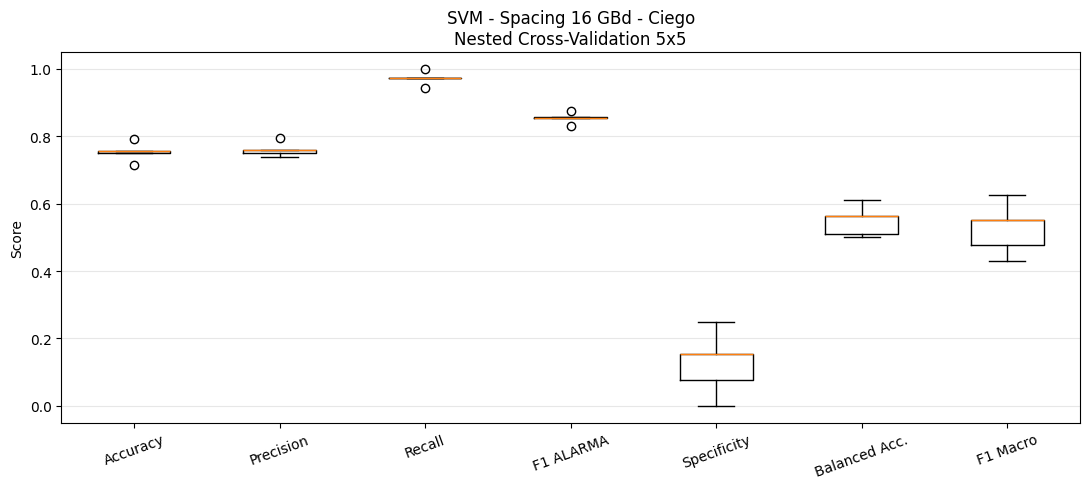


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy              : 0.7531
precision             : 0.7609
recall                : 0.9722
f1                    : 0.8537
specificity           : 0.1270
balanced_accuracy     : 0.5496
f1_macro              : 0.5321
precision_normal      : 0.6154
recall_normal         : 0.1270
f1_normal             : 0.2105

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.62      0.13      0.21        63
      ALARMA       0.76      0.97      0.85       180

    accuracy                           0.75       243
   macro avg       0.69      0.55      0.53       243
weighted avg       0.72      0.75      0.69       243


Matriz de confusión OOF:
[[  8  55]
 [  5 175]]


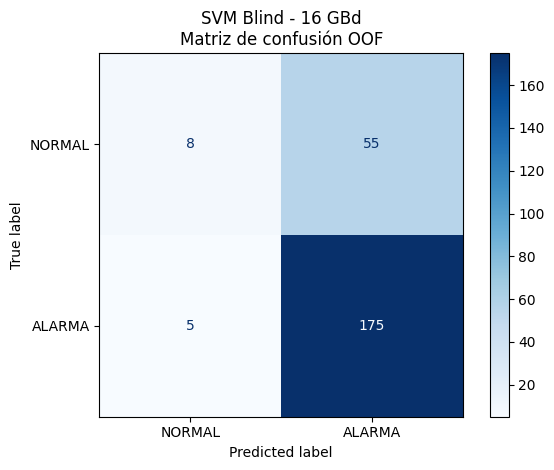

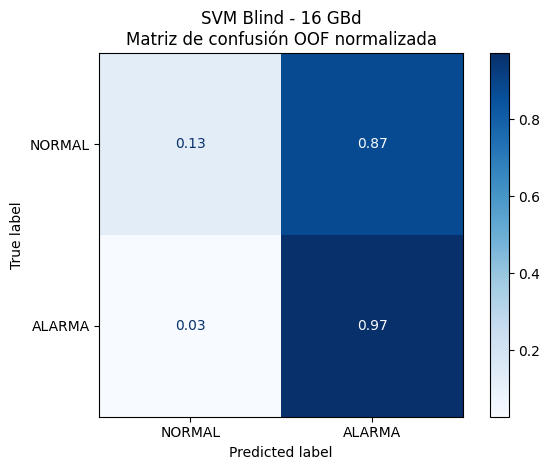


HIPERPARÁMETROS POR OUTER FOLD:
 fold  svm__C svm__kernel  inner_cv_best_f1  grid_time_s svm__gamma
    1     0.1      linear          0.863192     1.166338        NaN
    2     1.0         rbf          0.868479     0.226742      scale
    3     1.0         rbf          0.876261     0.165266      scale
    4    10.0         rbf          0.865520     0.326889        0.1
    5     0.1         rbf          0.849517     0.225463      scale

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 13.583 µs/muestra
Inference Std: 2.104 µs/muestra
Mediciones: 500
Incluye StandardScaler y SVM.predict().
No incluye extracción de características, entrenamiento, Grid Search ni SHAP.

GRID SEARCH FINAL - SVM BLIND
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros finales:
{'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Mejor F1 GridSearch final: 0.8636
Tiempo GridSearch final: 0.46 s

MODELO FINAL:
Kernel: rbf
C: 1
Gamma: scale
Tiempo entrenamiento probabil

  0%|          | 0/50 [00:00<?, ?it/s]


Tiempo SHAP: 9.33 s (0.16 min)

RANKING SHAP - 30 CARACTERÍSTICAS I/Q
     feature mean_abs_shap importance_percent
   I_peak4_y      0.014251              9.19%
 Q_valley1_x      0.012118              7.81%
 Q_valley2_x      0.011688              7.54%
   Q_peak4_y      0.011598              7.48%
   I_peak4_x      0.011572              7.46%
I_broadening      0.009129              5.89%
 I_valley2_x      0.007998              5.16%
   Q_peak1_x      0.007725              4.98%
   Q_peak4_x      0.007419              4.78%
   Q_peak3_x      0.006738              4.34%
   Q_peak3_y      0.004996              3.22%
Q_broadening      0.004914              3.17%
 Q_valley2_y      0.004854              3.13%
   Q_peak2_x      0.004849              3.13%
 Q_valley3_y      0.004315              2.78%
 Q_valley1_y      0.003757              2.42%
   I_peak3_x      0.003608              2.33%
 I_valley3_y      0.003507              2.26%
   I_peak1_y      0.003323              2.14%
 I_valley

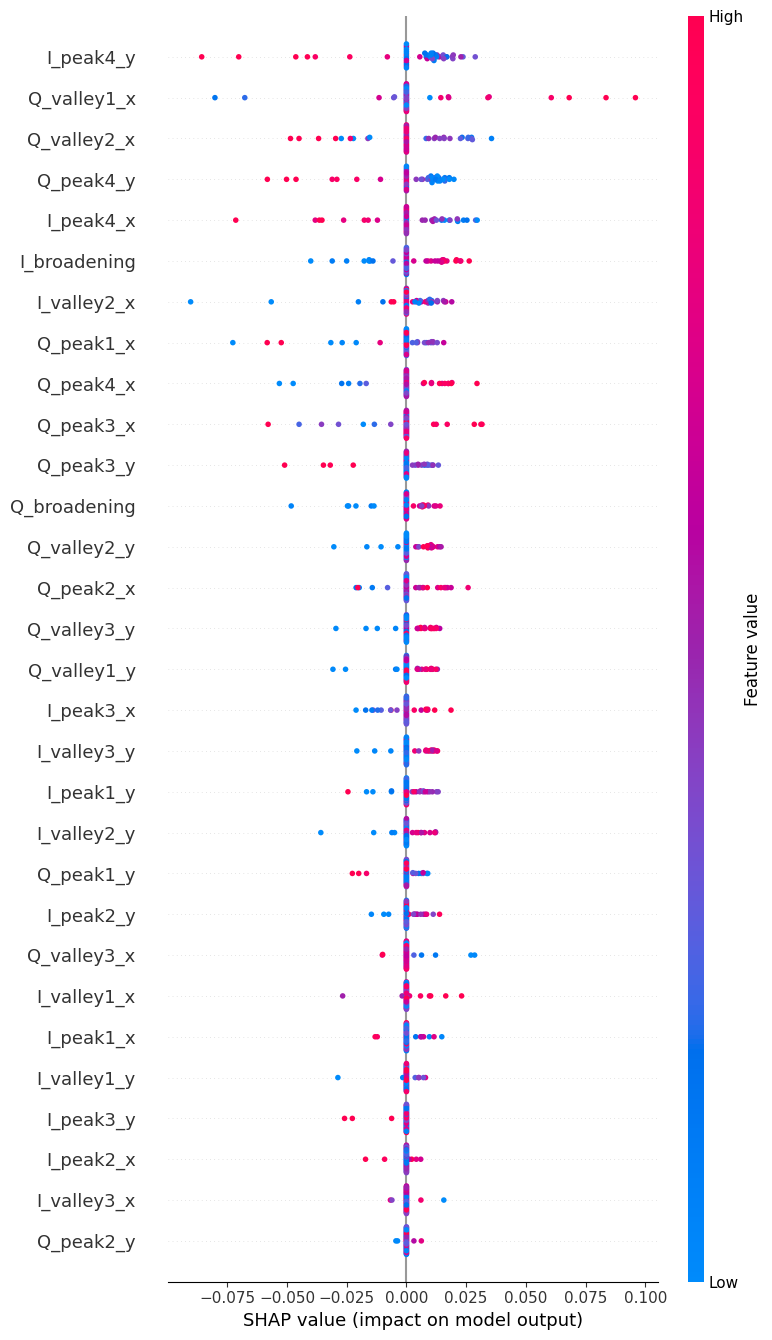

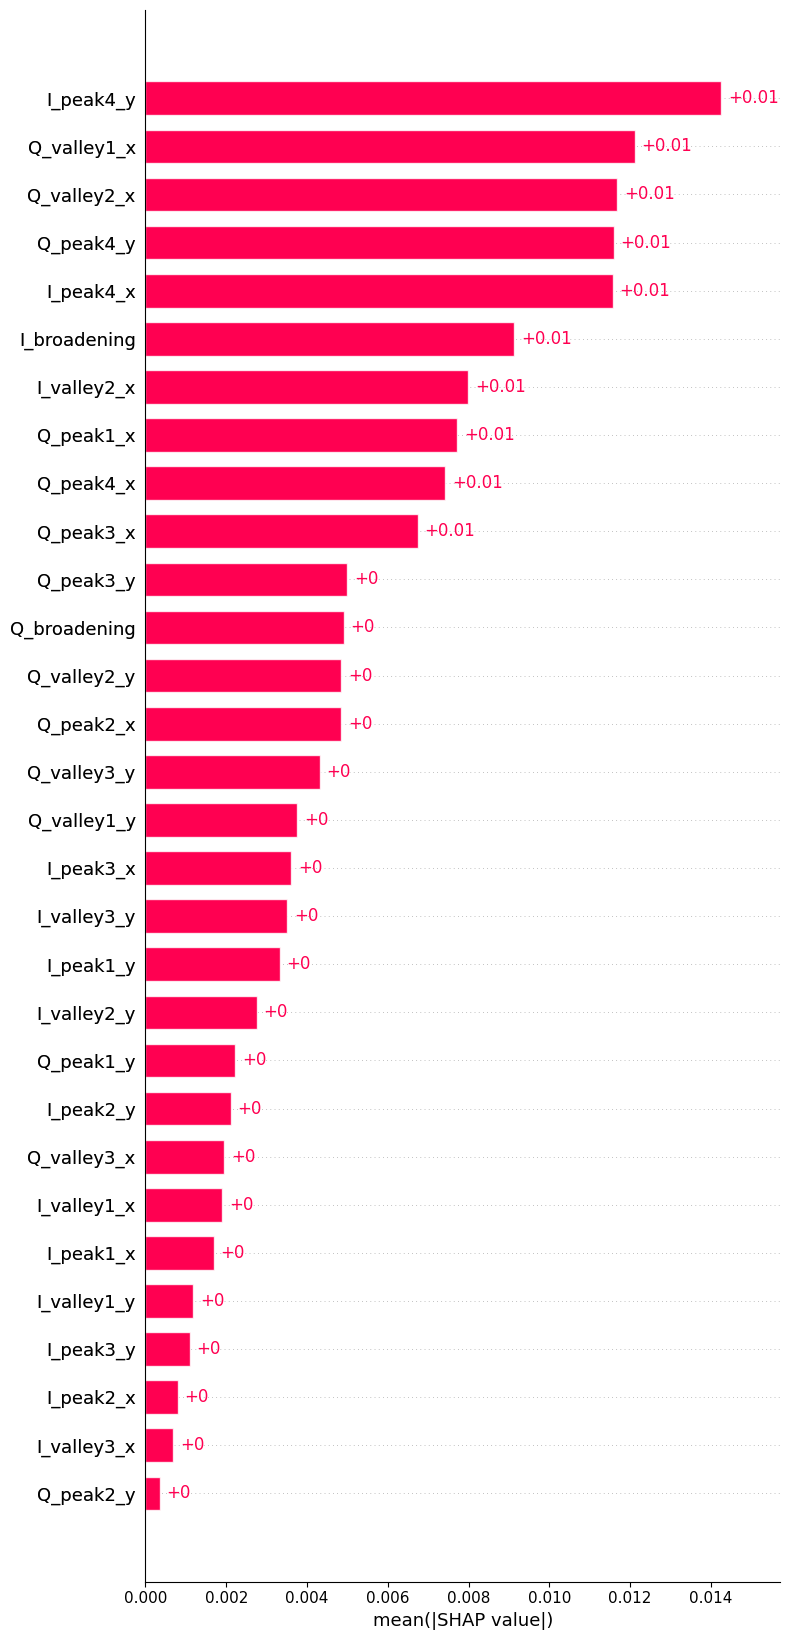

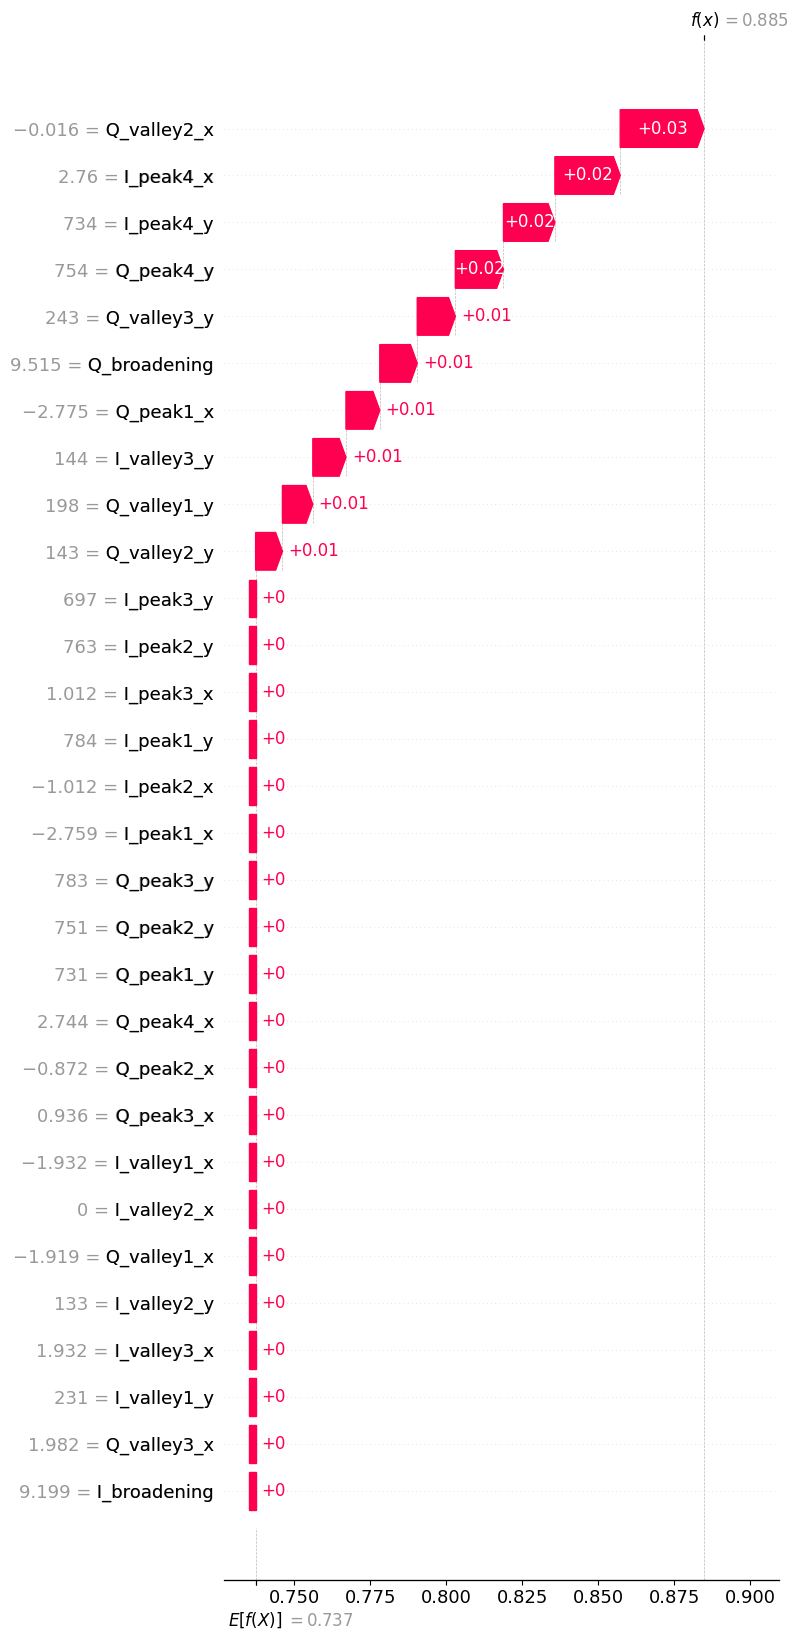


RESUMEN FINAL - SVM BLIND - 16 GBd
NESTED CROSS-VALIDATION 5x5

CARACTERÍSTICAS:
30 I/Q
OSNR excluida
channel_spacing excluido de X

CRITERIO GRID SEARCH:
F1 de ALARMA

--- OUTER CV: PROMEDIO ± STD ---
accuracy              : 0.7532 ± 0.0245
precision             : 0.7613 ± 0.0189
recall                : 0.9722 ± 0.0176
f1                    : 0.8537 ± 0.0146
specificity           : 0.1269 ± 0.0839
balanced_accuracy     : 0.5496 ± 0.0403
f1_macro              : 0.5269 ± 0.0678
precision_normal      : 0.4833 ± 0.2809
recall_normal         : 0.1269 ± 0.0839
f1_normal             : 0.2000 ± 0.1275

--- MÉTRICAS GLOBALES OOF ---
accuracy              : 0.7531
precision             : 0.7609
recall                : 0.9722
f1                    : 0.8537
specificity           : 0.1270
balanced_accuracy     : 0.5496
f1_macro              : 0.5321
precision_normal      : 0.6154
recall_normal         : 0.1270
f1_normal             : 0.2105

--- TIEMPO DE INFERENCIA ---
Inference: 13.583 ± 2.104 

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

# 16 GBd con roll-off = 0.1
# BW = Rs * (1 + alpha) = 17.6 GHz
THRESHOLD_GHZ = 17.6

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 500

OUTPUT_PREFIX = "svm_spacing_16GBd_blind_nested"

# ============================================================
# 2. NOMBRES DE LAS CARACTERÍSTICAS
# ============================================================

# MONITOREO CIEGO:
#
# X contiene únicamente 30 características I/Q.
#
# Se excluyen:
#   - channel_spacing
#   - OSNR

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATOS
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura original:
#
# Columnas 0-29 -> 30 características I/Q
# Columna 30    -> channel_spacing
# Columna 31    -> OSNR

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas, "
        f"pero se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 4. DEFINIR X E y
# ============================================================

# Espaciamiento espectral real.
y_spacing = matriz.iloc[:, 30].to_numpy()

# OSNR solo se conserva como metadato.
# Nunca se utiliza como predictor.
osnr_values = matriz.iloc[:, 31].to_numpy()

# MONITOREO CIEGO:
# únicamente las primeras 30 columnas.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# Etiquetas:
#
# 0 = NORMAL: spacing > 17.6 GHz
# 1 = ALARMA: spacing <= 17.6 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

# Comprobar que ambas clases tienen suficientes
# muestras para Outer CV e Inner CV.

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Outer CV."
    )

min_outer_train_class = min(
    int(count - np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Inner CV."
    )

print("\n" + "=" * 70)
print("SVM - SPACING 16 GBd - MONITOREO CIEGO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print(f"Número de características: {X.shape[1]}")
print(f"OSNR utilizada: {'OSNR' in X.columns}")

# ============================================================
# 5. PIPELINE SVM
# ============================================================

def build_svm(probability=False):
    """
    Pipeline:
        StandardScaler -> SVC

    StandardScaler se ajusta dentro de cada fold.

    probability=False:
        para GridSearchCV y evaluación OOF.

    probability=True:
        únicamente para el modelo final de SHAP.
    """

    return Pipeline([
        ("scaler", StandardScaler()),
        (
            "svm",
            SVC(
                probability=probability,
                random_state=SEED
            )
        )
    ])

# ============================================================
# 6. GRID DE HIPERPARÁMETROS
# ============================================================

# Se conserva exactamente el grid original.
#
# Linear:
#   C = [0.1, 1, 10, 100]
#   Total: 4 configuraciones
#
# RBF:
#   4 valores de C x 4 valores de gamma
#   Total: 16 configuraciones
#
# TOTAL = 20 configuraciones

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": [
            "scale",
            0.01,
            0.1,
            1
        ]
    }
]

n_combinations = len(
    list(ParameterGrid(param_grid))
)

print("\nGRID SEARCH:")
print(f"Combinaciones: {n_combinations}")
print("Kernels: Linear y RBF")
print("Scoring: F1 ALARMA")
print(f"Outer folds: {N_OUTER_FOLDS}")
print(f"Inner folds: {N_INNER_FOLDS}")

# ============================================================
# 7. FUNCIÓN DE MÉTRICAS
# ============================================================

def calculate_metrics(y_true, y_pred):
    """
    Calcula las métricas de clasificación.

    Clase 0: NORMAL
    Clase 1: ALARMA

    Precision, Recall y F1 corresponden a ALARMA.

    Specificity corresponde al recall de NORMAL.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "precision_normal": precision_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "recall_normal": recall_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "f1_normal": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

# ============================================================
# 8. CONFIGURAR OUTER CV
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra será predicha exactamente una vez
# por un modelo que no la utilizó para entrenar.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# La decision_function de SVM devuelve un margen,
# NO una probabilidad.
oof_decision_scores = np.full(
    n_samples,
    np.nan,
    dtype=float
)

oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

nested_start = time.perf_counter()

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE PRINCIPAL: OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 OUTER TRAIN / OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {X_outer_train.shape}")
    print(f"Outer Test:  {X_outer_test.shape}")

    # --------------------------------------------------------
    # 9.2 INNER CV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    # GridSearchCV recibe exclusivamente
    # el outer train.
    #
    # El outer test permanece completamente
    # separado durante:
    #
    # - Ajuste del StandardScaler
    # - Selección de kernel
    # - Selección de C
    # - Selección de gamma
    # - Entrenamiento del SVM

    search = GridSearchCV(
        estimator=build_svm(probability=False),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    # GridSearchCV ya reentrenó el mejor pipeline
    # utilizando todo el outer train.
    best_svm = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.4 PREDICCIONES OUTER-FOLD
    # --------------------------------------------------------

    # El outer test nunca participó en
    # entrenamiento ni selección.

    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    y_outer_score = best_svm.decision_function(
        X_outer_test
    )

    # Guardar las predicciones en las posiciones
    # originales del dataset.

    oof_predictions[test_idx] = y_outer_pred

    oof_decision_scores[test_idx] = y_outer_score

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.5 MÉTRICAS OUTER FOLD
    # --------------------------------------------------------

    fold_metrics = calculate_metrics(
        y_outer_test,
        y_outer_pred
    )

    # --------------------------------------------------------
    # 9.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up:
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        # Tiempo promedio por muestra del batch.
        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        **fold_metrics,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    for metric, value in fold_metrics.items():

        if metric not in ["tn", "fp", "fn", "tp"]:
            print(
                f"{metric:22s}: {value:.4f}"
            )

    print("\nMatriz de confusión del fold:")

    print(
        confusion_matrix(
            y_outer_test,
            y_outer_pred,
            labels=[0, 1]
        )
    )

    print(
        f"\nInference: {inference_mean_us:.3f} "
        f"± {inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. TIEMPO TOTAL NESTED CV
# ============================================================

nested_time = (
    time.perf_counter() - nested_start
)

print("\n" + "=" * 70)
print("NESTED CROSS-VALIDATION COMPLETADA")
print("=" * 70)

print(
    f"Tiempo total: {nested_time:.2f} s "
    f"({nested_time / 60:.2f} min)"
)

# ============================================================
# 11. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_decision_scores).all():
    raise RuntimeError(
        "Existen puntuaciones OOF inválidas."
    )

print(
    "\nTodas las muestras tienen "
    "una predicción OOF válida."
)

# ============================================================
# 12. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 13. PROMEDIO ± STD OUTER CV
# ============================================================

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "balanced_accuracy",
    "f1_macro",
    "precision_normal",
    "recall_normal",
    "f1_normal"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:22s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 14. BOXPLOT OUTER CV
# ============================================================

plot_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "specificity",
    "balanced_accuracy",
    "f1_macro"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in plot_metrics
    ],
    tick_labels=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 ALARMA",
        "Specificity",
        "Balanced Acc.",
        "F1 Macro"
    ]
)

plt.ylabel("Score")

plt.title(
    "SVM - Spacing 16 GBd - Ciego\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MÉTRICAS GLOBALES OOF
# ============================================================

# Se evalúa el 100 % de las muestras.
#
# Cada predicción proviene del modelo entrenado
# sin utilizar la muestra correspondiente.

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:
        print(
            f"{metric:22s}: {value:.4f}"
        )

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Blind - 16 GBd\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "SVM Blind - 16 GBd\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 18. GUARDAR PREDICCIONES OOF
# ============================================================

# Se conservan los valores físicos de spacing
# y OSNR únicamente como metadatos.
#
# No se utilizaron como entradas del SVM.

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": osnr_values,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score_alarm": oof_decision_scores,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 19. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 20. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# 5 outer folds x 100 repeticiones
# = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean_us = (
    all_inference_times.mean()
)

inference_std_us = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean_us:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std_us:.3f} µs/muestra"
)

print(
    f"Mediciones: {len(all_inference_times)}"
)

print(
    "Incluye StandardScaler y SVM.predict()."
)

print(
    "No incluye extracción de características, "
    "entrenamiento, Grid Search ni SHAP."
)

# ============================================================
# 21. GRID SEARCH FINAL SOBRE TODO EL DATASET
# ============================================================

# Este GridSearchCV selecciona los hiperparámetros
# para el modelo final que se explicará con SHAP.
#
# No modifica las métricas OOF.
#
# El mejor F1 de esta búsqueda no debe utilizarse
# como estimación principal de generalización.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - SVM BLIND")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_svm(probability=False),
    param_grid=param_grid,
    scoring="f1",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

print("\nMejores hiperparámetros finales:")
print(final_best_params)

print(
    f"Mejor F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

# ============================================================
# 22. ENTRENAR MODELO FINAL PROBABILÍSTICO
# ============================================================

# Para SHAP queremos explicar:
#
#     P(ALARMA | X)
#
# Por ello se entrena un modelo final
# con probability=True.
#
# Los hiperparámetros provienen de GridSearchCV.
#
# Las métricas OOF siguen correspondiendo
# exclusivamente a los modelos probability=False.

best_kernel = final_best_params["svm__kernel"]

best_C = final_best_params["svm__C"]

best_gamma = final_best_params.get(
    "svm__gamma",
    "scale"
)

final_svm = Pipeline([
    ("scaler", StandardScaler()),
    (
        "svm",
        SVC(
            kernel=best_kernel,
            C=best_C,
            gamma=best_gamma,
            probability=True,
            random_state=SEED
        )
    )
])

final_train_start = time.perf_counter()

final_svm.fit(X, y)

final_train_time = (
    time.perf_counter() - final_train_start
)

print("\nMODELO FINAL:")
print(f"Kernel: {best_kernel}")
print(f"C: {best_C}")

if best_kernel == "rbf":
    print(f"Gamma: {best_gamma}")

print(
    f"Tiempo entrenamiento probabilístico: "
    f"{final_train_time:.2f} s"
)

# ============================================================
# 23. SHAP - KERNELEXPLAINER
# ============================================================

# Se explica el modelo final.
#
# SHAP positivo:
#   aumenta P(ALARMA).
#
# SHAP negativo:
#   disminuye P(ALARMA).
#
# Solo se explican las 30 características I/Q.
#
# IMPORTANTE:
# Estas explicaciones NO son OOF porque
# el modelo final se entrenó con todo el dataset.

print("\n" + "=" * 70)
print("SHAP - SVM SPACING 16 GBd - CIEGO")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

print(f"SHAP nsamples: {SHAP_NSAMPLES}")

# ------------------------------------------------------------
# 23.1 FUNCIÓN PARA SHAP
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe 30 características I/Q.

    Devuelve la probabilidad estimada
    de la clase ALARMA = 1.
    """

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.predict_proba(data)[:, 1]

# ------------------------------------------------------------
# 23.2 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw_shap = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = (
    time.perf_counter() - shap_start
)

shap_values = np.asarray(raw_shap)

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: {shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

base_alarm = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 24. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 30 CARACTERÍSTICAS I/Q")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 CARACTERÍSTICAS:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 25. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 26. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 29. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - SVM BLIND - 16 GBd")
print("NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

print("\nCARACTERÍSTICAS:")
print("30 I/Q")
print("OSNR excluida")
print("channel_spacing excluido de X")

print("\nCRITERIO GRID SEARCH:")
print("F1 de ALARMA")

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:22s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:22s}: {value:.4f}"
        )

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean_us:.3f} "
    f"± {inference_std_us:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print(f"Kernel: {best_kernel}")
print(f"C: {best_C}")

if best_kernel == "rbf":
    print(f"Gamma: {best_gamma}")

print(
    f"F1 GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

print(
    f"Entrenamiento probabilístico: "
    f"{final_train_time:.2f} s"
)

print("\n--- SHAP ---")

print(f"Tiempo SHAP: {shap_time:.2f} s")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 16GBd para clasificar SEPARACIÓN ESPECTRAL SIN OSNR


KNN - SPACING 16 GBd - MONITOREO CIEGO
Dataset: matriz16GBd_clas.csv
Forma matriz: (243, 32)
Forma X: (243, 30)
Total muestras: 243
NORMAL (> 17.6 GHz): 63
ALARMA (<= 17.6 GHz): 180
Número de características: 30
OSNR utilizada: False

GRID SEARCH:
Combinaciones: 84
Scoring: F1-MACRO
Outer folds: 5
Inner folds: 5

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: (194, 30)
Outer Test:  (49, 30)
Fitting 5 folds for each of 84 candidates, totalling 420 fits

Mejores parámetros:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
Mejor F1 Macro Inner CV: 0.6503
Tiempo GridSearchCV: 0.23 s (0.00 min)

MÉTRICAS OUTER FOLD:
accuracy                : 0.8163
balanced_accuracy       : 0.7030
f1_macro                : 0.7273
precision_alarm         : 0.8293
recall_alarm            : 0.9444
f1_alarm                : 0.8831
precision_normal        : 0.7500
recall_normal           : 0.4615
f1_normal               : 0.5714
specificity         

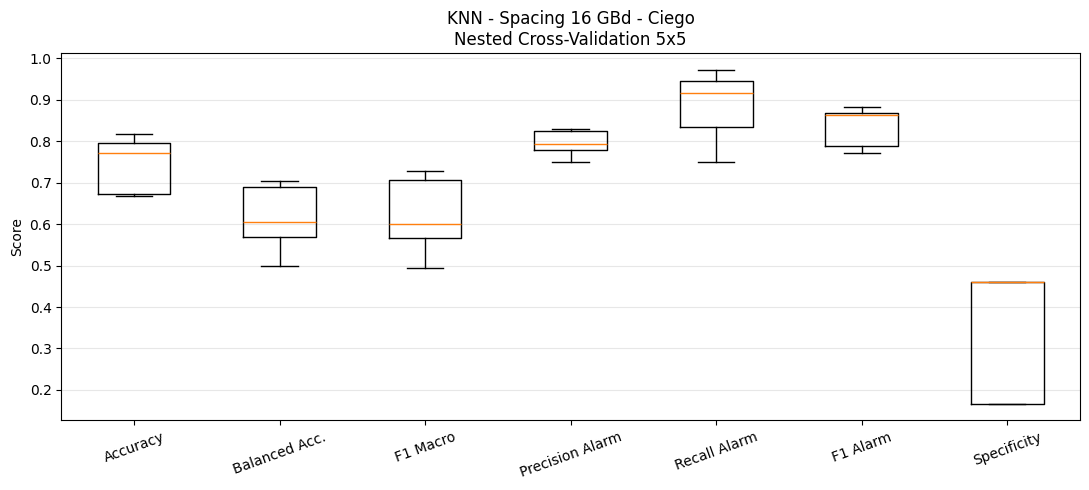


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy                : 0.7449
balanced_accuracy       : 0.6163
f1_macro                : 0.6260
precision_alarm         : 0.7950
recall_alarm            : 0.8833
f1_alarm                : 0.8368
precision_normal        : 0.5116
recall_normal           : 0.3492
f1_normal               : 0.4151
specificity             : 0.3492

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.51      0.35      0.42        63
      ALARMA       0.80      0.88      0.84       180

    accuracy                           0.74       243
   macro avg       0.65      0.62      0.63       243
weighted avg       0.72      0.74      0.73       243


Matriz de confusión OOF:
[[ 22  41]
 [ 21 159]]


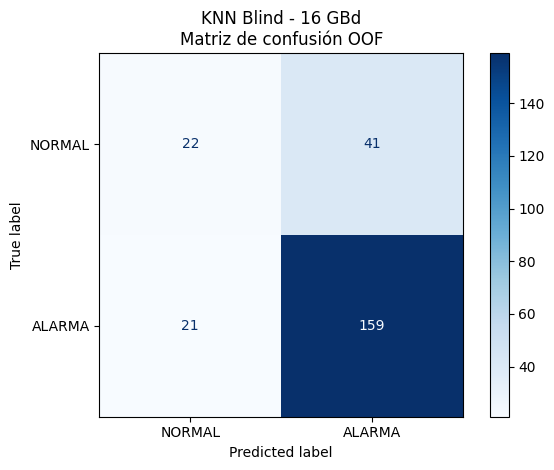

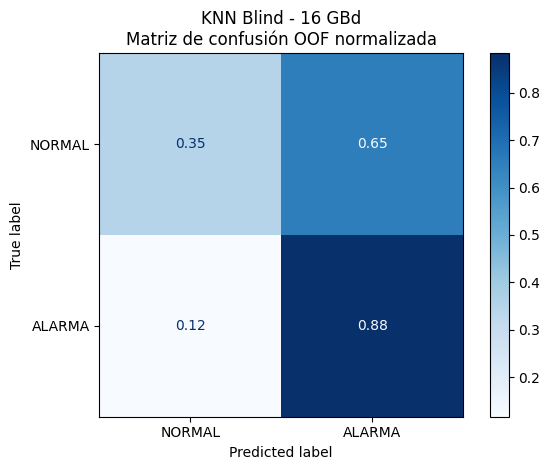


HIPERPARÁMETROS POR OUTER FOLD:
 fold knn__metric  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1_macro  grid_time_s
    1   euclidean                 3       1      uniform                0.650345     0.226250
    2   manhattan                 3       1      uniform                0.614296     0.131984
    3   manhattan                 3       1      uniform                0.648815     0.130327
    4   euclidean                 3       1      uniform                0.677497     0.131074
    5   euclidean                 3       1      uniform                0.602685     0.136968

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 20.137 µs/muestra
Inference Std: 1.279 µs/muestra
Mediciones: 500
Incluye StandardScaler y KNN.predict().
No incluye extracción de características, entrenamiento, Grid Search ni SHAP.

GRID SEARCH FINAL - KNN BLIND
Fitting 5 folds for each of 84 candidates, totalling 420 fits

Mejores hiperparámetros finales:
{'knn__metric': 'euclidean', 'knn__n_neighb

  0%|          | 0/50 [00:00<?, ?it/s]


Tiempo SHAP: 0.60 s (0.01 min)

RANKING SHAP - 30 CARACTERÍSTICAS I/Q
     feature mean_abs_shap importance_percent
   I_peak4_x      0.018576              8.21%
   Q_peak4_x      0.015188              6.71%
   I_peak3_x      0.014796              6.54%
   I_peak4_y      0.014347              6.34%
 Q_valley2_x      0.014202              6.27%
 I_valley2_x      0.012536              5.54%
   Q_peak3_x      0.012515              5.53%
Q_broadening      0.012043              5.32%
   I_peak1_x      0.010121              4.47%
I_broadening      0.009435              4.17%
 Q_valley1_x      0.008608              3.80%
   Q_peak2_x      0.007756              3.43%
   Q_peak1_y      0.007607              3.36%
   Q_peak3_y      0.005971              2.64%
   Q_peak1_x      0.005794              2.56%
   Q_peak4_y      0.005584              2.47%
   I_peak1_y      0.005221              2.31%
 I_valley3_y      0.005030              2.22%
   I_peak3_y      0.004820              2.13%
   I_peak

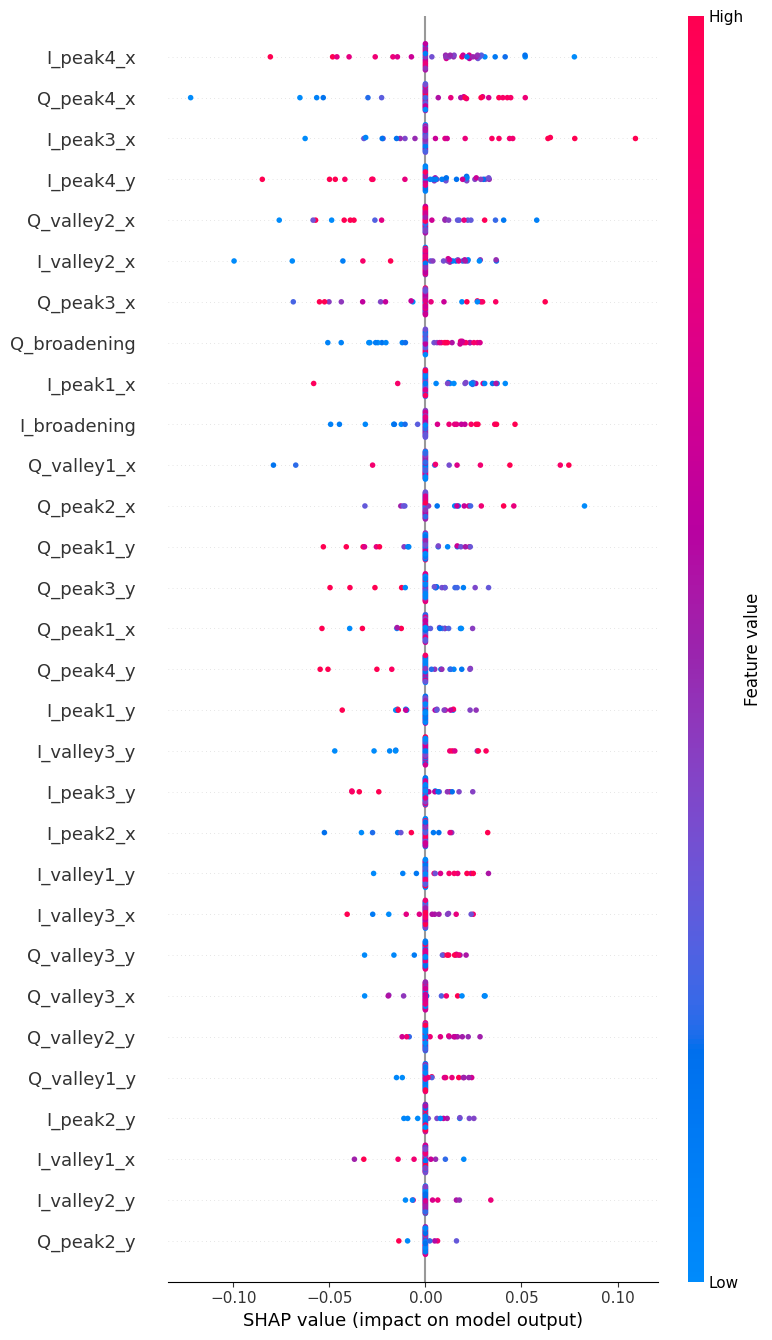

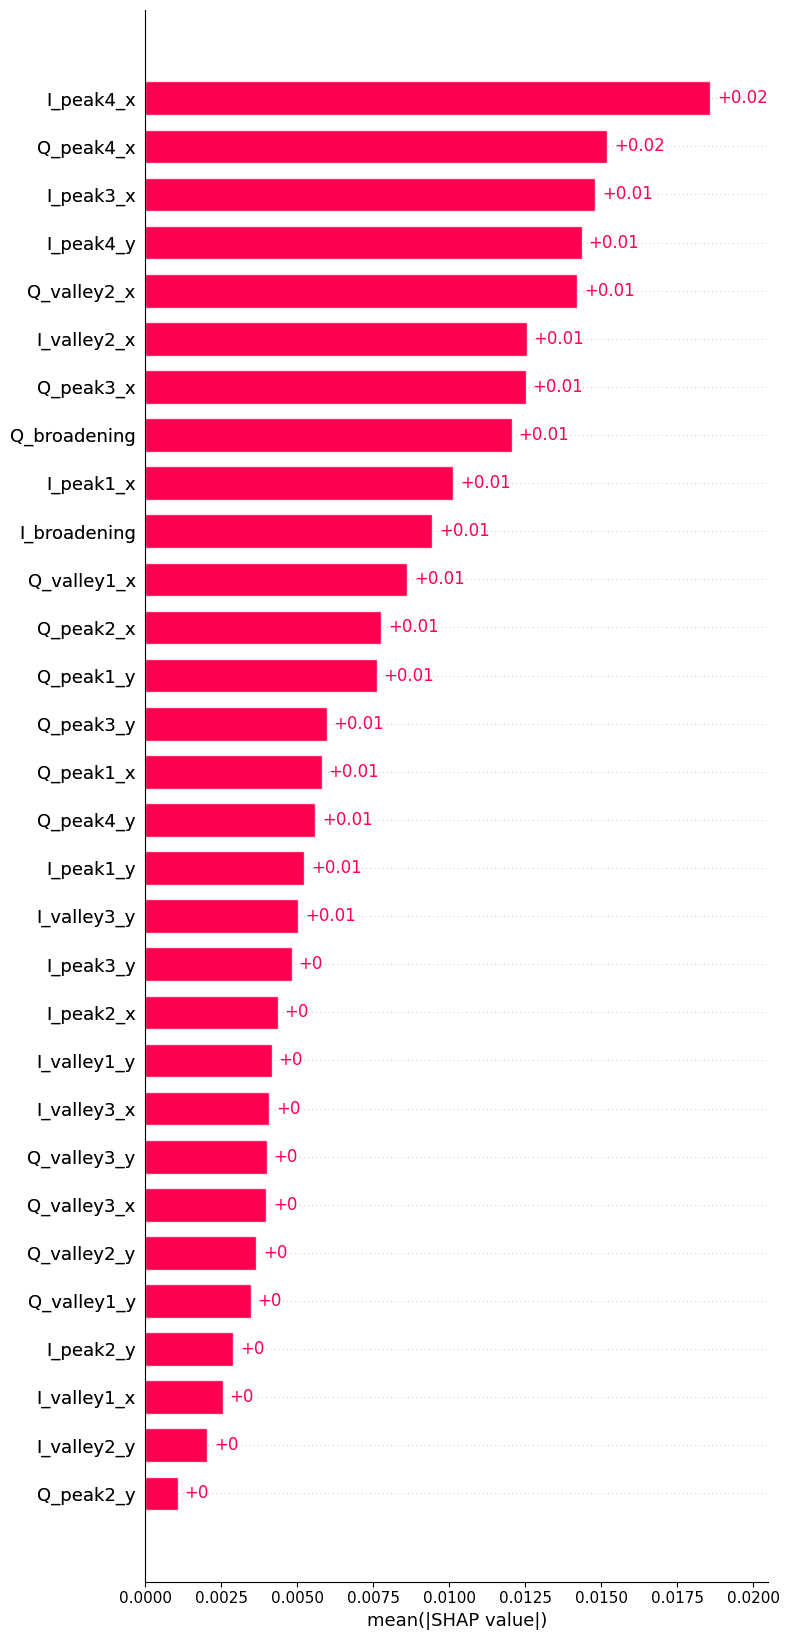

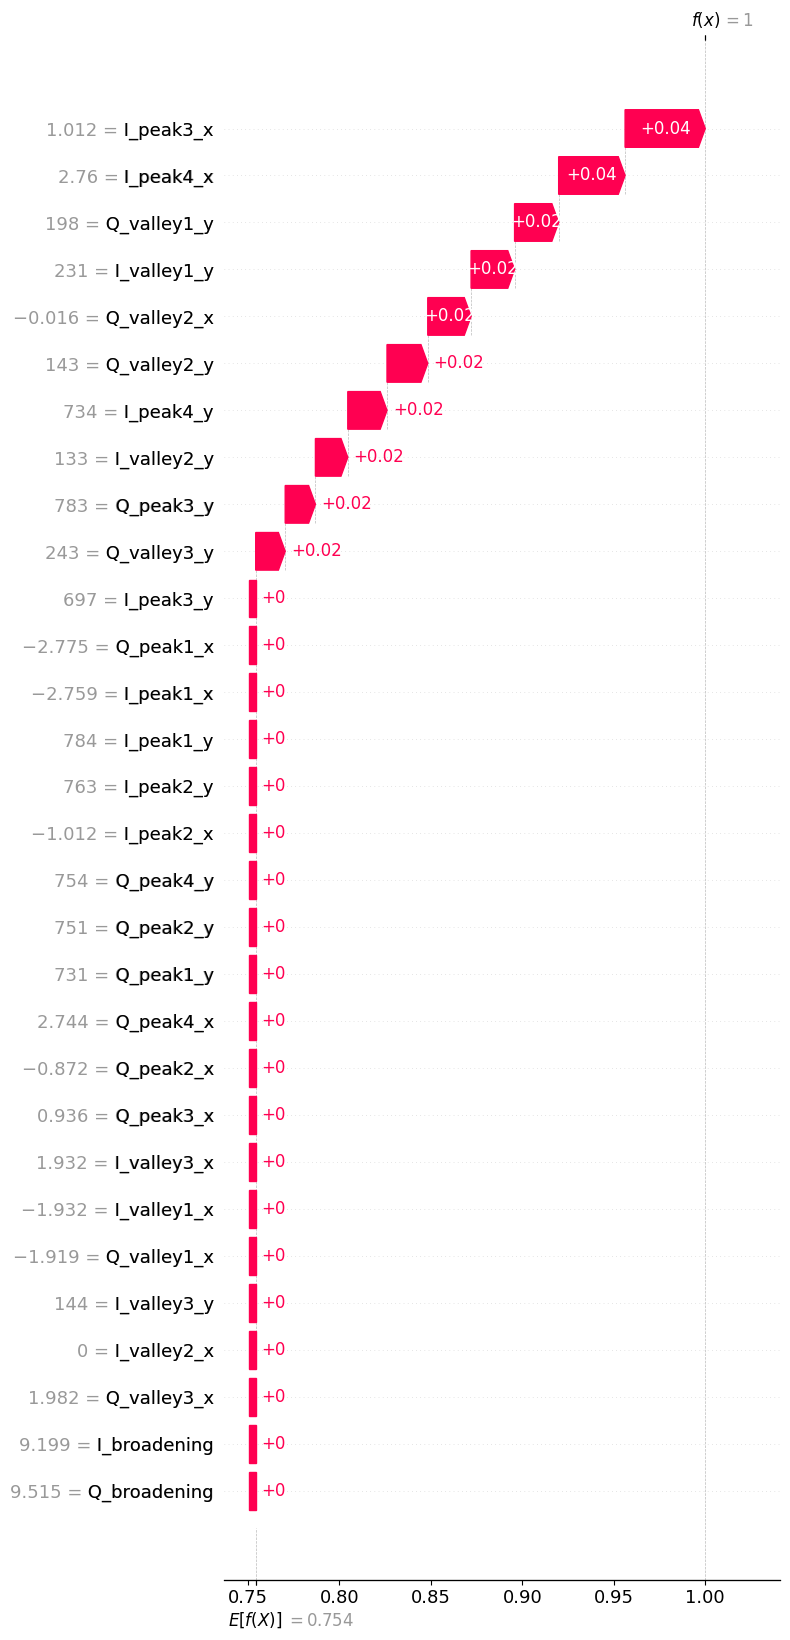


RESUMEN FINAL - KNN BLIND - 16 GBd
NESTED CROSS-VALIDATION 5x5

CARACTERÍSTICAS:
30 I/Q
OSNR excluida
channel_spacing excluido de X

CRITERIO GRID SEARCH:
F1 MACRO

--- OUTER CV: PROMEDIO ± STD ---
accuracy                : 0.7446 ± 0.0626
balanced_accuracy       : 0.6135 ± 0.0756
f1_macro                : 0.6189 ± 0.0873
precision_alarm         : 0.7952 ± 0.0297
recall_alarm            : 0.8833 ± 0.0813
f1_alarm                : 0.8353 ± 0.0456
precision_normal        : 0.5467 ± 0.1896
recall_normal           : 0.3436 ± 0.1445
f1_normal               : 0.4024 ± 0.1477
specificity             : 0.3436 ± 0.1445

--- MÉTRICAS GLOBALES OOF ---
accuracy                : 0.7449
balanced_accuracy       : 0.6163
f1_macro                : 0.6260
precision_alarm         : 0.7950
recall_alarm            : 0.8833
f1_alarm                : 0.8368
precision_normal        : 0.5116
recall_normal           : 0.3492
f1_normal               : 0.4151
specificity             : 0.3492

--- TIEMPO DE INFER

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz16GBd_clas.csv"

# 16 GBd con roll-off = 0.1:
# BW = 16 * (1 + 0.1) = 17.6 GHz
THRESHOLD_GHZ = 17.6

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 500

OUTPUT_PREFIX = "knn_spacing_16GBd_blind_nested"

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS I/Q
# ============================================================

# MONITOREO CIEGO:
#
# Se utilizan exclusivamente características
# extraídas de los histogramas I/Q.
#
# NO se utiliza:
#   - OSNR
#   - channel_spacing como predictor

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura:
#
# Columnas 0-29: 30 características I/Q
# Columna 30:    channel_spacing
# Columna 31:    OSNR
#
# Total: 32 columnas

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas, "
        f"pero se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 4. DEFINIR ENTRADAS X Y ETIQUETAS y
# ============================================================

# Espaciamiento espectral real.
# Solo se utiliza para construir el target.
y_spacing = matriz.iloc[:, 30].to_numpy()

# OSNR se conserva exclusivamente como metadato.
osnr_values = matriz.iloc[:, 31].to_numpy()

# MONITOREO CIEGO:
# solamente las 30 primeras columnas.
X = matriz.iloc[:, :30].copy()

X.columns = feature_names

# Etiquetas:
#
# 0 = NORMAL: spacing > 17.6 GHz
# 1 = ALARMA: spacing <= 17.6 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

# Verificar que existen suficientes muestras
# por clase para Outer CV e Inner CV.

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Outer CV."
    )

min_outer_train_class = min(
    int(count - np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Inner CV."
    )

print("\n" + "=" * 70)
print("KNN - SPACING 16 GBd - MONITOREO CIEGO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print(f"Número de características: {X.shape[1]}")
print(f"OSNR utilizada: {'OSNR' in X.columns}")

# ============================================================
# 5. CONSTRUIR PIPELINE KNN
# ============================================================

def build_knn():
    """
    Construye un pipeline nuevo:

        StandardScaler -> KNeighborsClassifier

    El escalado se ajusta únicamente sobre
    los datos de entrenamiento de cada fold.

    Esto evita fuga de información.
    """

    return Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier())
    ])

# ============================================================
# 6. GRID DE HIPERPARÁMETROS
# ============================================================

# Se conserva el grid original:
#
# n_neighbors: 7 valores
# weights:     2 valores
# metric:      3 valores
# p:           2 valores
#
# TOTAL = 7 * 2 * 3 * 2 = 84 configuraciones
#
# Algunas configuraciones son equivalentes,
# porque p no afecta euclidean ni manhattan.
#
# Se conservan para mantener el experimento.

param_grid = {
    "knn__n_neighbors": [
        3, 5, 7, 9, 11, 15, 21
    ],

    "knn__weights": [
        "uniform",
        "distance"
    ],

    "knn__metric": [
        "euclidean",
        "manhattan",
        "minkowski"
    ],

    "knn__p": [
        1, 2
    ]
}

n_combinations = len(
    list(ParameterGrid(param_grid))
)

print("\nGRID SEARCH:")
print(f"Combinaciones: {n_combinations}")
print("Scoring: F1-MACRO")
print(f"Outer folds: {N_OUTER_FOLDS}")
print(f"Inner folds: {N_INNER_FOLDS}")

# ============================================================
# 7. FUNCIÓN PARA CALCULAR MÉTRICAS
# ============================================================

def calculate_metrics(y_true, y_pred):
    """
    Calcula métricas para ambas clases.

    NORMAL = 0
    ALARMA = 1

    También calcula:
        Accuracy
        Balanced Accuracy
        F1 Macro
        Specificity

    F1 Macro es el criterio de optimización.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "precision_alarm": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall_alarm": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1_alarm": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "precision_normal": precision_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "recall_normal": recall_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "f1_normal": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

# ============================================================
# 8. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra tendrá una predicción realizada
# por un modelo que nunca la utilizó
# durante entrenamiento o selección.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

nested_start = time.perf_counter()

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE PRINCIPAL OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 DIVIDIR OUTER TRAIN Y OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {X_outer_train.shape}")
    print(f"Outer Test:  {X_outer_test.shape}")

    # --------------------------------------------------------
    # 9.2 DEFINIR INNER CV
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    # GridSearchCV solo recibe el outer train.
    #
    # Dentro de cada inner fold:
    #
    #   1. Se ajusta StandardScaler.
    #   2. Se entrena KNN.
    #   3. Se evalúa F1 Macro.
    #
    # Se seleccionan los mejores hiperparámetros.
    #
    # Finalmente, GridSearchCV reajusta
    # el mejor pipeline sobre todo el outer train.

    search = GridSearchCV(
        estimator=build_knn(),
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    best_knn = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Macro Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s "
        f"({grid_time / 60:.2f} min)"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1_macro": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.4 PREDICCIONES OUTER TEST
    # --------------------------------------------------------

    # Estas muestras no fueron utilizadas
    # para entrenar ni seleccionar hiperparámetros.

    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad estimada de ALARMA.
    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar en la posición original del dataset.
    oof_predictions[test_idx] = y_outer_pred

    oof_probabilities[test_idx] = y_outer_proba

    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.5 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    fold_metrics = calculate_metrics(
        y_outer_test,
        y_outer_pred
    )

    # --------------------------------------------------------
    # 9.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Warm-up:
    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        # Tiempo por muestra del batch.
        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        **fold_metrics,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    for metric, value in fold_metrics.items():

        if metric not in ["tn", "fp", "fn", "tp"]:
            print(
                f"{metric:24s}: {value:.4f}"
            )

    print("\nMatriz de confusión del fold:")

    print(
        confusion_matrix(
            y_outer_test,
            y_outer_pred,
            labels=[0, 1]
        )
    )

    print(
        f"\nInference: {inference_mean_us:.3f} "
        f"± {inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. TIEMPO TOTAL NESTED CV
# ============================================================

nested_time = (
    time.perf_counter() - nested_start
)

print("\n" + "=" * 70)
print("NESTED CROSS-VALIDATION COMPLETADA")
print("=" * 70)

print(
    f"Tiempo total: {nested_time:.2f} s "
    f"({nested_time / 60:.2f} min)"
)

# ============================================================
# 11. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print(
    "\nTodas las muestras tienen "
    "una predicción OOF válida."
)

# ============================================================
# 12. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 13. PROMEDIO ± STD DE LOS OUTER FOLDS
# ============================================================

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "precision_normal",
    "recall_normal",
    "f1_normal",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 14. BOXPLOT OUTER CV
# ============================================================

plot_metrics = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "specificity"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in plot_metrics
    ],
    tick_labels=[
        "Accuracy",
        "Balanced Acc.",
        "F1 Macro",
        "Precision Alarm",
        "Recall Alarm",
        "F1 Alarm",
        "Specificity"
    ]
)

plt.ylabel("Score")

plt.title(
    "KNN - Spacing 16 GBd - Ciego\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MÉTRICAS GLOBALES OOF
# ============================================================

# Se reúnen las predicciones de los cinco
# outer folds.
#
# Cada muestra fue predicha exactamente una vez
# por un modelo que no la utilizó para entrenar.

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:
        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Blind - 16 GBd\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "KNN Blind - 16 GBd\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 18. GUARDAR PREDICCIONES OOF
# ============================================================

# El CSV conserva el índice original.
#
# OSNR y channel_spacing aparecen solo
# como metadatos para análisis posterior.
#
# No fueron entradas del KNN.

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": osnr_values,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 19. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 20. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# 5 outer folds x 100 repeticiones
# = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean_us = (
    all_inference_times.mean()
)

inference_std_us = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean_us:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std_us:.3f} µs/muestra"
)

print(
    f"Mediciones: {len(all_inference_times)}"
)

print(
    "Incluye StandardScaler y KNN.predict()."
)

print(
    "No incluye extracción de características, "
    "entrenamiento, Grid Search ni SHAP."
)

# ============================================================
# 21. GRID SEARCH FINAL SOBRE TODO EL DATASET
# ============================================================

# Se seleccionan hiperparámetros utilizando
# todas las muestras.
#
# El modelo final será explicado con SHAP.
#
# IMPORTANTE:
#
# Este GridSearchCV NO modifica las
# predicciones OOF anteriores.
#
# Su best_score_ no debe presentarse como
# rendimiento Nested CV.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - KNN BLIND")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_knn(),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

# GridSearchCV ya reentrenó el mejor
# pipeline sobre todo el dataset.
final_knn = final_search.best_estimator_

print("\nMejores hiperparámetros finales:")
print(final_best_params)

print(
    f"Mejor F1 Macro GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s "
    f"({final_grid_time / 60:.2f} min)"
)

# ============================================================
# 22. SHAP - KERNELEXPLAINER
# ============================================================

# SHAP explica:
#
#     P(ALARMA | 30 características I/Q)
#
# SHAP positivo:
#   aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
#   disminuye la probabilidad de ALARMA.
#
# Se explica el modelo final entrenado
# sobre todo el dataset.
#
# Por tanto, SHAP NO es OOF.

print("\n" + "=" * 70)
print("SHAP - KNN SPACING 16 GBd - CIEGO")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

print(f"SHAP nsamples: {SHAP_NSAMPLES}")

# ------------------------------------------------------------
# 22.1 FUNCIÓN PARA SHAP
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe las 30 características I/Q.

    Devuelve la probabilidad estimada
    de la clase ALARMA = 1.
    """

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(data)[:, 1]

# ------------------------------------------------------------
# 22.2 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw_shap = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = (
    time.perf_counter() - shap_start
)

shap_values = np.asarray(raw_shap)

# Compatibilidad con salidas que tengan
# una dimensión final de tamaño 1.
if (
    shap_values.ndim == 3
    and shap_values.shape[-1] == 1
):
    shap_values = shap_values[:, :, 0]

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: {shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

base_alarm = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 23. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 30 CARACTERÍSTICAS I/Q")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 CARACTERÍSTICAS:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 24. CREAR SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 25. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 26. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - KNN BLIND - 16 GBd")
print("NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

print("\nCARACTERÍSTICAS:")
print("30 I/Q")
print("OSNR excluida")
print("channel_spacing excluido de X")

print("\nCRITERIO GRID SEARCH:")
print("F1 MACRO")

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean_us:.3f} "
    f"± {inference_std_us:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print(final_best_params)

print(
    f"F1 Macro GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

print("\n--- SHAP ---")

print(f"Tiempo SHAP: {shap_time:.2f} s")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## RDF 32GBd para clasificar SEPARACIÓN ESPECTRAL SIN OSNR


RANDOM FOREST - SPACING 32 GBd - MONITOREO CIEGO
Dataset: matriz32GBd_clasifi_correct.csv
Forma matriz original: (9330, 32)
Forma X: (9330, 30)
Total muestras: 9330
NORMAL (> 35.2 GHz): 2951
ALARMA (<= 35.2 GHz): 6379
Características utilizadas: 30
OSNR utilizada como entrada: False

CONFIGURACIÓN NESTED CV:
Outer folds: 5
Inner folds: 5
Combinaciones: 162
Scoring GridSearchCV: F1 ALARMA

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: (7464, 30)
Outer Test:  (1866, 30)
Fitting 5 folds for each of 162 candidates, totalling 810 fits

Mejores parámetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 400}
Mejor F1 ALARMA Inner CV: 0.8202
Tiempo GridSearchCV: 85.76 s (1.43 min)

MÉTRICAS OUTER FOLD:
accuracy                : 0.7245
balanced_accuracy       : 0.6173
f1_macro                : 0.6231
precision_alarm         : 0.7445
recall_alarm            : 0.9091
f1_alarm                : 0.8186
precision_normal

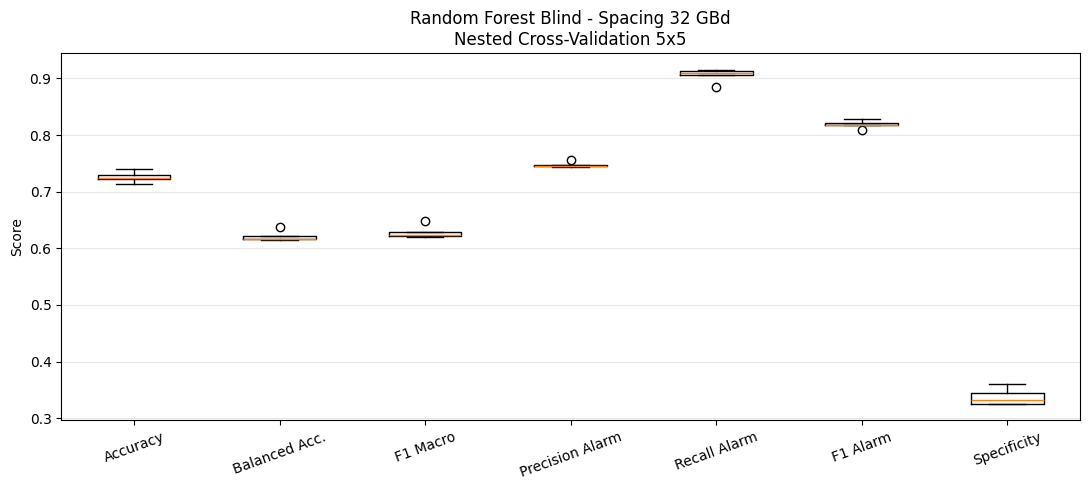


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy                : 0.7259
balanced_accuracy       : 0.6216
f1_macro                : 0.6283
precision_alarm         : 0.7472
recall_alarm            : 0.9056
f1_alarm                : 0.8188
precision_normal        : 0.6233
recall_normal           : 0.3375
f1_normal               : 0.4379
specificity             : 0.3375

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.62      0.34      0.44      2951
      ALARMA       0.75      0.91      0.82      6379

    accuracy                           0.73      9330
   macro avg       0.69      0.62      0.63      9330
weighted avg       0.71      0.73      0.70      9330


Matriz de confusión OOF:
[[ 996 1955]
 [ 602 5777]]


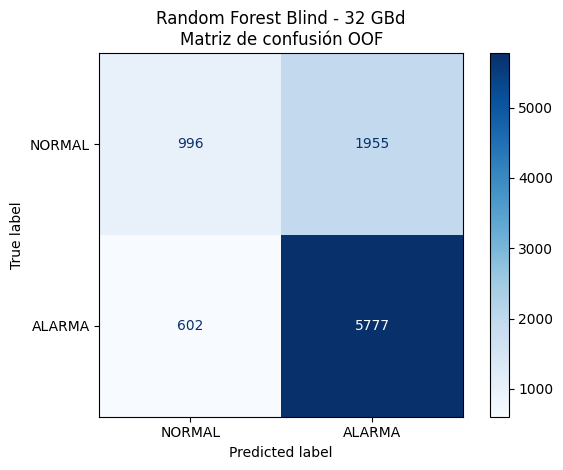

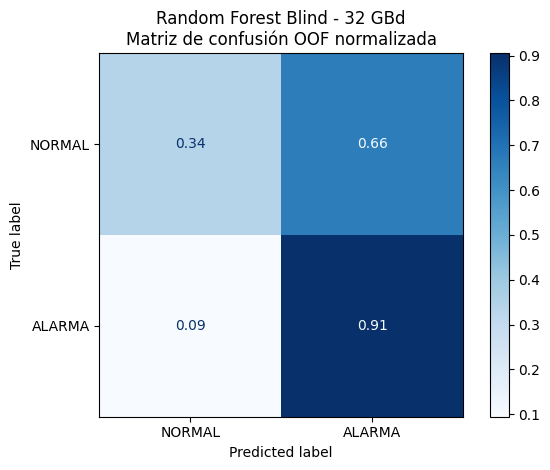


HIPERPARÁMETROS POR OUTER FOLD:
 fold  max_depth max_features  min_samples_leaf  min_samples_split  n_estimators  inner_cv_best_f1_alarm  grid_time_s
    1        NaN         sqrt                 2                  5           400                0.820159    85.757109
    2       10.0         log2                 4                  2           200                0.820275    77.801360
    3       10.0         sqrt                 4                  2           100                0.822739    76.969730
    4       10.0         sqrt                 2                  5           100                0.821729    76.496493
    5       10.0         sqrt                 1                 10           400                0.819593    82.614773

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 16.214 µs/muestra
Inference Std: 12.134 µs/muestra
Mediciones: 500
No incluye extracción de características, entrenamiento, Grid Search ni SHAP.

GRID SEARCH FINAL - RANDOM FOREST BLIND
Fitting 5 folds for each

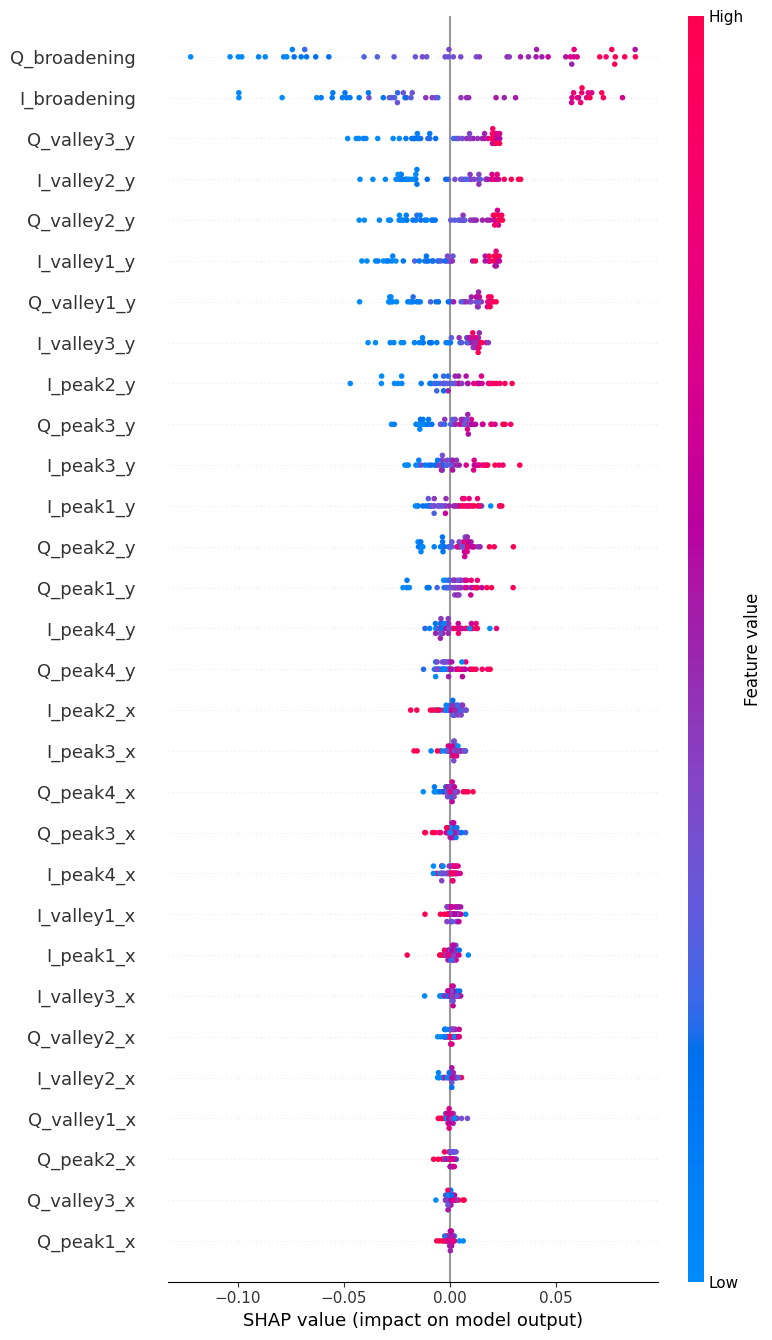

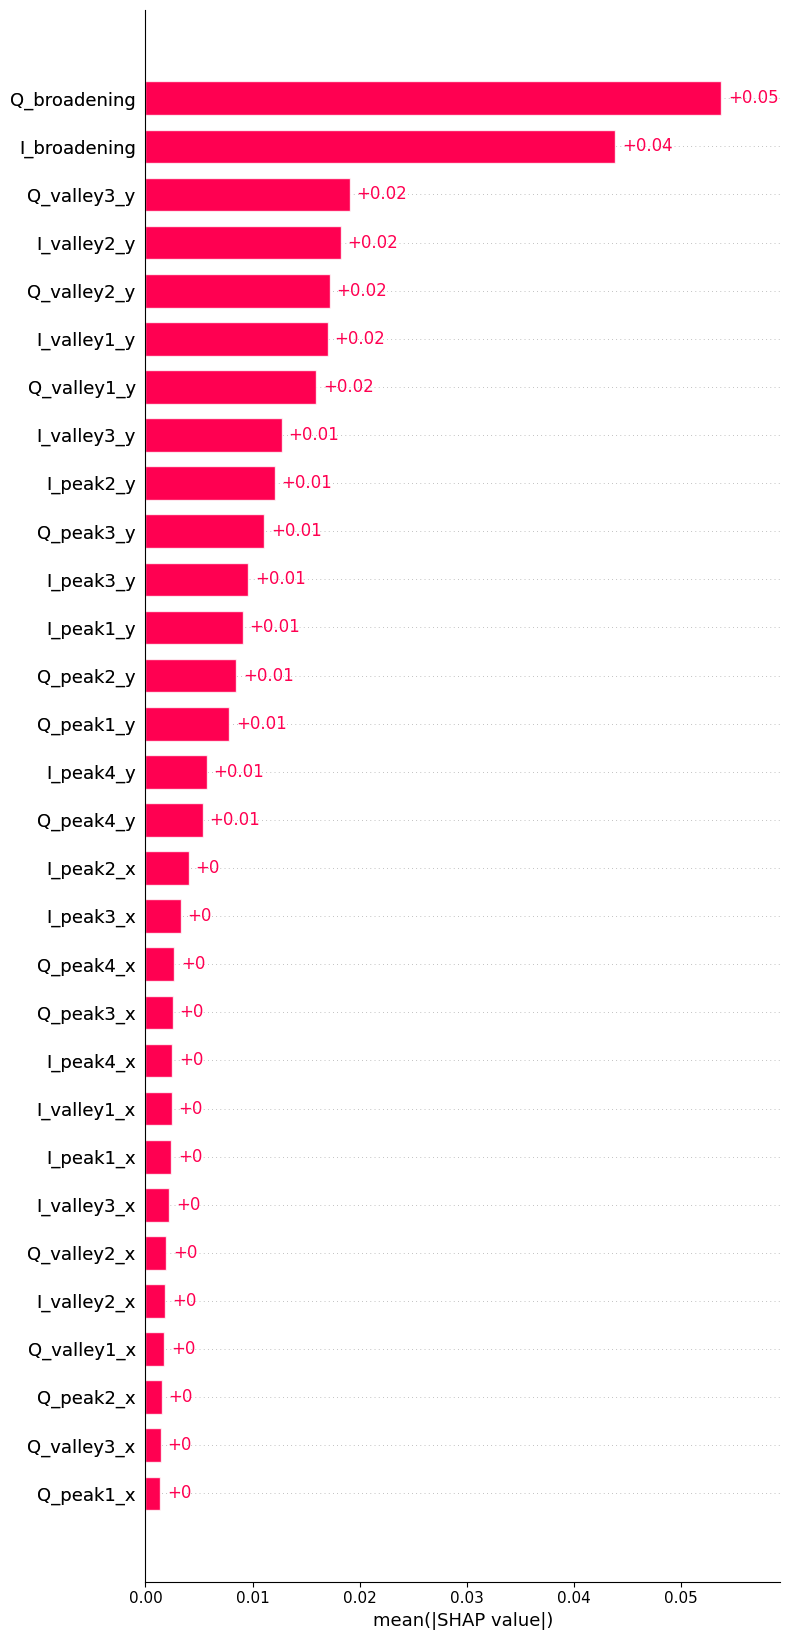

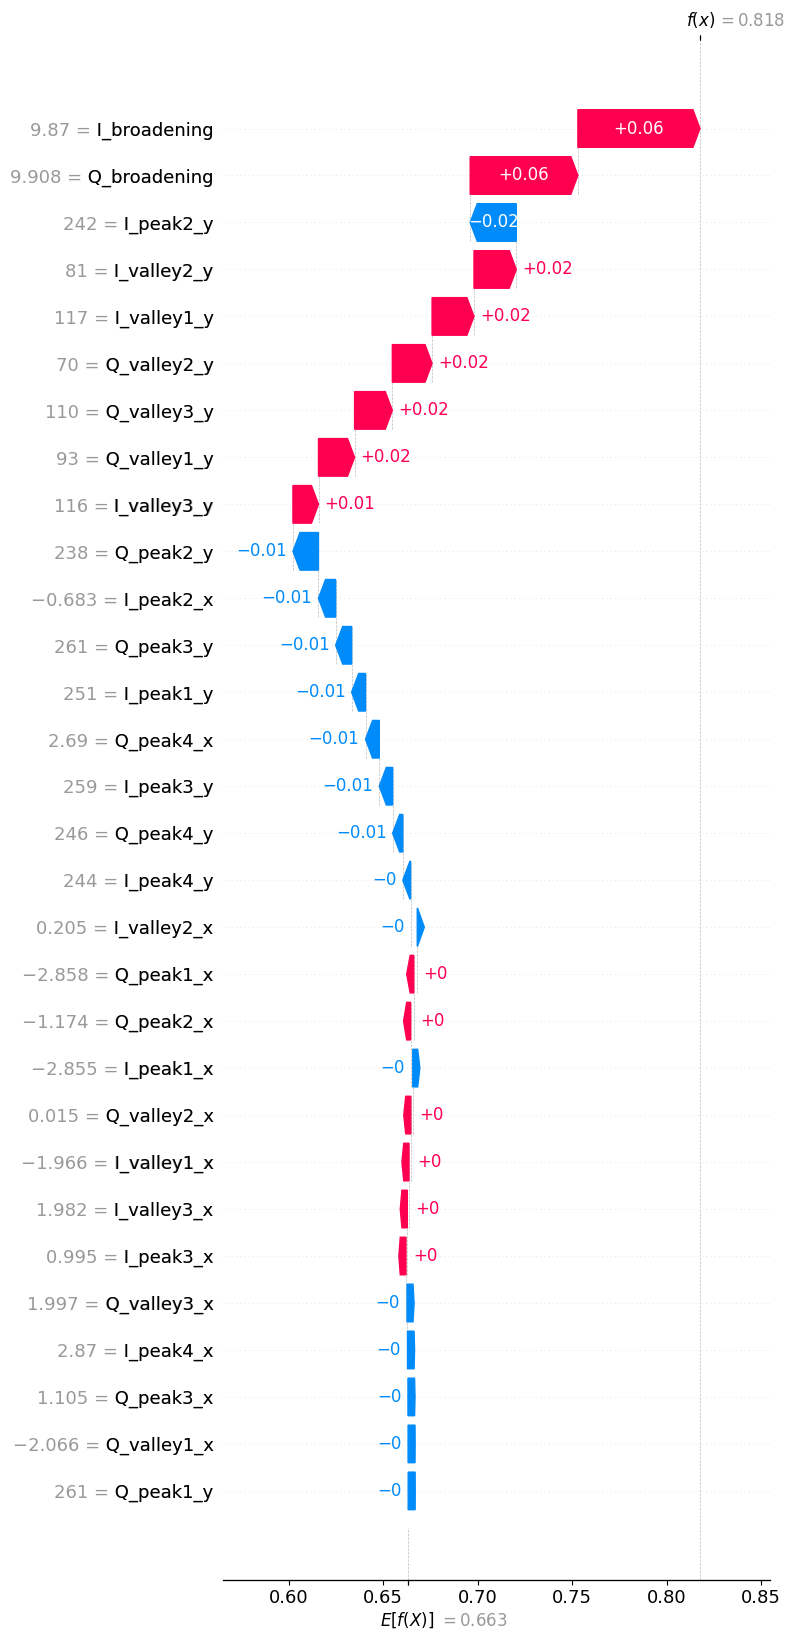


RESUMEN FINAL - RANDOM FOREST BLIND - 32 GBd
NESTED CROSS-VALIDATION 5x5

CARACTERÍSTICAS:
30 I/Q
OSNR excluida
channel_spacing excluido de X

CRITERIO GRID SEARCH:
F1 ALARMA

--- OUTER CV: PROMEDIO ± STD ---
accuracy                : 0.7259 ± 0.0085
balanced_accuracy       : 0.6216 ± 0.0086
f1_macro                : 0.6283 ± 0.0100
precision_alarm         : 0.7472 ± 0.0043
recall_alarm            : 0.9056 ± 0.0109
f1_alarm                : 0.8188 ± 0.0062
precision_normal        : 0.6241 ± 0.0275
recall_normal           : 0.3375 ± 0.0133
f1_normal               : 0.4379 ± 0.0151
specificity             : 0.3375 ± 0.0133

--- MÉTRICAS GLOBALES OOF ---
accuracy                : 0.7259
balanced_accuracy       : 0.6216
f1_macro                : 0.6283
precision_alarm         : 0.7472
recall_alarm            : 0.9056
f1_alarm                : 0.8188
precision_normal        : 0.6233
recall_normal           : 0.3375
f1_normal               : 0.4379
specificity             : 0.3375

--- TIEM

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

# 32 GBd, roll-off = 0.1:
# BW = 32 * (1 + 0.1) = 35.2 GHz
THRESHOLD_GHZ = 35.2

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50

OUTPUT_PREFIX = "rf_spacing_32GBd_blind_nested"

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS I/Q
# ============================================================

# MONITOREO CIEGO:
#
# Se utilizan únicamente las características
# extraídas de los histogramas I/Q.
#
# NO se utiliza OSNR como entrada.
# NO se utiliza channel_spacing como entrada.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura esperada:
#
# Columnas 0-29: 30 características I/Q
# Columna 30:    channel_spacing
# Columna 31:    OSNR
#
# Total: 32 columnas

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas, "
        f"pero se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 4. DEFINIR X E y
# ============================================================

# El espaciamiento real se utiliza únicamente
# para generar las etiquetas de clasificación.

y_spacing = matriz.iloc[:, 30].to_numpy()

# OSNR se conserva solo como metadato
# para el archivo de predicciones OOF.
osnr_values = matriz.iloc[:, 31].to_numpy()

# MONITOREO CIEGO:
# exclusivamente las primeras 30 columnas.

X = matriz.iloc[:, :30].copy()
X.columns = feature_names

# CLASES:
#
# 0 = NORMAL -> spacing > 35.2 GHz
# 1 = ALARMA -> spacing <= 35.2 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

# Verificar suficientes muestras por clase
# para las dos etapas de validación.

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Outer CV."
    )

min_outer_train_class = min(
    int(count - np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Inner CV."
    )

print("\n" + "=" * 70)
print("RANDOM FOREST - SPACING 32 GBd - MONITOREO CIEGO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz original: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print(f"Características utilizadas: {X.shape[1]}")
print(f"OSNR utilizada como entrada: {'OSNR' in X.columns}")

# ============================================================
# 5. MODELO RANDOM FOREST
# ============================================================

def build_rf():
    """
    Crea un Random Forest nuevo.

    n_jobs=1 dentro del estimador evita
    paralelismo anidado durante GridSearchCV.

    GridSearchCV utilizará n_jobs=-1.
    """

    return RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    )

# ============================================================
# 6. GRID DE HIPERPARÁMETROS
# ============================================================

# Se conserva exactamente el grid original:
#
# 3 * 3 * 3 * 3 * 2 = 162 configuraciones.

param_grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

n_combinations = len(
    list(ParameterGrid(param_grid))
)

print("\nCONFIGURACIÓN NESTED CV:")
print(f"Outer folds: {N_OUTER_FOLDS}")
print(f"Inner folds: {N_INNER_FOLDS}")
print(f"Combinaciones: {n_combinations}")
print("Scoring GridSearchCV: F1 ALARMA")

# ============================================================
# 7. FUNCIÓN PARA CALCULAR MÉTRICAS
# ============================================================

def calculate_metrics(y_true, y_pred):
    """
    Calcula métricas de clasificación.

    NORMAL = 0
    ALARMA = 1

    Incluye métricas por clase, F1 Macro,
    Balanced Accuracy y Specificity.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "precision_alarm": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall_alarm": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1_alarm": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "precision_normal": precision_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "recall_normal": recall_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "f1_normal": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

# ============================================================
# 8. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Almacenamiento de predicciones OOF.
#
# Cada muestra recibirá exactamente una
# predicción de un modelo que nunca
# la utilizó durante entrenamiento.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

nested_start = time.perf_counter()

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE PRINCIPAL: OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 OUTER TRAIN / OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {X_outer_train.shape}")
    print(f"Outer Test:  {X_outer_test.shape}")

    # --------------------------------------------------------
    # 9.2 INNER CROSS-VALIDATION
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    # Solo se utiliza el OUTER TRAIN.
    #
    # Para cada configuración:
    #   1. Entrenar sobre inner train.
    #   2. Evaluar sobre inner validation.
    #   3. Calcular F1 de ALARMA.
    #
    # Después, GridSearchCV selecciona
    # los mejores hiperparámetros y reajusta
    # el modelo sobre todo el outer train.

    search = GridSearchCV(
        estimator=build_rf(),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    best_rf = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 ALARMA Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s "
        f"({grid_time / 60:.2f} min)"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1_alarm": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.4 PREDICCIONES OUTER TEST
    # --------------------------------------------------------

    # Las muestras de outer test nunca
    # participaron en el Grid Search
    # ni en el entrenamiento del modelo.

    y_outer_pred = best_rf.predict(
        X_outer_test
    )

    # Probabilidad de ALARMA = clase 1.
    y_outer_proba = best_rf.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en sus
    # posiciones originales del dataset.

    oof_predictions[test_idx] = y_outer_pred
    oof_probabilities[test_idx] = y_outer_proba
    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.5 MÉTRICAS OUTER FOLD
    # --------------------------------------------------------

    fold_metrics = calculate_metrics(
        y_outer_test,
        y_outer_pred
    )

    # --------------------------------------------------------
    # 9.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Se utiliza n_jobs=1 para medir el
    # mismo modo de ejecución en todos
    # los outer folds.
    #
    # Warm-up antes de las mediciones.

    _ = best_rf.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_rf.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        **fold_metrics,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    for metric, value in fold_metrics.items():

        if metric not in ["tn", "fp", "fn", "tp"]:

            print(
                f"{metric:24s}: {value:.4f}"
            )

    print("\nMatriz de confusión del fold:")

    print(
        confusion_matrix(
            y_outer_test,
            y_outer_pred,
            labels=[0, 1]
        )
    )

    print(
        f"\nInference: "
        f"{inference_mean_us:.3f} ± "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. TIEMPO TOTAL NESTED CV
# ============================================================

nested_time = (
    time.perf_counter() - nested_start
)

print("\n" + "=" * 70)
print("NESTED CROSS-VALIDATION COMPLETADA")
print("=" * 70)

print(
    f"Tiempo total: {nested_time:.2f} s "
    f"({nested_time / 60:.2f} min)"
)

# ============================================================
# 11. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print(
    "\nTodas las muestras tienen "
    "una predicción OOF válida."
)

# ============================================================
# 12. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 13. PROMEDIO ± STD DE LOS OUTER FOLDS
# ============================================================

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "precision_normal",
    "recall_normal",
    "f1_normal",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 14. BOXPLOT OUTER CV
# ============================================================

plot_metrics = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "specificity"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in plot_metrics
    ],
    tick_labels=[
        "Accuracy",
        "Balanced Acc.",
        "F1 Macro",
        "Precision Alarm",
        "Recall Alarm",
        "F1 Alarm",
        "Specificity"
    ]
)

plt.ylabel("Score")

plt.title(
    "Random Forest Blind - Spacing 32 GBd\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MÉTRICAS GLOBALES OOF
# ============================================================

# Las predicciones de los cinco outer folds
# se reúnen para evaluar todo el dataset.
#
# Cada muestra fue predicha una sola vez,
# utilizando un modelo que no la vio
# durante entrenamiento.

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Random Forest Blind - 32 GBd\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "Random Forest Blind - 32 GBd\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 18. GUARDAR PREDICCIONES OOF
# ============================================================

# OSNR y channel_spacing aparecen
# solamente como metadatos.
#
# NO fueron utilizados como entradas
# para entrenar Random Forest.

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": osnr_values,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 19. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 20. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# Se combinan las mediciones de los
# cinco outer folds.
#
# 5 folds * 100 repeticiones
# = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean_us = (
    all_inference_times.mean()
)

inference_std_us = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean_us:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std_us:.3f} µs/muestra"
)

print(
    f"Mediciones: {len(all_inference_times)}"
)

print(
    "No incluye extracción de características, "
    "entrenamiento, Grid Search ni SHAP."
)

# ============================================================
# 21. GRID SEARCH FINAL SOBRE TODO EL DATASET
# ============================================================

# Para SHAP se entrena un modelo final
# utilizando todo el dataset.
#
# Este modelo es independiente de las
# predicciones OOF utilizadas para evaluar.
#
# Su best_score_ NO representa el
# rendimiento Nested CV.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - RANDOM FOREST BLIND")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_rf(),
    param_grid=param_grid,
    scoring="f1",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

# El mejor modelo ya fue reajustado
# sobre el dataset completo.

final_rf = final_search.best_estimator_

print("\nMejores hiperparámetros finales:")
print(final_best_params)

print(
    f"Mejor F1 ALARMA GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s "
    f"({final_grid_time / 60:.2f} min)"
)

# ============================================================
# 22. SHAP - TREEEXPLAINER
# ============================================================

# Se explica:
#
# P(ALARMA | 30 características I/Q)
#
# SHAP positivo:
# aumenta la probabilidad de ALARMA.
#
# SHAP negativo:
# disminuye la probabilidad de ALARMA.
#
# Se utiliza el modelo final entrenado
# sobre todas las muestras.
#
# Por tanto, este análisis SHAP NO es OOF.

print("\n" + "=" * 70)
print("SHAP - RANDOM FOREST BLIND - 32 GBd")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

# ------------------------------------------------------------
# 22.1 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.TreeExplainer(
    final_rf,
    data=background,
    feature_perturbation="interventional",
    model_output="probability"
)

raw = explainer.shap_values(
    explained,
    check_additivity=False
)

# ------------------------------------------------------------
# 22.2 EXTRAER SHAP DE ALARMA
# ------------------------------------------------------------

# Compatibilidad con diferentes versiones:
#
# Versiones antiguas:
#   [SHAP_NORMAL, SHAP_ALARMA]
#
# Versiones nuevas:
#   (n_muestras, n_features, n_clases)

if isinstance(raw, list):

    shap_values = np.asarray(
        raw[1]
    )

else:

    arr = np.asarray(raw)

    if arr.ndim == 3 and arr.shape[2] == 2:

        shap_values = arr[:, :, 1]

    else:

        shap_values = arr

shap_time = (
    time.perf_counter() - shap_start
)

if shap_values.shape != explained.shape:

    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

# Valor esperado de la probabilidad
# correspondiente a ALARMA.

base = np.asarray(
    explainer.expected_value
)

base_alarm = float(
    base[1]
    if base.size == 2
    else base.item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 23. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 30 CARACTERÍSTICAS I/Q")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 CARACTERÍSTICAS:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 24. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 25. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 26. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - RANDOM FOREST BLIND - 32 GBd")
print("NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

print("\nCARACTERÍSTICAS:")
print("30 I/Q")
print("OSNR excluida")
print("channel_spacing excluido de X")

print("\nCRITERIO GRID SEARCH:")
print("F1 ALARMA")

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean_us:.3f} "
    f"± {inference_std_us:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print(final_best_params)

print(
    f"F1 ALARMA GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

print("\n--- SHAP ---")

print(f"Tiempo SHAP: {shap_time:.2f} s")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## SVM 32GBd para clasificar SEPARACIÓN ESPECTRAL SIN OSNR


SVM - SPACING 32 GBd - MONITOREO CIEGO
Dataset: matriz32GBd_clasifi_correct.csv
Forma matriz original: (9330, 32)
Forma X: (9330, 30)
Total muestras: 9330
NORMAL (> 35.2 GHz): 2951
ALARMA (<= 35.2 GHz): 6379
Características utilizadas: 30
OSNR utilizada como entrada: False

CONFIGURACIÓN NESTED CV:
Outer folds: 5
Inner folds: 5
Combinaciones Grid Search: 20
Scoring: F1 ALARMA
SVM probability=False durante Nested CV

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: (7464, 30)
Outer Test:  (1866, 30)
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores parámetros:
{'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Mejor F1 ALARMA Inner CV: 0.8198
Tiempo GridSearchCV: 44.77 s (0.75 min)

MÉTRICAS OUTER FOLD:
accuracy                : 0.7149
balanced_accuracy       : 0.5961
f1_macro                : 0.5961
precision_alarm         : 0.7322
recall_alarm            : 0.9193
f1_alarm                : 0.8151
precision_normal        : 0.6098
recall_norm

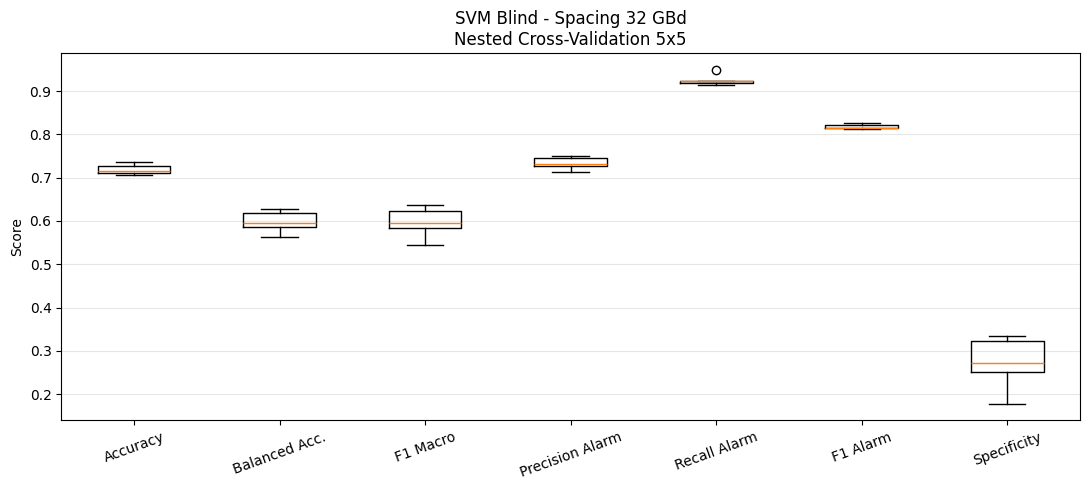


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy                : 0.7188
balanced_accuracy       : 0.5987
f1_macro                : 0.5988
precision_alarm         : 0.7331
recall_alarm            : 0.9255
f1_alarm                : 0.8182
precision_normal        : 0.6280
recall_normal           : 0.2718
f1_normal               : 0.3794
specificity             : 0.2718

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.63      0.27      0.38      2951
      ALARMA       0.73      0.93      0.82      6379

    accuracy                           0.72      9330
   macro avg       0.68      0.60      0.60      9330
weighted avg       0.70      0.72      0.68      9330


Matriz de confusión OOF:
[[ 802 2149]
 [ 475 5904]]


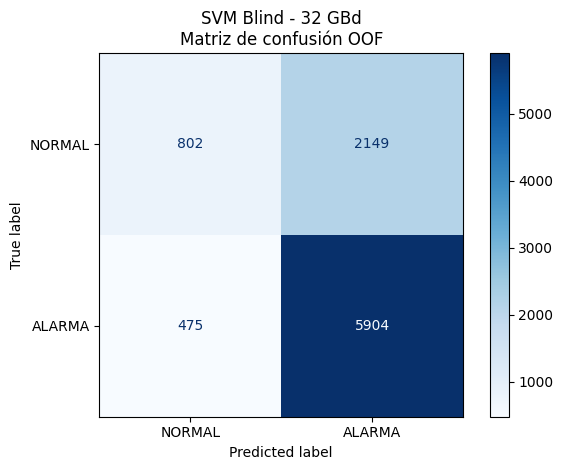

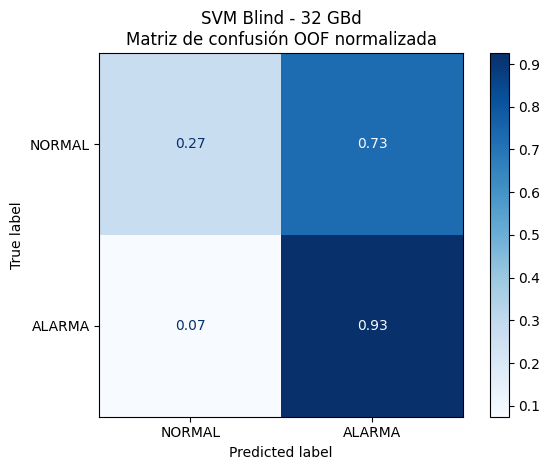


HIPERPARÁMETROS POR OUTER FOLD:
 fold  svm__C svm__gamma svm__kernel  inner_cv_best_f1_alarm  grid_time_s
    1    10.0       0.01         rbf                0.819800    44.771119
    2    10.0       0.01         rbf                0.819335    74.482182
    3     0.1        NaN      linear                0.819534    31.415441
    4     1.0       0.01         rbf                0.820259    37.589745
    5     1.0      scale         rbf                0.817031    77.433747

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 171.998 µs/muestra
Inference Std: 61.963 µs/muestra
Mediciones: 500
Incluye StandardScaler y SVM.predict().
No incluye extracción de características, entrenamiento, Grid Search ni SHAP.

GRID SEARCH FINAL - SVM BLIND
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros finales:
{'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Mejor F1 ALARMA GridSearch final: 0.8186
Tiempo GridSearch final: 57.78 s (0.96 min)

MODELO FINAL:
{'svm

  0%|          | 0/50 [00:00<?, ?it/s]


Tiempo SHAP: 313.80 s (5.23 min)

RANKING SHAP - 30 CARACTERÍSTICAS I/Q
     feature mean_abs_shap importance_percent
Q_broadening      0.065552             30.38%
I_broadening      0.054126             25.08%
   Q_peak2_y      0.015843              7.34%
 Q_valley3_y      0.011135              5.16%
   Q_peak3_y      0.007868              3.65%
   I_peak2_y      0.007130              3.30%
 I_valley1_y      0.006794              3.15%
 Q_valley2_x      0.006519              3.02%
   Q_peak4_y      0.006323              2.93%
   I_peak3_y      0.004816              2.23%
 I_valley3_y      0.004722              2.19%
   Q_peak2_x      0.003541              1.64%
 Q_valley1_y      0.003186              1.48%
   I_peak1_y      0.002668              1.24%
   I_peak4_x      0.002500              1.16%
   I_peak2_x      0.001929              0.89%
   I_peak4_y      0.001794              0.83%
   Q_peak1_x      0.001749              0.81%
   I_peak1_x      0.001442              0.67%
 Q_vall

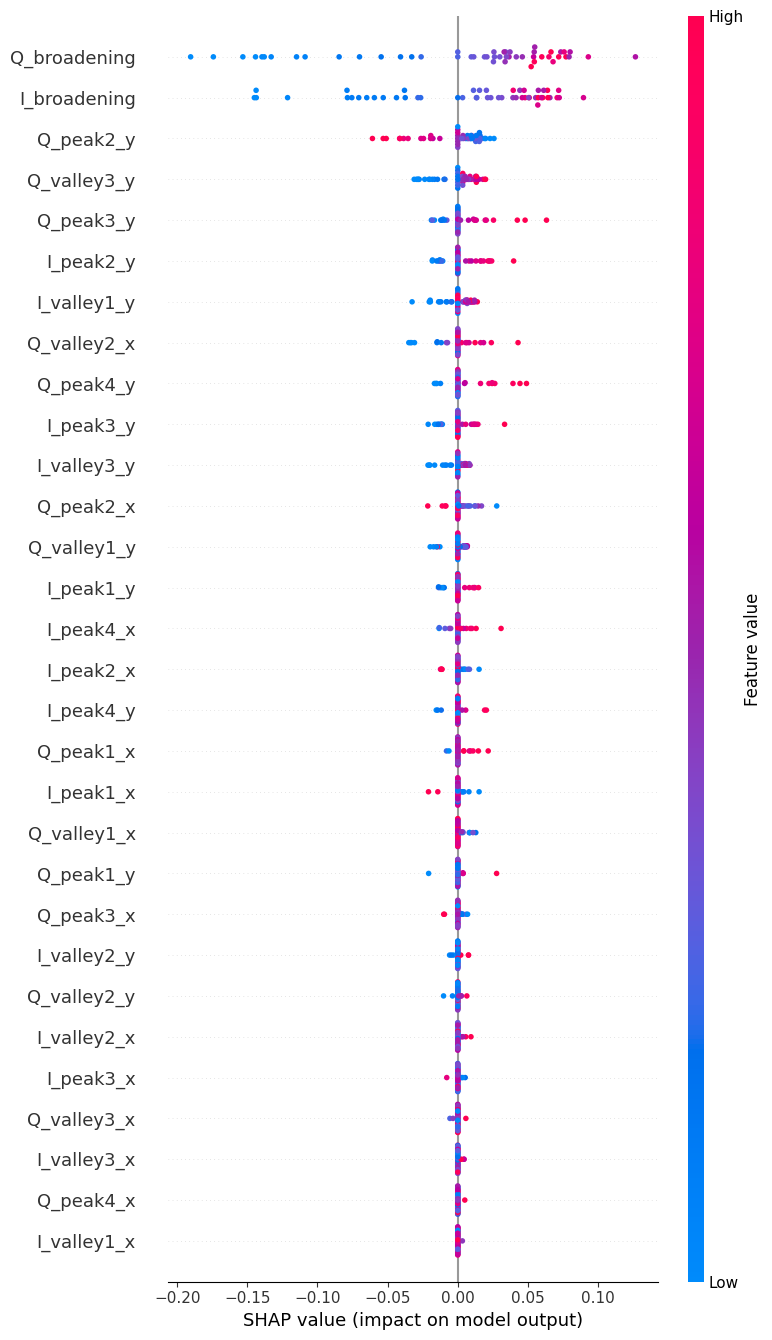

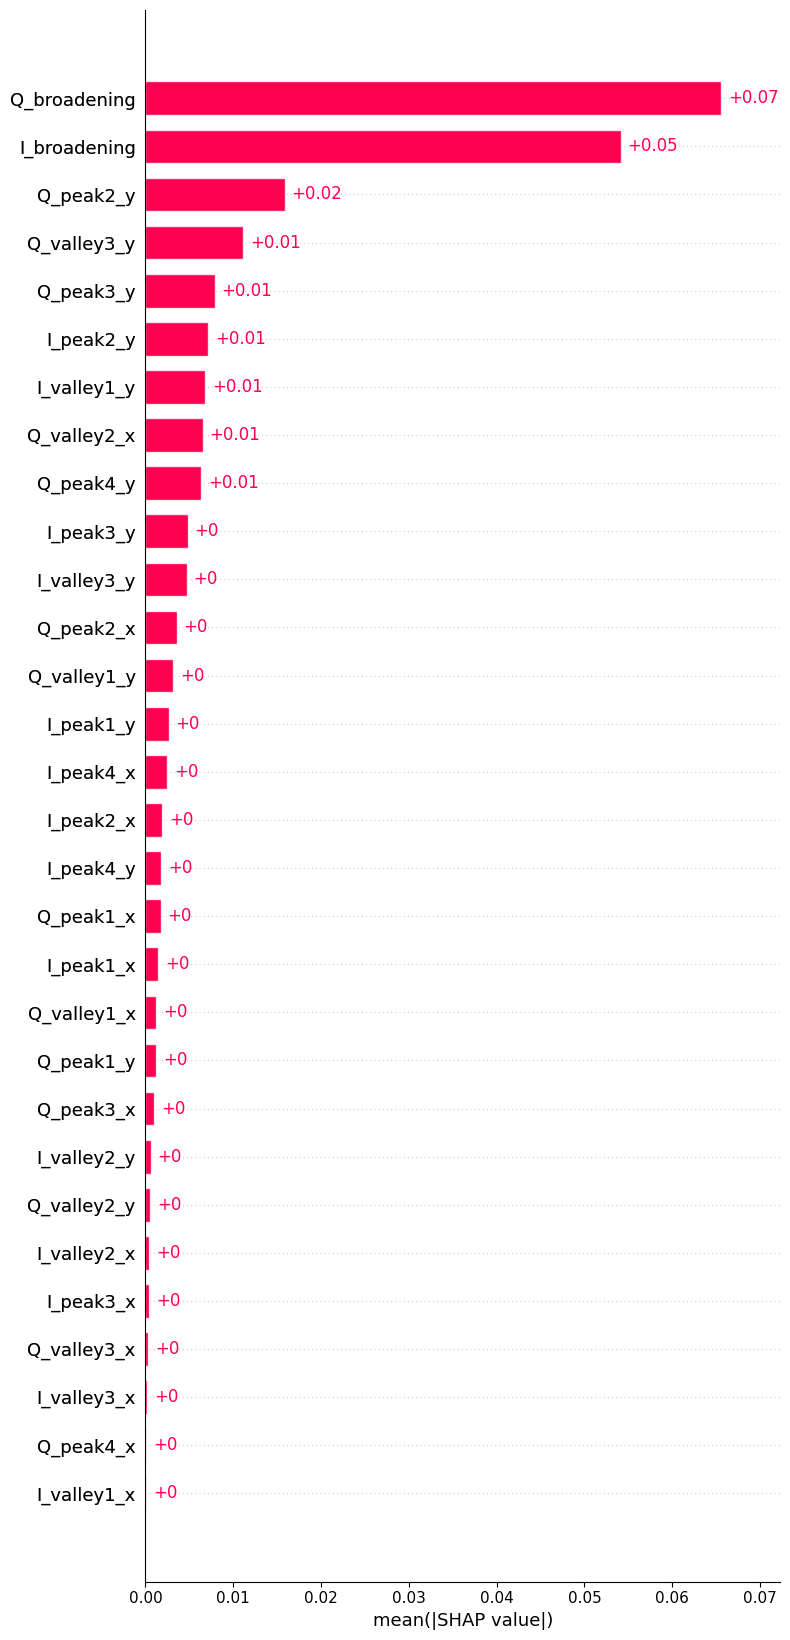

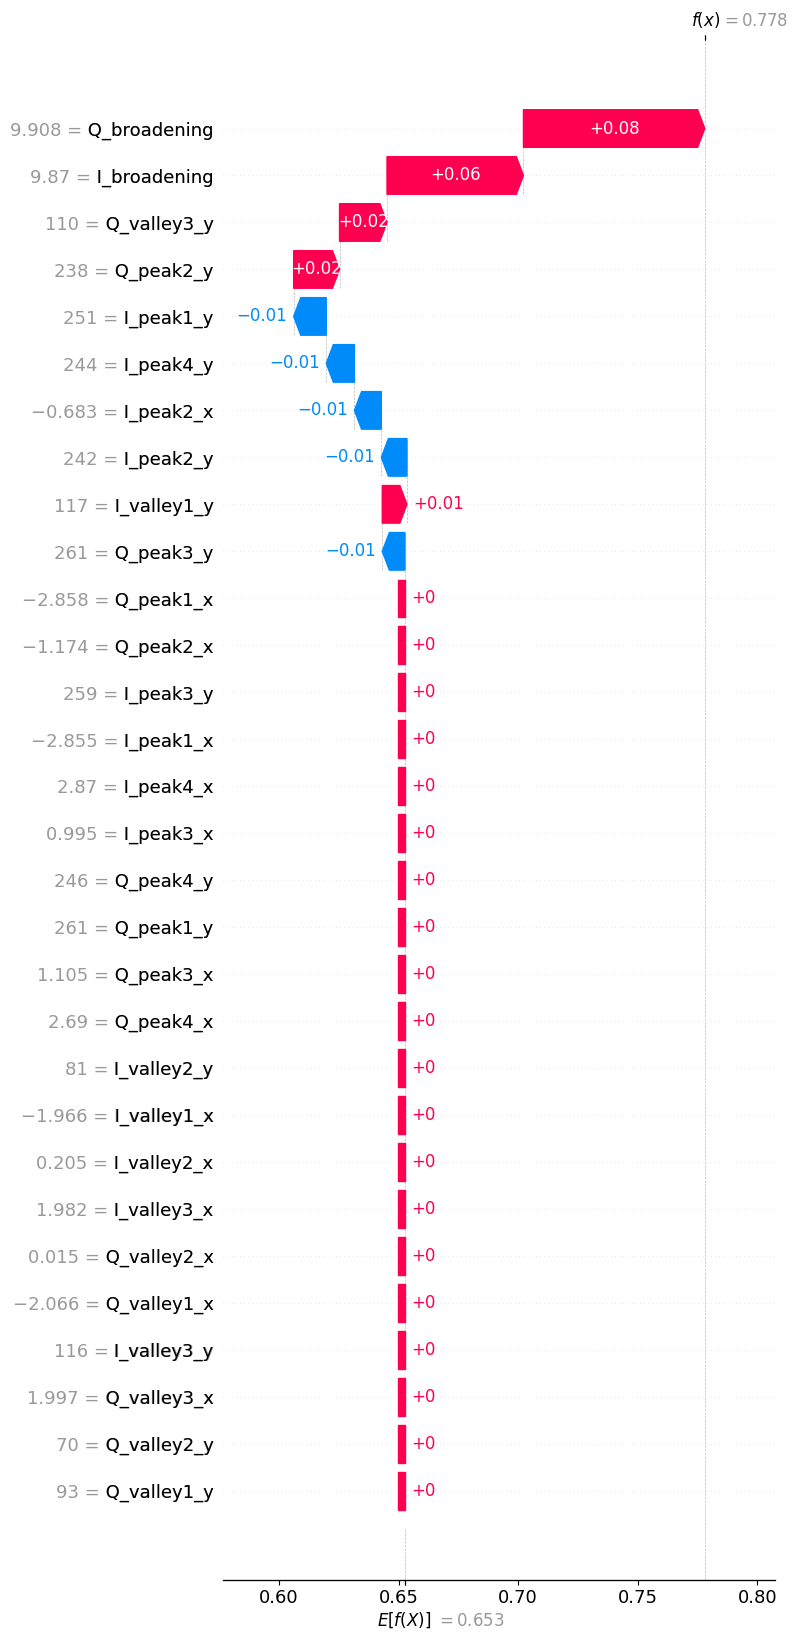


RESUMEN FINAL - SVM BLIND - 32 GBd
NESTED CROSS-VALIDATION 5x5

CARACTERÍSTICAS:
30 I/Q
OSNR excluida
channel_spacing excluido de X

CRITERIO GRID SEARCH:
F1 ALARMA

--- OUTER CV: PROMEDIO ± STD ---
accuracy                : 0.7188 ± 0.0114
balanced_accuracy       : 0.5986 ± 0.0231
f1_macro                : 0.5972 ± 0.0320
precision_alarm         : 0.7335 ± 0.0127
recall_alarm            : 0.9255 ± 0.0121
f1_alarm                : 0.8182 ± 0.0051
precision_normal        : 0.6258 ± 0.0236
recall_normal           : 0.2718 ± 0.0562
f1_normal               : 0.3761 ± 0.0600
specificity             : 0.2718 ± 0.0562

--- MÉTRICAS GLOBALES OOF ---
accuracy                : 0.7188
balanced_accuracy       : 0.5987
f1_macro                : 0.5988
precision_alarm         : 0.7331
recall_alarm            : 0.9255
f1_alarm                : 0.8182
precision_normal        : 0.6280
recall_normal           : 0.2718
f1_normal               : 0.3794
specificity             : 0.2718

--- TIEMPO DE INFE

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

# 32 GBd, roll-off = 0.1
# BW = Rs * (1 + roll-off)
# BW = 32 * 1.1 = 35.2 GHz

THRESHOLD_GHZ = 35.2

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

# Repeticiones para medir tiempo de inferencia
N_REPETITIONS = 100

# Configuración SHAP original
SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 500

OUTPUT_PREFIX = "svm_spacing_32GBd_blind_nested"

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS I/Q
# ============================================================

# MONITOREO CIEGO:
#
# Solo se utilizan las características extraídas
# de los histogramas I/Q.
#
# NO se utiliza OSNR.
# NO se utiliza channel_spacing como predictor.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR EL DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura:
#
# Columnas 0-29: 30 características I/Q
# Columna 30:    channel_spacing
# Columna 31:    OSNR
#
# Total: 32 columnas

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas, "
        f"pero se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 4. DEFINIR X E y
# ============================================================

# Espaciamiento espectral real.
# Se utiliza únicamente para construir el target.

y_spacing = matriz.iloc[:, 30].to_numpy()

# OSNR se conserva solo como metadato.
osnr_values = matriz.iloc[:, 31].to_numpy()

# MONITOREO CIEGO:
# X contiene exclusivamente las primeras 30 columnas.

X = matriz.iloc[:, :30].copy()
X.columns = feature_names

# Etiquetas:
#
# 0 = NORMAL: spacing > 35.2 GHz
# 1 = ALARMA: spacing <= 35.2 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

# Comprobar que hay suficientes muestras
# para las validaciones externa e interna.

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Outer CV."
    )

min_outer_train_class = min(
    int(count - np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para ejecutar Inner CV."
    )

print("\n" + "=" * 70)
print("SVM - SPACING 32 GBd - MONITOREO CIEGO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz original: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print(f"Características utilizadas: {X.shape[1]}")
print(f"OSNR utilizada como entrada: {'OSNR' in X.columns}")

# ============================================================
# 5. FUNCIÓN PARA CONSTRUIR SVM
# ============================================================

def build_svm(probability=False):
    """
    Construye un pipeline nuevo:

        StandardScaler -> SVC

    StandardScaler se ajusta dentro de cada
    partición de entrenamiento.

    De esta manera se evita fuga de información.

    probability=False:
        Se utiliza durante Nested CV y Grid Search.
        Es más rápido y suficiente para calcular F1.

    probability=True:
        Se utiliza solamente en el modelo final
        destinado al análisis SHAP.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            SVC(
                probability=probability,
                random_state=SEED
            )
        )
    ])

# ============================================================
# 6. GRID DE HIPERPARÁMETROS ORIGINAL
# ============================================================

# LINEAL:
#   4 valores de C
#
# RBF:
#   4 valores de C * 4 valores de gamma
#
# TOTAL:
#   4 + 16 = 20 configuraciones

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1, 1]
    }
]

n_combinations = len(
    list(ParameterGrid(param_grid))
)

print("\nCONFIGURACIÓN NESTED CV:")
print(f"Outer folds: {N_OUTER_FOLDS}")
print(f"Inner folds: {N_INNER_FOLDS}")
print(f"Combinaciones Grid Search: {n_combinations}")
print("Scoring: F1 ALARMA")
print("SVM probability=False durante Nested CV")

# ============================================================
# 7. FUNCIÓN PARA CALCULAR MÉTRICAS
# ============================================================

def calculate_metrics(y_true, y_pred):
    """
    Calcula las métricas de clasificación.

    NORMAL = 0
    ALARMA = 1

    Se incluyen:
        Accuracy
        Balanced Accuracy
        F1 Macro
        Precision / Recall / F1 por clase
        Specificity
        TN, FP, FN, TP

    El criterio de optimización es F1 ALARMA.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "precision_alarm": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall_alarm": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1_alarm": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "precision_normal": precision_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "recall_normal": recall_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "f1_normal": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

# ============================================================
# 8. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra tendrá una predicción OOF.
#
# Las predicciones se guardan en las posiciones
# originales de las filas del dataset.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

# SVM probability=False no proporciona predict_proba.
#
# Se guardará decision_function como score continuo.
# Este score NO es una probabilidad.

oof_decision_scores = np.full(
    n_samples,
    np.nan,
    dtype=float
)

oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

nested_start = time.perf_counter()

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE PRINCIPAL OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 OUTER TRAIN Y OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {X_outer_train.shape}")
    print(f"Outer Test:  {X_outer_test.shape}")

    # --------------------------------------------------------
    # 9.2 INNER CROSS-VALIDATION
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    # GridSearchCV recibe solamente OUTER TRAIN.
    #
    # Dentro de cada inner fold:
    #
    # 1. Ajusta StandardScaler con inner train.
    # 2. Entrena SVM con inner train.
    # 3. Evalúa F1 ALARMA con inner validation.
    #
    # Selecciona la mejor configuración.
    #
    # refit=True:
    # reajusta el mejor pipeline con todo outer train.
    #
    # El outer test permanece completamente excluido.

    search = GridSearchCV(
        estimator=build_svm(probability=False),
        param_grid=param_grid,
        scoring="f1",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    best_svm = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 ALARMA Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s "
        f"({grid_time / 60:.2f} min)"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1_alarm": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.4 PREDICCIONES OUTER TEST
    # --------------------------------------------------------

    # Estas muestras nunca se utilizaron
    # para seleccionar hiperparámetros
    # ni entrenar el modelo del fold.

    y_outer_pred = best_svm.predict(
        X_outer_test
    )

    # Score continuo de la SVM.
    #
    # Positivo: tendencia hacia ALARMA.
    # Negativo: tendencia hacia NORMAL.
    #
    # No corresponde a una probabilidad.

    y_outer_scores = best_svm.decision_function(
        X_outer_test
    )

    # Guardar predicciones OOF en el índice original.

    oof_predictions[test_idx] = y_outer_pred
    oof_decision_scores[test_idx] = y_outer_scores
    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.5 MÉTRICAS DEL OUTER FOLD
    # --------------------------------------------------------

    fold_metrics = calculate_metrics(
        y_outer_test,
        y_outer_pred
    )

    # --------------------------------------------------------
    # 9.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Se mide el pipeline completo:
    #
    # X -> StandardScaler -> SVM.predict()
    #
    # NO incluye:
    # - Extracción de características I/Q
    # - Entrenamiento
    # - Grid Search
    # - SHAP

    # Warm-up
    _ = best_svm.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_svm.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        # Tiempo promedio por muestra
        # para la predicción del batch.

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        **fold_metrics,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    for metric, value in fold_metrics.items():

        if metric not in ["tn", "fp", "fn", "tp"]:

            print(
                f"{metric:24s}: {value:.4f}"
            )

    print("\nMatriz de confusión del fold:")

    print(
        confusion_matrix(
            y_outer_test,
            y_outer_pred,
            labels=[0, 1]
        )
    )

    print(
        f"\nInference: "
        f"{inference_mean_us:.3f} ± "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. TIEMPO TOTAL NESTED CV
# ============================================================

nested_time = (
    time.perf_counter() - nested_start
)

print("\n" + "=" * 70)
print("NESTED CROSS-VALIDATION COMPLETADA")
print("=" * 70)

print(
    f"Tiempo total: {nested_time:.2f} s "
    f"({nested_time / 60:.2f} min)"
)

# ============================================================
# 11. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_decision_scores).all():
    raise RuntimeError(
        "Existen decision scores OOF inválidos."
    )

print(
    "\nTodas las muestras tienen "
    "una predicción OOF válida."
)

# ============================================================
# 12. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 13. PROMEDIO ± STD DE LOS OUTER FOLDS
# ============================================================

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "precision_normal",
    "recall_normal",
    "f1_normal",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 14. BOXPLOT OUTER CV
# ============================================================

plot_metrics = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "specificity"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in plot_metrics
    ],
    tick_labels=[
        "Accuracy",
        "Balanced Acc.",
        "F1 Macro",
        "Precision Alarm",
        "Recall Alarm",
        "F1 Alarm",
        "Specificity"
    ]
)

plt.ylabel("Score")

plt.title(
    "SVM Blind - Spacing 32 GBd\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MÉTRICAS GLOBALES OOF
# ============================================================

# Se reúnen las predicciones de los
# cinco outer folds.
#
# Cada muestra fue predicha una sola vez
# por un modelo que nunca la utilizó
# durante entrenamiento.

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "SVM Blind - 32 GBd\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "SVM Blind - 32 GBd\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 18. GUARDAR PREDICCIONES OOF
# ============================================================

# channel_spacing y OSNR se incluyen
# exclusivamente como metadatos.
#
# NO fueron características de entrada.
#
# decision_score:
# salida de decision_function del modelo
# correspondiente a cada outer fold.
#
# NO es una probabilidad.

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": osnr_values,
    "true_class": y,
    "predicted_class": oof_predictions,
    "decision_score": oof_decision_scores,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 19. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 20. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# Se combinan las mediciones de los
# cinco outer folds.
#
# 5 folds * 100 repeticiones
# = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean_us = (
    all_inference_times.mean()
)

inference_std_us = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean_us:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std_us:.3f} µs/muestra"
)

print(
    f"Mediciones: {len(all_inference_times)}"
)

print(
    "Incluye StandardScaler y SVM.predict()."
)

print(
    "No incluye extracción de características, "
    "entrenamiento, Grid Search ni SHAP."
)

# ============================================================
# 21. GRID SEARCH FINAL SOBRE TODO EL DATASET
# ============================================================

# Para SHAP se seleccionan los hiperparámetros
# utilizando todas las muestras.
#
# Este procedimiento es independiente
# de las predicciones OOF anteriores.
#
# El mejor F1 de este GridSearchCV NO debe
# presentarse como rendimiento Nested CV.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - SVM BLIND")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_svm(probability=False),
    param_grid=param_grid,
    scoring="f1",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

print("\nMejores hiperparámetros finales:")
print(final_best_params)

print(
    f"Mejor F1 ALARMA GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s "
    f"({final_grid_time / 60:.2f} min)"
)

# ============================================================
# 22. ENTRENAR SVM FINAL CON PROBABILITY=True
# ============================================================

# Durante Nested CV se utilizó:
#
# probability=False
#
# Para explicar probabilidades con SHAP:
#
# probability=True
#
# Se crea un pipeline nuevo con los mejores
# hiperparámetros encontrados sobre todo X.
#
# Esta calibración probabilística es interna
# a SVC y NO forma parte de la evaluación OOF.

final_svm = build_svm(
    probability=True
)

final_svm.set_params(
    **final_best_params
)

final_train_start = time.perf_counter()

final_svm.fit(X, y)

final_train_time = (
    time.perf_counter() - final_train_start
)

print("\nMODELO FINAL:")

print(final_best_params)

print(
    f"Tiempo entrenamiento final: "
    f"{final_train_time:.3f} s"
)

# ============================================================
# 23. SHAP - KERNELEXPLAINER
# ============================================================

# Se explica:
#
# P(ALARMA | 30 características I/Q)
#
# SHAP positivo:
# aumenta la probabilidad estimada de ALARMA.
#
# SHAP negativo:
# disminuye la probabilidad estimada de ALARMA.
#
# Se explica el modelo final entrenado
# sobre todo el dataset.
#
# Este análisis SHAP NO es OOF.

print("\n" + "=" * 70)
print("SHAP - SVM BLIND - 32 GBd")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

print(f"SHAP nsamples: {SHAP_NSAMPLES}")

# ------------------------------------------------------------
# 23.1 FUNCIÓN PARA SHAP
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe las 30 características I/Q.

    Devuelve:
        P(ALARMA) = P(clase 1)

    Se utiliza el modelo final con
    probability=True.
    """

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_svm.predict_proba(data)[:, 1]

# ------------------------------------------------------------
# 23.2 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw_shap = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = (
    time.perf_counter() - shap_start
)

shap_values = np.asarray(raw_shap)

# Compatibilidad con salidas SHAP
# que tienen dimensión final de tamaño 1.

if (
    shap_values.ndim == 3
    and shap_values.shape[-1] == 1
):

    shap_values = shap_values[:, :, 0]

if shap_values.shape != explained.shape:

    raise ValueError(
        f"Forma SHAP inesperada: {shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

base_alarm = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 24. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 30 CARACTERÍSTICAS I/Q")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 CARACTERÍSTICAS:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 25. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 26. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 29. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - SVM BLIND - 32 GBd")
print("NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

print("\nCARACTERÍSTICAS:")
print("30 I/Q")
print("OSNR excluida")
print("channel_spacing excluido de X")

print("\nCRITERIO GRID SEARCH:")
print("F1 ALARMA")

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean_us:.3f} "
    f"± {inference_std_us:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print(final_best_params)

print(
    f"F1 ALARMA GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

print(
    f"Tiempo entrenamiento final: "
    f"{final_train_time:.3f} s"
)

print("\n--- SHAP ---")

print(f"Tiempo SHAP: {shap_time:.2f} s")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")


## KNN 32GBd para clasificar SEPARACIÓN ESPECTRAL SIN OSNR


KNN - SPACING 32 GBd - MONITOREO CIEGO
Dataset: matriz32GBd_clasifi_correct.csv
Forma matriz original: (9330, 32)
Forma X: (9330, 30)
Total muestras: 9330
NORMAL (> 35.2 GHz): 2951
ALARMA (<= 35.2 GHz): 6379
Características utilizadas: 30
OSNR utilizada como entrada: False

CONFIGURACIÓN NESTED CV:
Outer folds: 5
Inner folds: 5
Combinaciones: 84
Scoring GridSearchCV: F1 MACRO

INICIANDO NESTED CROSS-VALIDATION 5x5

OUTER FOLD 1/5
Outer Train: (7464, 30)
Outer Test:  (1866, 30)
Fitting 5 folds for each of 84 candidates, totalling 420 fits

Mejores parámetros:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'uniform'}
Mejor F1 Macro Inner CV: 0.6216
Tiempo GridSearchCV: 2.13 s (0.04 min)

MÉTRICAS OUTER FOLD:
accuracy                : 0.6951
balanced_accuracy       : 0.5998
f1_macro                : 0.6040
precision_alarm         : 0.7380
recall_alarm            : 0.8589
f1_alarm                : 0.7939
precision_normal        : 0.5276
recall_normal    

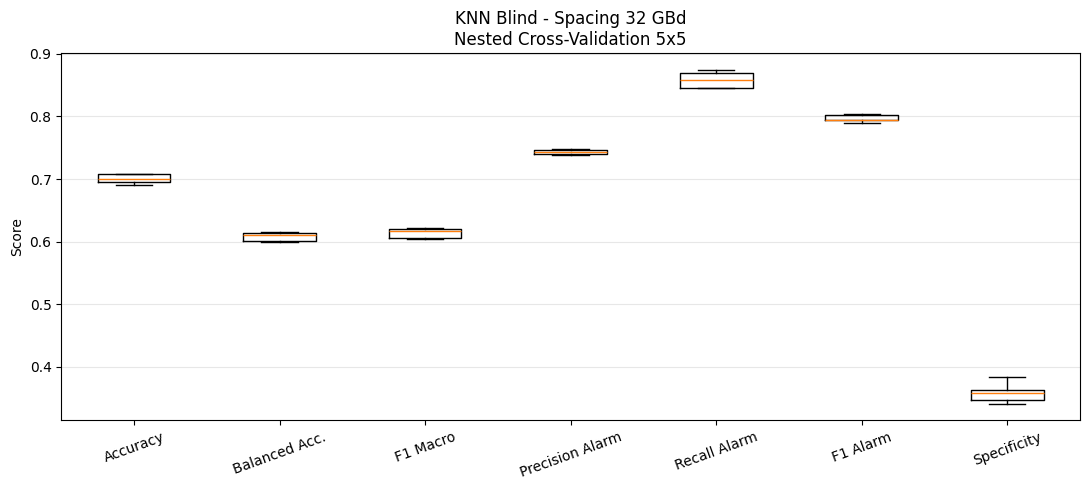


MÉTRICAS GLOBALES OUT-OF-FOLD
accuracy                : 0.7003
balanced_accuracy       : 0.6084
f1_macro                : 0.6136
precision_alarm         : 0.7430
recall_alarm            : 0.8586
f1_alarm                : 0.7967
precision_normal        : 0.5396
recall_normal           : 0.3582
f1_normal               : 0.4305
specificity             : 0.3582

CLASSIFICATION REPORT OOF:
              precision    recall  f1-score   support

      NORMAL       0.54      0.36      0.43      2951
      ALARMA       0.74      0.86      0.80      6379

    accuracy                           0.70      9330
   macro avg       0.64      0.61      0.61      9330
weighted avg       0.68      0.70      0.68      9330


Matriz de confusión OOF:
[[1057 1894]
 [ 902 5477]]


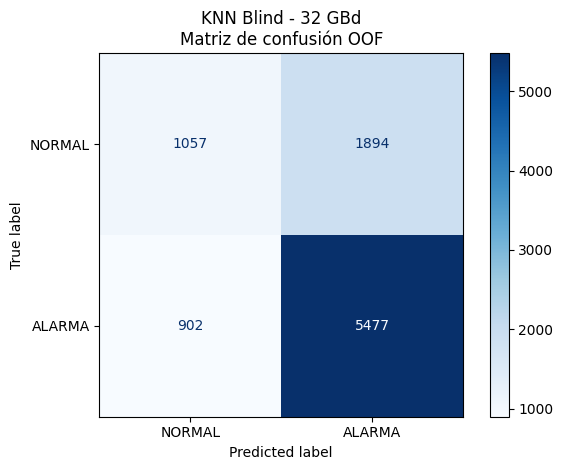

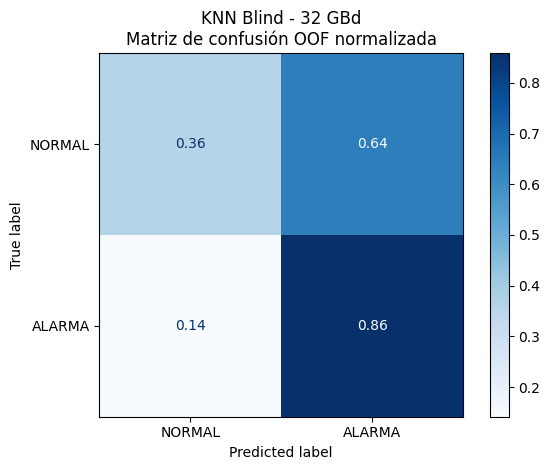


HIPERPARÁMETROS POR OUTER FOLD:
 fold knn__metric  knn__n_neighbors  knn__p knn__weights  inner_cv_best_f1_macro  grid_time_s
    1   manhattan                15       1      uniform                0.621624     2.131045
    2   manhattan                 9       1      uniform                0.617800     1.265363
    3   manhattan                21       1     distance                0.621400     1.247538
    4   manhattan                21       1     distance                0.614706     1.214849
    5   manhattan                15       1     distance                0.609013     1.218073

TIEMPO DE INFERENCIA - OUTER CV
Inference Mean: 10.815 µs/muestra
Inference Std: 1.138 µs/muestra
Mediciones: 500
Incluye StandardScaler y KNN.predict().
No incluye extracción de características, entrenamiento, Grid Search ni SHAP.

GRID SEARCH FINAL - KNN BLIND
Fitting 5 folds for each of 84 candidates, totalling 420 fits

Mejores hiperparámetros finales:
{'knn__metric': 'manhattan', 'knn__n_neighb

  0%|          | 0/50 [00:00<?, ?it/s]


Tiempo SHAP: 9.09 s (0.15 min)

RANKING SHAP - 30 CARACTERÍSTICAS I/Q
     feature mean_abs_shap importance_percent
Q_broadening      0.027322             13.21%
I_broadening      0.026949             13.03%
 I_valley1_y      0.012087              5.84%
 Q_valley1_y      0.010377              5.02%
 I_valley2_y      0.009950              4.81%
 Q_valley3_y      0.009253              4.47%
 Q_valley2_y      0.009149              4.42%
 I_valley3_y      0.006916              3.34%
 I_valley2_x      0.006819              3.30%
 Q_valley2_x      0.006808              3.29%
   Q_peak4_y      0.006156              2.98%
   I_peak4_x      0.005648              2.73%
   I_peak1_x      0.005399              2.61%
   Q_peak1_x      0.005323              2.57%
 Q_valley1_x      0.005159              2.49%
   Q_peak2_y      0.005098              2.47%
   I_peak1_y      0.004868              2.35%
 I_valley1_x      0.004304              2.08%
   I_peak2_x      0.004139              2.00%
   Q_peak

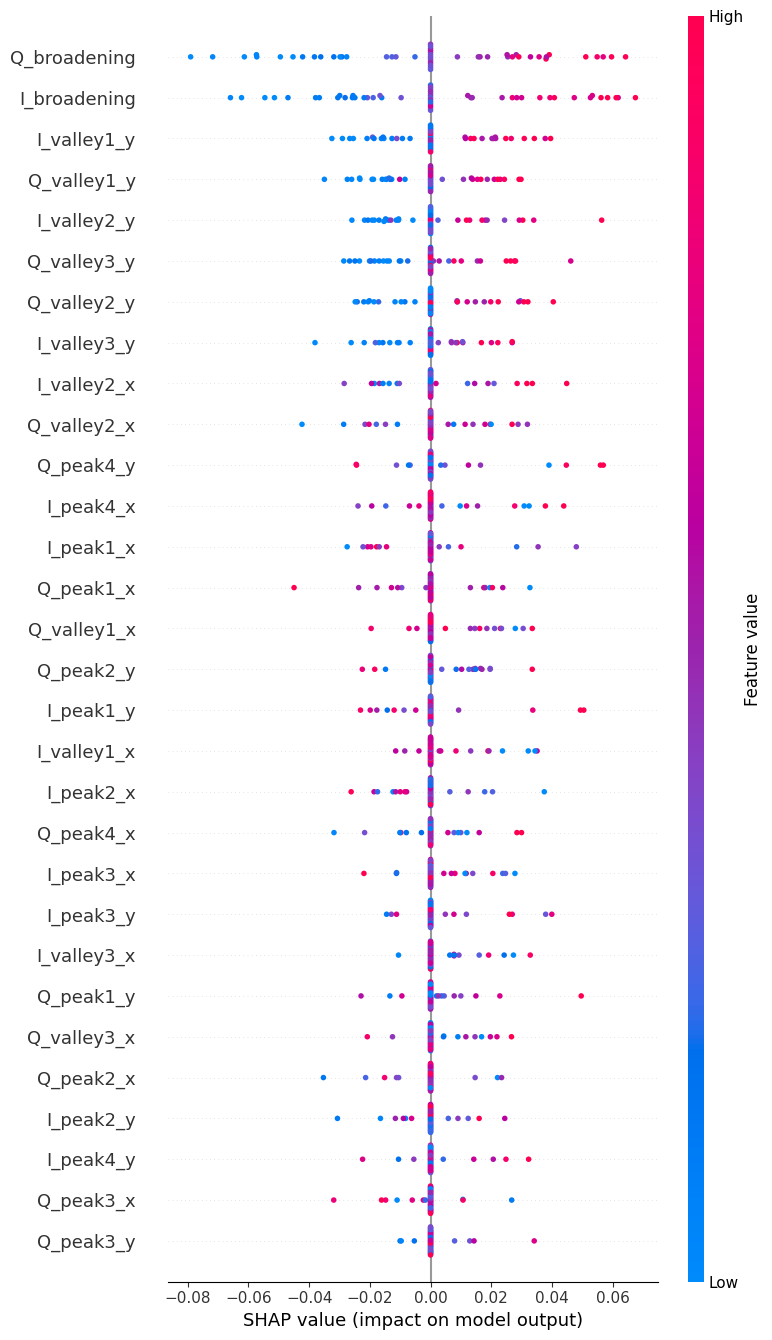

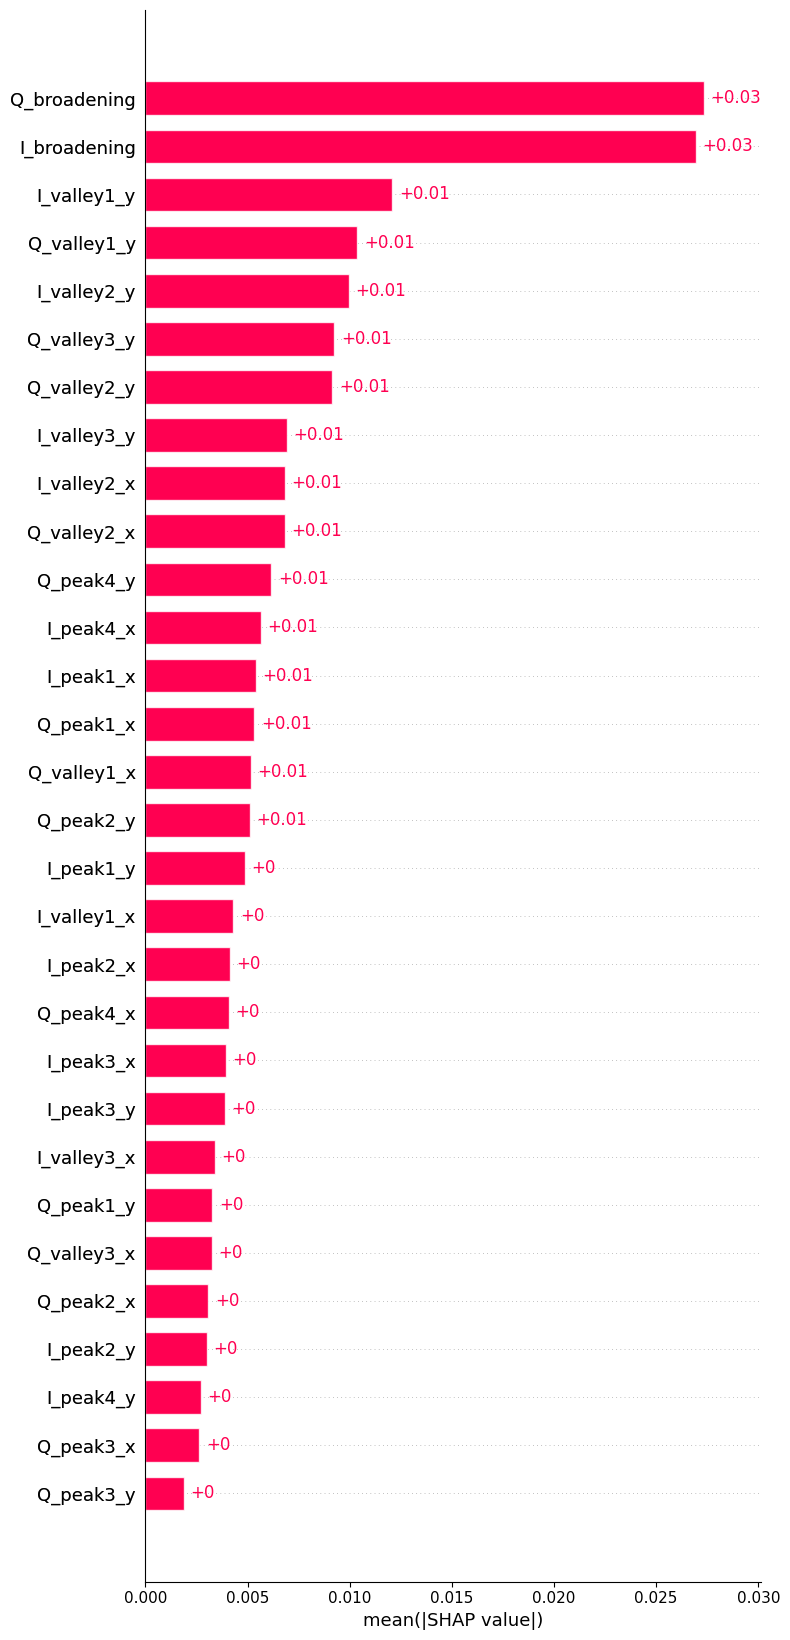

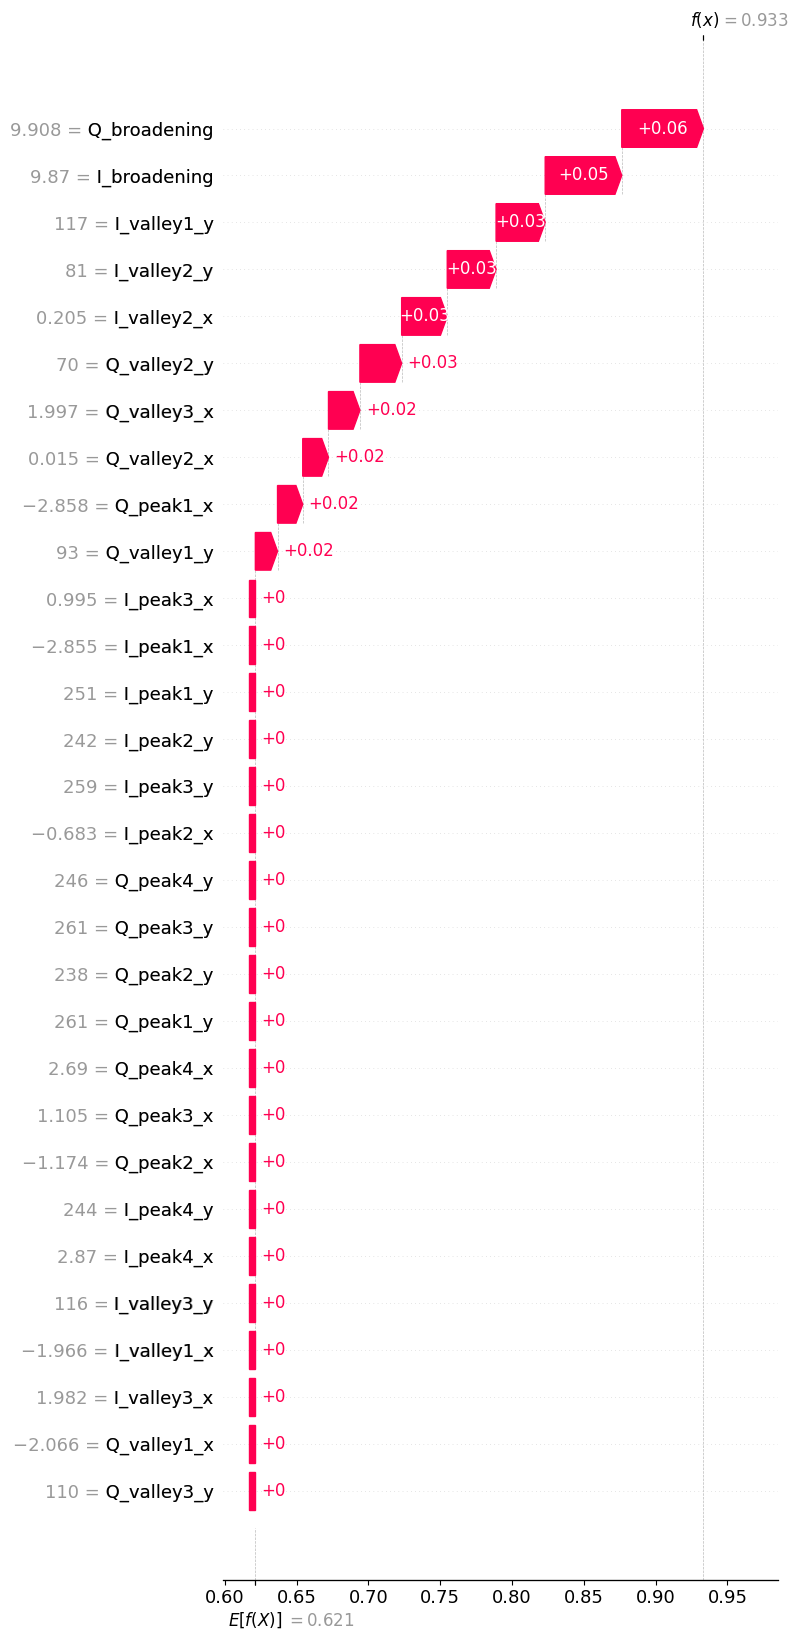


RESUMEN FINAL - KNN BLIND - 32 GBd
NESTED CROSS-VALIDATION 5x5

CARACTERÍSTICAS:
30 I/Q
OSNR excluida
channel_spacing excluido de X

CRITERIO GRID SEARCH:
F1 MACRO

--- OUTER CV: PROMEDIO ± STD ---
accuracy                : 0.7003 ± 0.0070
balanced_accuracy       : 0.6084 ± 0.0066
f1_macro                : 0.6135 ± 0.0073
precision_alarm         : 0.7431 ± 0.0037
recall_alarm            : 0.8586 ± 0.0120
f1_alarm                : 0.7966 ± 0.0058
precision_normal        : 0.5402 ± 0.0185
recall_normal           : 0.3582 ± 0.0145
f1_normal               : 0.4305 ± 0.0117
specificity             : 0.3582 ± 0.0145

--- MÉTRICAS GLOBALES OOF ---
accuracy                : 0.7003
balanced_accuracy       : 0.6084
f1_macro                : 0.6136
precision_alarm         : 0.7430
recall_alarm            : 0.8586
f1_alarm                : 0.7967
precision_normal        : 0.5396
recall_normal           : 0.3582
f1_normal               : 0.4305
specificity             : 0.3582

--- TIEMPO DE INFER

In [ ]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

CSV_PATH = "matriz32GBd_clasifi_correct.csv"

# 32 GBd, roll-off = 0.1
# BW = Rs * (1 + roll-off)
# BW = 32 * 1.1 = 35.2 GHz

THRESHOLD_GHZ = 35.2

SEED = 42

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

N_REPETITIONS = 100

SHAP_BACKGROUND = 50
SHAP_EXPLAIN = 50
SHAP_NSAMPLES = 500

OUTPUT_PREFIX = "knn_spacing_32GBd_blind_nested"

# ============================================================
# 2. NOMBRES DE LAS 30 CARACTERÍSTICAS I/Q
# ============================================================

# MONITOREO CIEGO:
#
# Se utilizan únicamente las 30 características
# extraídas de los histogramas I/Q.
#
# NO se utiliza OSNR como predictor.
# NO se utiliza channel_spacing como predictor.

feature_names = (
    [f"I_peak{k}_x" for k in range(1, 5)] +
    [f"I_peak{k}_y" for k in range(1, 5)] +
    [f"Q_peak{k}_x" for k in range(1, 5)] +
    [f"Q_peak{k}_y" for k in range(1, 5)] +
    [f"I_valley{k}_x" for k in range(1, 4)] +
    [f"I_valley{k}_y" for k in range(1, 4)] +
    [f"Q_valley{k}_x" for k in range(1, 4)] +
    [f"Q_valley{k}_y" for k in range(1, 4)] +
    ["I_broadening", "Q_broadening"]
)

assert len(feature_names) == 30

# ============================================================
# 3. CARGAR Y VALIDAR DATASET
# ============================================================

matriz = pd.read_csv(
    CSV_PATH,
    header=None
)

# Estructura esperada:
#
# Columnas 0-29: 30 características I/Q
# Columna 30:    channel_spacing
# Columna 31:    OSNR
#
# Total: 32 columnas.

if matriz.shape[1] != 32:
    raise ValueError(
        f"Se esperaban 32 columnas, "
        f"pero se encontraron {matriz.shape[1]}"
    )

matriz = matriz.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(matriz.to_numpy()).all():
    raise ValueError(
        "El CSV contiene NaN o infinitos."
    )

# ============================================================
# 4. DEFINIR X E y
# ============================================================

# Espaciamiento real:
# Se utiliza únicamente para generar las etiquetas.

y_spacing = matriz.iloc[:, 30].to_numpy()

# OSNR se conserva solo como metadato
# para el archivo de predicciones OOF.

osnr_values = matriz.iloc[:, 31].to_numpy()

# MONITOREO CIEGO:
# Solo las primeras 30 columnas.

X = matriz.iloc[:, :30].copy()
X.columns = feature_names

# Clases:
#
# 0 = NORMAL -> spacing > 35.2 GHz
# 1 = ALARMA -> spacing <= 35.2 GHz

y = (
    y_spacing <= THRESHOLD_GHZ
).astype(int)

n_samples = len(y)

class_counts = np.bincount(
    y,
    minlength=2
)

if class_counts.min() < N_OUTER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para Outer CV."
    )

# Comprobar que los outer train permiten
# ejecutar los cinco inner folds.

min_outer_train_class = min(
    int(count - np.ceil(count / N_OUTER_FOLDS))
    for count in class_counts
)

if min_outer_train_class < N_INNER_FOLDS:
    raise ValueError(
        "No hay suficientes muestras por clase "
        "para Inner CV."
    )

print("\n" + "=" * 70)
print("KNN - SPACING 32 GBd - MONITOREO CIEGO")
print("=" * 70)

print(f"Dataset: {CSV_PATH}")
print(f"Forma matriz original: {matriz.shape}")
print(f"Forma X: {X.shape}")
print(f"Total muestras: {n_samples}")

print(
    f"NORMAL (> {THRESHOLD_GHZ} GHz): "
    f"{class_counts[0]}"
)

print(
    f"ALARMA (<= {THRESHOLD_GHZ} GHz): "
    f"{class_counts[1]}"
)

print(f"Características utilizadas: {X.shape[1]}")
print(f"OSNR utilizada como entrada: {'OSNR' in X.columns}")

# ============================================================
# 5. PIPELINE KNN
# ============================================================

def build_knn():
    """
    Construye un pipeline nuevo:

        StandardScaler -> KNeighborsClassifier

    StandardScaler se ajusta exclusivamente
    con los datos de entrenamiento.

    Esto evita fuga de información desde
    las particiones de validación y test.

    Es importante para KNN porque el algoritmo
    utiliza distancias entre las muestras.
    """

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ])

# ============================================================
# 6. GRID DE HIPERPARÁMETROS ORIGINAL
# ============================================================

# Se conservan los parámetros originales:
#
# 7 valores de n_neighbors
# 2 tipos de weights
# 3 métricas
# 2 valores de p
#
# Total: 7 * 2 * 3 * 2 = 84 combinaciones.
#
# Algunas combinaciones son equivalentes
# porque el parámetro p no modifica
# las métricas euclidean y manhattan.

param_grid = {
    "knn__n_neighbors": [
        3, 5, 7, 9, 11, 15, 21
    ],
    "knn__weights": [
        "uniform", "distance"
    ],
    "knn__metric": [
        "euclidean", "manhattan", "minkowski"
    ],
    "knn__p": [
        1, 2
    ]
}

n_combinations = len(
    list(ParameterGrid(param_grid))
)

print("\nCONFIGURACIÓN NESTED CV:")
print(f"Outer folds: {N_OUTER_FOLDS}")
print(f"Inner folds: {N_INNER_FOLDS}")
print(f"Combinaciones: {n_combinations}")
print("Scoring GridSearchCV: F1 MACRO")

# ============================================================
# 7. FUNCIÓN PARA CALCULAR MÉTRICAS
# ============================================================

def calculate_metrics(y_true, y_pred):
    """
    Calcula las métricas de clasificación.

    NORMAL = 0
    ALARMA = 1

    Incluye:
    - Accuracy
    - Balanced Accuracy
    - F1 Macro
    - Precision / Recall / F1 ALARMA
    - Precision / Recall / F1 NORMAL
    - Specificity
    - TN, FP, FN, TP
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "precision_alarm": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall_alarm": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1_alarm": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "precision_normal": precision_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "recall_normal": recall_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "f1_normal": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

# ============================================================
# 8. CONFIGURAR OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Cada muestra recibirá exactamente una
# predicción OOF de un modelo que nunca
# la utilizó durante su entrenamiento.

oof_predictions = np.full(
    n_samples,
    -1,
    dtype=int
)

oof_probabilities = np.full(
    n_samples,
    np.nan,
    dtype=float
)

oof_fold = np.full(
    n_samples,
    -1,
    dtype=int
)

outer_results = []
outer_best_params = []
outer_inference_times = []

nested_start = time.perf_counter()

print("\n" + "=" * 70)
print("INICIANDO NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

# ============================================================
# 9. BUCLE PRINCIPAL: OUTER CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "=" * 70)
    print(f"OUTER FOLD {fold}/{N_OUTER_FOLDS}")
    print("=" * 70)

    # --------------------------------------------------------
    # 9.1 OUTER TRAIN / OUTER TEST
    # --------------------------------------------------------

    X_outer_train = X.iloc[train_idx]
    X_outer_test = X.iloc[test_idx]

    y_outer_train = y[train_idx]
    y_outer_test = y[test_idx]

    print(f"Outer Train: {X_outer_train.shape}")
    print(f"Outer Test:  {X_outer_test.shape}")

    # --------------------------------------------------------
    # 9.2 INNER CROSS-VALIDATION
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=N_INNER_FOLDS,
        shuffle=True,
        random_state=SEED + fold
    )

    # --------------------------------------------------------
    # 9.3 GRID SEARCH INTERNO
    # --------------------------------------------------------

    # Solo se utiliza OUTER TRAIN.
    #
    # Dentro de cada inner fold:
    #
    # 1. Ajustar StandardScaler con inner train.
    # 2. Entrenar KNN con inner train.
    # 3. Evaluar F1 Macro en inner validation.
    #
    # Se seleccionan los mejores parámetros.
    #
    # refit=True:
    # reajusta el pipeline sobre todo outer train.
    #
    # Outer test permanece completamente excluido.

    search = GridSearchCV(
        estimator=build_knn(),
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        verbose=1
    )

    grid_start = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train
    )

    grid_time = (
        time.perf_counter() - grid_start
    )

    best_knn = search.best_estimator_

    print("\nMejores parámetros:")
    print(search.best_params_)

    print(
        f"Mejor F1 Macro Inner CV: "
        f"{search.best_score_:.4f}"
    )

    print(
        f"Tiempo GridSearchCV: "
        f"{grid_time:.2f} s "
        f"({grid_time / 60:.2f} min)"
    )

    outer_best_params.append({
        "fold": fold,
        **search.best_params_,
        "inner_cv_best_f1_macro": search.best_score_,
        "grid_time_s": grid_time
    })

    # --------------------------------------------------------
    # 9.4 PREDICCIONES OUTER TEST
    # --------------------------------------------------------

    # Cada muestra de outer test es nueva
    # para el modelo seleccionado en ese fold.

    y_outer_pred = best_knn.predict(
        X_outer_test
    )

    # Probabilidad estimada de ALARMA = clase 1.

    y_outer_proba = best_knn.predict_proba(
        X_outer_test
    )[:, 1]

    # Guardar las predicciones en las
    # posiciones originales del dataset.

    oof_predictions[test_idx] = y_outer_pred
    oof_probabilities[test_idx] = y_outer_proba
    oof_fold[test_idx] = fold

    # --------------------------------------------------------
    # 9.5 MÉTRICAS OUTER FOLD
    # --------------------------------------------------------

    fold_metrics = calculate_metrics(
        y_outer_test,
        y_outer_pred
    )

    # --------------------------------------------------------
    # 9.6 TIEMPO DE INFERENCIA
    # --------------------------------------------------------

    # Se mide el pipeline completo:
    #
    # X -> StandardScaler -> KNN.predict()
    #
    # No incluye extracción de características,
    # entrenamiento, Grid Search ni SHAP.

    # Warm-up

    _ = best_knn.predict(
        X_outer_test.iloc[
            :min(10, len(X_outer_test))
        ]
    )

    inference_times = np.empty(
        N_REPETITIONS
    )

    for rep in range(N_REPETITIONS):

        start = time.perf_counter()

        _ = best_knn.predict(
            X_outer_test
        )

        elapsed = (
            time.perf_counter() - start
        )

        inference_times[rep] = (
            elapsed / len(X_outer_test)
        )

    inference_mean_us = (
        inference_times.mean() * 1e6
    )

    inference_std_us = (
        inference_times.std() * 1e6
    )

    outer_inference_times.append(
        inference_times * 1e6
    )

    # --------------------------------------------------------
    # 9.7 GUARDAR RESULTADOS DEL FOLD
    # --------------------------------------------------------

    outer_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        **fold_metrics,
        "inference_mean_us": inference_mean_us,
        "inference_std_us": inference_std_us,
        "grid_time_s": grid_time
    })

    print("\nMÉTRICAS OUTER FOLD:")

    for metric, value in fold_metrics.items():

        if metric not in ["tn", "fp", "fn", "tp"]:

            print(
                f"{metric:24s}: {value:.4f}"
            )

    print("\nMatriz de confusión del fold:")

    print(
        confusion_matrix(
            y_outer_test,
            y_outer_pred,
            labels=[0, 1]
        )
    )

    print(
        f"\nInference: "
        f"{inference_mean_us:.3f} ± "
        f"{inference_std_us:.3f} µs/muestra"
    )

# ============================================================
# 10. TIEMPO TOTAL NESTED CV
# ============================================================

nested_time = (
    time.perf_counter() - nested_start
)

print("\n" + "=" * 70)
print("NESTED CROSS-VALIDATION COMPLETADA")
print("=" * 70)

print(
    f"Tiempo total: {nested_time:.2f} s "
    f"({nested_time / 60:.2f} min)"
)

# ============================================================
# 11. VERIFICAR PREDICCIONES OOF
# ============================================================

if np.any(oof_predictions == -1):
    raise RuntimeError(
        "Existen muestras sin predicción OOF."
    )

if np.any(oof_fold == -1):
    raise RuntimeError(
        "Existen muestras sin outer fold."
    )

if not np.isfinite(oof_probabilities).all():
    raise RuntimeError(
        "Existen probabilidades OOF inválidas."
    )

print(
    "\nTodas las muestras tienen "
    "una predicción OOF válida."
)

# ============================================================
# 12. RESULTADOS POR OUTER FOLD
# ============================================================

results_df = pd.DataFrame(
    outer_results
)

print("\n" + "=" * 70)
print("RESULTADOS DE LOS CINCO OUTER FOLDS")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

results_df.to_csv(
    f"{OUTPUT_PREFIX}_outer_folds.csv",
    index=False
)

# ============================================================
# 13. PROMEDIO ± STD DE LOS OUTER FOLDS
# ============================================================

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "precision_normal",
    "recall_normal",
    "f1_normal",
    "specificity"
]

print("\n" + "=" * 70)
print("OUTER CV - PROMEDIO ± DESVIACIÓN ESTÁNDAR")
print("=" * 70)

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

# ============================================================
# 14. BOXPLOT OUTER CV
# ============================================================

plot_metrics = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro",
    "precision_alarm",
    "recall_alarm",
    "f1_alarm",
    "specificity"
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    [
        results_df[metric].values
        for metric in plot_metrics
    ],
    tick_labels=[
        "Accuracy",
        "Balanced Acc.",
        "F1 Macro",
        "Precision Alarm",
        "Recall Alarm",
        "F1 Alarm",
        "Specificity"
    ]
)

plt.ylabel("Score")

plt.title(
    "KNN Blind - Spacing 32 GBd\n"
    "Nested Cross-Validation 5x5"
)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 15. MÉTRICAS GLOBALES OOF
# ============================================================

# Cada muestra fue evaluada exactamente una vez
# utilizando un modelo que nunca la vio
# durante entrenamiento.

oof_metrics = calculate_metrics(
    y,
    oof_predictions
)

print("\n" + "=" * 70)
print("MÉTRICAS GLOBALES OUT-OF-FOLD")
print("=" * 70)

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\nCLASSIFICATION REPORT OOF:")

print(
    classification_report(
        y,
        oof_predictions,
        labels=[0, 1],
        target_names=["NORMAL", "ALARMA"],
        zero_division=0
    )
)

# ============================================================
# 16. MATRIZ DE CONFUSIÓN OOF ABSOLUTA
# ============================================================

cm_oof = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1]
)

print("\nMatriz de confusión OOF:")
print(cm_oof)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "KNN Blind - 32 GBd\n"
    "Matriz de confusión OOF"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 17. MATRIZ DE CONFUSIÓN OOF NORMALIZADA
# ============================================================

cm_oof_norm = confusion_matrix(
    y,
    oof_predictions,
    labels=[0, 1],
    normalize="true"
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_oof_norm,
    display_labels=["NORMAL", "ALARMA"]
).plot(
    cmap="Blues",
    values_format=".2f"
)

plt.title(
    "KNN Blind - 32 GBd\n"
    "Matriz de confusión OOF normalizada"
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 18. GUARDAR PREDICCIONES OOF
# ============================================================

# OSNR y channel_spacing aparecen
# únicamente como metadatos.
#
# No fueron utilizados para entrenar KNN.

oof_df = pd.DataFrame({
    "sample_index": np.arange(n_samples),
    "outer_fold": oof_fold,
    "channel_spacing_GHz": y_spacing,
    "OSNR_dB": osnr_values,
    "true_class": y,
    "predicted_class": oof_predictions,
    "probability_alarm": oof_probabilities,
    "correct": y == oof_predictions
})

oof_df.to_csv(
    f"{OUTPUT_PREFIX}_oof_predictions.csv",
    index=False
)

# ============================================================
# 19. HIPERPARÁMETROS POR OUTER FOLD
# ============================================================

params_df = pd.DataFrame(
    outer_best_params
)

print("\nHIPERPARÁMETROS POR OUTER FOLD:")

print(
    params_df.to_string(index=False)
)

params_df.to_csv(
    f"{OUTPUT_PREFIX}_best_params.csv",
    index=False
)

# ============================================================
# 20. TIEMPO DE INFERENCIA OUTER CV
# ============================================================

# 5 folds * 100 repeticiones
# = 500 mediciones.

all_inference_times = np.concatenate(
    outer_inference_times
)

inference_mean_us = (
    all_inference_times.mean()
)

inference_std_us = (
    all_inference_times.std()
)

print("\n" + "=" * 70)
print("TIEMPO DE INFERENCIA - OUTER CV")
print("=" * 70)

print(
    f"Inference Mean: "
    f"{inference_mean_us:.3f} µs/muestra"
)

print(
    f"Inference Std: "
    f"{inference_std_us:.3f} µs/muestra"
)

print(
    f"Mediciones: {len(all_inference_times)}"
)

print(
    "Incluye StandardScaler y KNN.predict()."
)

print(
    "No incluye extracción de características, "
    "entrenamiento, Grid Search ni SHAP."
)

# ============================================================
# 21. GRID SEARCH FINAL SOBRE TODO EL DATASET
# ============================================================

# Se seleccionan los mejores hiperparámetros
# utilizando todas las muestras.
#
# El modelo final se utiliza para SHAP.
#
# El best_score_ del Grid Search final NO
# representa el rendimiento Nested CV.

print("\n" + "=" * 70)
print("GRID SEARCH FINAL - KNN BLIND")
print("=" * 70)

final_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=SEED
)

final_search = GridSearchCV(
    estimator=build_knn(),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=final_cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
    verbose=1
)

final_grid_start = time.perf_counter()

final_search.fit(X, y)

final_grid_time = (
    time.perf_counter() - final_grid_start
)

final_best_params = final_search.best_params_

final_knn = final_search.best_estimator_

print("\nMejores hiperparámetros finales:")
print(final_best_params)

print(
    f"Mejor F1 Macro GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s "
    f"({final_grid_time / 60:.2f} min)"
)

# ============================================================
# 22. SHAP - KERNELEXPLAINER
# ============================================================

# Se explica:
#
# P(ALARMA | 30 características I/Q)
#
# SHAP positivo:
# aumenta la probabilidad estimada de ALARMA.
#
# SHAP negativo:
# disminuye la probabilidad estimada de ALARMA.
#
# Se explica el modelo final entrenado
# sobre todas las muestras.
#
# Este análisis SHAP NO es OOF.

print("\n" + "=" * 70)
print("SHAP - KNN BLIND - 32 GBd")
print("=" * 70)

background = X.sample(
    n=min(SHAP_BACKGROUND, len(X)),
    random_state=SEED
)

explained = X.sample(
    n=min(SHAP_EXPLAIN, len(X)),
    random_state=SEED + 1
)

print(
    f"Background: {len(background)} muestras"
)

print(
    f"Muestras explicadas: {len(explained)}"
)

print(f"SHAP nsamples: {SHAP_NSAMPLES}")

# ------------------------------------------------------------
# 22.1 FUNCIÓN PARA SHAP
# ------------------------------------------------------------

def predict_alarm_probability(data):
    """
    Recibe las 30 características I/Q.

    Devuelve:
        P(ALARMA) = P(clase 1)

    Utiliza el modelo final entrenado
    sobre todo el dataset.
    """

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return final_knn.predict_proba(data)[:, 1]

# ------------------------------------------------------------
# 22.2 CALCULAR SHAP
# ------------------------------------------------------------

shap_start = time.perf_counter()

explainer = shap.KernelExplainer(
    predict_alarm_probability,
    background
)

raw_shap = explainer.shap_values(
    explained,
    nsamples=SHAP_NSAMPLES
)

shap_time = (
    time.perf_counter() - shap_start
)

shap_values = np.asarray(raw_shap)

# Compatibilidad con versiones SHAP
# que devuelven dimensión final de tamaño 1.

if (
    shap_values.ndim == 3
    and shap_values.shape[-1] == 1
):
    shap_values = shap_values[:, :, 0]

if shap_values.shape != explained.shape:
    raise ValueError(
        f"Forma SHAP inesperada: "
        f"{shap_values.shape}. "
        f"Se esperaba: {explained.shape}"
    )

base_alarm = float(
    np.asarray(
        explainer.expected_value
    ).item()
)

print(
    f"\nTiempo SHAP: {shap_time:.2f} s "
    f"({shap_time / 60:.2f} min)"
)

# ============================================================
# 23. IMPORTANCIA GLOBAL SHAP
# ============================================================

mean_abs = np.mean(
    np.abs(shap_values),
    axis=0
)

imp_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs
})

imp_df = imp_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

total = imp_df["mean_abs_shap"].sum()

if total > 0:

    imp_df["importance_percent"] = (
        100 * imp_df["mean_abs_shap"] / total
    )

else:

    imp_df["importance_percent"] = 0.0

print("\n" + "=" * 70)
print("RANKING SHAP - 30 CARACTERÍSTICAS I/Q")
print("=" * 70)

print(
    imp_df.to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "importance_percent": "{:.2f}%".format
        }
    )
)

print("\nTOP 5 CARACTERÍSTICAS:")

print(
    imp_df.head(5).to_string(index=False)
)

imp_df.to_csv(
    f"{OUTPUT_PREFIX}_importancia_shap.csv",
    index=False
)

# ============================================================
# 24. CREAR OBJETO SHAP EXPLANATION
# ============================================================

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(
        len(explained),
        base_alarm
    ),
    data=explained.to_numpy(),
    feature_names=feature_names
)

# ============================================================
# 25. SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 26. SHAP BAR
# ============================================================

shap.plots.bar(
    explanation,
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 27. SHAP WATERFALL
# ============================================================

shap.plots.waterfall(
    explanation[0],
    max_display=30,
    show=False
)

plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 28. RESUMEN FINAL
# ============================================================

print("\n" + "=" * 70)
print("RESUMEN FINAL - KNN BLIND - 32 GBd")
print("NESTED CROSS-VALIDATION 5x5")
print("=" * 70)

print("\nCARACTERÍSTICAS:")
print("30 I/Q")
print("OSNR excluida")
print("channel_spacing excluido de X")

print("\nCRITERIO GRID SEARCH:")
print("F1 MACRO")

print("\n--- OUTER CV: PROMEDIO ± STD ---")

for metric in metric_columns:

    values = results_df[metric].to_numpy()

    print(
        f"{metric:24s}: "
        f"{np.nanmean(values):.4f} ± "
        f"{np.nanstd(values):.4f}"
    )

print("\n--- MÉTRICAS GLOBALES OOF ---")

for metric, value in oof_metrics.items():

    if metric not in ["tn", "fp", "fn", "tp"]:

        print(
            f"{metric:24s}: {value:.4f}"
        )

print("\n--- TIEMPO DE INFERENCIA ---")

print(
    f"Inference: {inference_mean_us:.3f} "
    f"± {inference_std_us:.3f} µs/muestra"
)

print("\n--- MODELO FINAL ---")

print(final_best_params)

print(
    f"F1 Macro GridSearch final: "
    f"{final_search.best_score_:.4f}"
)

print(
    f"Tiempo GridSearch final: "
    f"{final_grid_time:.2f} s"
)

print("\n--- SHAP ---")

print(f"Tiempo SHAP: {shap_time:.2f} s")

print(
    f"Top SHAP: {imp_df.iloc[0]['feature']}"
)

print(
    f"Importancia: "
    f"{imp_df.iloc[0]['importance_percent']:.2f}%"
)

print("\n--- ARCHIVOS GENERADOS ---")

print(f"1. {OUTPUT_PREFIX}_outer_folds.csv")
print(f"2. {OUTPUT_PREFIX}_oof_predictions.csv")
print(f"3. {OUTPUT_PREFIX}_best_params.csv")
print(f"4. {OUTPUT_PREFIX}_importancia_shap.csv")

print("\nPROCESO COMPLETADO.")
